# Question 5 — Adversarial robustness

In [ ]:
# Optional dependency installation.
# %pip install -q torchattacks==3.5.1 "captum>=0.7.0"

In [2]:
from __future__ import annotations

import copy
import gc
import importlib.metadata
import json
import math
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import platform
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, Callable, Iterable, Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchattacks
from captum.concept import Concept, TCAV
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm
from IPython.display import display

if not hasattr(torchattacks, "AutoAttack"):
    raise ImportError("torchattacks.AutoAttack is unavailable. Install torchattacks==3.5.1.")


def package_version(name: str) -> str:
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return "not-found"


print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("TorchVision:", package_version("torchvision"))
print("torchattacks:", package_version("torchattacks"))
print("Captum:", package_version("captum"))
print("Device available:", "cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))


Python: 3.12.9
PyTorch: 2.6.0+cu126
TorchVision: 0.21.0+cu126
torchattacks: 3.5.1
Captum: 0.9.0
Device available: cuda
GPU: NVIDIA GeForce RTX 3090
GPU memory (GiB): 23.57


In [ ]:
# -----------------------------
# Global configuration
# -----------------------------

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# "development" only for a quick code check.
# The final report MUST be produced with "full".
EXECUTION_MODE = "full"  # "development" or "full"

# The first complete run should retrain every model and recompute EOT.
FORCE_RETRAIN_ALL = True
FORCE_EOT_AUDIT = False

# Both datasets are deliberately evaluated.
DATASETS_TO_RUN = ["fashion_mnist", "cifar10"]

# New versioned directory: no older checkpoint can be loaded silently.
RESULTS_ROOT = Path("results") / "q5_adversarial_robustness" / EXECUTION_MODE
DATA_ROOT = Path("data")
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
DATA_ROOT.mkdir(parents=True, exist_ok=True)

DATALOADER_WORKERS = min(4, os.cpu_count() or 1) if torch.cuda.is_available() else 0
PIN_MEMORY = torch.cuda.is_available()
PERSISTENT_WORKERS = DATALOADER_WORKERS > 0

# One consistent batch size per dataset is used across all DataLoaders.
# drop_last=False ensures that the final incomplete batch is also processed.
BATCH_SIZES = {
    "fashion_mnist": 2048,
    "cifar10": 1024,
}

# The surrogate uses a different architecture, so its learning rate remains
# architecture-specific even though it follows the dataset batch profile.
SURROGATE_LEARNING_RATES = {
    "fashion_mnist": 3e-3,
    "cifar10": 1e-1,
}

# Required attack values from the assignment.
FGSM_EPSILONS = [0, 1/255, 2/255, 4/255, 8/255, 12/255, 16/255]
PGD_EPSILON = 8 / 255
PGD_ALPHAS = [1/255, 2/255, 3/255]
PGD_STEPS = [10, 20, 40]
PGD_SEARCH_RESTARTS = 3

# Adversarial fine-tuning settings.
FGSM_TRAIN_EPSILON = 8 / 255
FGSM_TRAIN_ALPHA = {
    "fashion_mnist": 8 / 255,
    "cifar10": 10 / 255,
}
FGSM_CLEAN_LOSS_WEIGHT = {
    "fashion_mnist": 0.20,
    "cifar10": 0.25,
}
PGD_TRAIN_EPSILON = 8 / 255
PGD_TRAIN_ALPHA = 2 / 255
PGD_TRAIN_STEPS = 7
PGD_TRAIN_RESTARTS = 1

# Learning rates for adversarial fine-tuning under the final batch profile.
# Fashion-MNIST is increased from batch 1024 to 2048 and uses conservative
# approximately square-root learning-rate scaling. CIFAR-10 remains at 1024.
DEFENSE_LEARNING_RATES = {
    "fashion_mnist": {"fgsm_at": 1.5e-3, "pgd_at": 1.5e-3},
    "cifar10": {"fgsm_at": 3e-2, "pgd_at": 1.5e-1},
}

# Main/strong attacks.
MAIN_PGD_RESTARTS = 3
STRONG_AUDIT_STEPS = 40
STRONG_AUDIT_RESTARTS = 5

# Explicit EOT-PGD audit.
EOT_GRAD_SAMPLES = 10
EOT_PREDICTION_SAMPLES = 20
EOT_STEPS = 40
EOT_RESTARTS = 3
EOT_MODEL_KEYS = ["baseline", "fgsm_at", "pgd_at"]
EOT_MAX_SAMPLES = {
    "fashion_mnist": None,  # complete official test set
    "cifar10": None,        # complete official test set
}
EOT_ACCURACY_TOLERANCE = 0.01

# Corrected TCAV settings.
TCAV_RANDOM_SETS = 30
TCAV_CONCEPT_SAMPLES = 250
TCAV_TARGET_SAMPLES = 128
TCAV_MODELS = ["baseline", "pgd_at"]

# Full standard AutoAttack suite.
AUTOATTACK_VERSION = "standard"
AUTOATTACK_COMPONENTS = ("APGD-CE", "APGD-T", "FAB-T", "Square")
AUTOATTACK_MODEL_KEYS = ["baseline", "fgsm_at", "pgd_at"]

MODE_SETTINGS = {
    "development": {
        "train_limit": {"fashion_mnist": 12000, "cifar10": 12000},
        "validation_size": {"fashion_mnist": 2000, "cifar10": 512},
        "test_limit": {"fashion_mnist": 2000, "cifar10": 2000},
        "baseline_epochs": {"fashion_mnist": 2, "cifar10": 2},
        "defense_epochs": {"fashion_mnist": 1, "cifar10": 1},
        "pgd_search_samples": {"fashion_mnist": None, "cifar10": None},
        "audit_samples": {"fashion_mnist": 256, "cifar10": 256},
        "autoattack_samples": {"fashion_mnist": 128, "cifar10": 128},
    },
    "full": {
        "train_limit": {"fashion_mnist": None, "cifar10": None},
        "validation_size": {"fashion_mnist": 10000, "cifar10": 512},
        "test_limit": {"fashion_mnist": None, "cifar10": None},
        "baseline_epochs": {"fashion_mnist": 8, "cifar10": 25},
        "defense_epochs": {"fashion_mnist": 6, "cifar10": 12},
        "pgd_search_samples": {"fashion_mnist": None, "cifar10": None},
        "audit_samples": {"fashion_mnist": None, "cifar10": None},
        "autoattack_samples": {"fashion_mnist": None, "cifar10": None},
    },
}

MODE = MODE_SETTINGS[EXECUTION_MODE]
print("Execution mode:", EXECUTION_MODE)
print("Datasets:", DATASETS_TO_RUN)
print("Results root:", RESULTS_ROOT)
print("Force retrain all:", FORCE_RETRAIN_ALL)
print("DataLoader workers:", DATALOADER_WORKERS)
print("Validation sizes:", MODE["validation_size"])


Execution mode: full
Datasets: ['fashion_mnist', 'cifar10']
Results root: q5_results_corrected_v7_fashion2048_cifar1024/full
Force retrain all: True
DataLoader workers: 4
Validation sizes: {'fashion_mnist': 10000, 'cifar10': 512}


In [ ]:
def set_global_seed(seed: int = SEED) -> None:
    """Set all relevant random seeds and request deterministic behavior."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def seed_worker(worker_id: int) -> None:
    # Derive a NumPy-compatible seed from PyTorch's worker-specific initial seed.
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_generator(seed: int = SEED) -> torch.Generator:
    # Create a reproducibly seeded generator for operations such as data loading.
    generator = torch.Generator()
    generator.manual_seed(seed)
    return generator


def cleanup_cuda() -> None:
    # Collect unreachable Python objects before releasing unused CUDA memory.
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def environment_metadata() -> dict[str, Any]:
    # Read the primary GPU properties only when CUDA is available.
    gpu_properties = (
        torch.cuda.get_device_properties(0)
        if torch.cuda.is_available()
        else None
    )
    # Record the software, hardware, and execution settings needed for reproducibility.
    metadata = {
        "seed": SEED,
        "execution_mode": EXECUTION_MODE,
        "force_retrain_all": FORCE_RETRAIN_ALL,
        "python": sys.version,
        "platform": platform.platform(),
        "torch": torch.__version__,
        "torchvision": package_version("torchvision"),
        "torchattacks": package_version("torchattacks"),
        "captum": package_version("captum"),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": package_version("scipy"),
        "device": str(DEVICE),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "gpu_total_memory_gib": (
            gpu_properties.total_memory / 1024**3
            if gpu_properties is not None
            else None
        ),
        "dataloader_workers": DATALOADER_WORKERS,
        "pin_memory": PIN_MEMORY,
    }
    # Persist the metadata alongside the experiment results.
    (RESULTS_ROOT / "environment.json").write_text(
        json.dumps(metadata, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    return metadata


# Initialize deterministic behavior before collecting and displaying environment details.
set_global_seed()
ENVIRONMENT = environment_metadata()
display(pd.DataFrame([ENVIRONMENT]))

,seed,execution_mode,force_retrain_all,python,platform,torch,torchvision,torchattacks,captum,numpy,pandas,scipy,device,gpu,gpu_total_memory_gib,dataloader_workers,pin_memory
0,42,full,True,"3.12.9 | packaged by conda-forge | (main, Feb ...",Linux-6.8.0-136-generic-x86_64-with-glibc2.39,2.6.0+cu126,0.21.0+cu126,3.5.1,0.9.0,2.0.2,2.2.3,1.15.2,cuda,NVIDIA GeForce RTX 3090,23.568787,4,True


## Data pipeline

The official Fashion-MNIST and CIFAR-10 releases provide training and test partitions but no separate validation partition. Creates a deterministic, stratified validation split from the official training data.

In `full` mode:

- Fashion-MNIST: 50,000 model-training, 10,000 validation, and 10,000 official test samples.
- CIFAR-10: 49,488 model-training, 512 validation, and 10,000 official test samples.

The validation split is used for monitoring and the PGD grid. The official test split is evaluated after each **baseline** epoch only to generate the assignment-required Train/Test curves; those values are not used for optimization or selection. Final clean and adversarial metrics are also computed on the complete official test split. In `full` mode no arbitrary train or test limit is applied. Every baseline, defense, and independent surrogate for a given dataset receives the same complete model-training subset and the same dataset-specific batch size; the held-out validation samples are deliberately not used for gradient updates because they are required for monitoring and PGD selection. `drop_last=False` preserves every sample in the final partial batch. TCAV remains a concept-sampling analysis and therefore intentionally uses balanced concept/reference/target subsets rather than every image. Attack code expects unnormalized tensors in `[0, 1]`; normalization is implemented as the first model layer.


In [ ]:
# Define the configuration required for each supported dataset.
@dataclass(frozen=True)
class DatasetSpec:
    name: str
    display_name: str
    num_classes: int
    in_channels: int
    image_size: int
    class_names: tuple[str, ...]
    mean: tuple[float, ...]
    std: tuple[float, ...]
    batch_size: int
    optimizer_name: str
    learning_rate: float
    weight_decay: float
    momentum: float
    tcav_layer: str
    concept_name: str
    concept_classes: tuple[int, ...]
    reference_classes: tuple[int, ...]
    tcav_target_classes: tuple[int, ...]


# Store dataset-specific training, normalization, and TCAV settings.
DATASET_SPECS = {
    "fashion_mnist": DatasetSpec(
        name="fashion_mnist",
        display_name="Fashion-MNIST",
        num_classes=10,
        in_channels=1,
        image_size=28,
        class_names=(
            "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
            "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
        ),
        mean=(0.2860,),
        std=(0.3530,),
        batch_size=BATCH_SIZES["fashion_mnist"],
        optimizer_name="Adam",
        learning_rate=3e-3,  # conservative scaling from batch 1024 to 2048
        weight_decay=1e-4,
        momentum=0.0,
        tcav_layer="backbone.penultimate",
        concept_name="footwear",
        concept_classes=(5, 7),                # Sandal, Sneaker
        reference_classes=(1, 2, 3, 4, 6, 8), # excludes concept and both targets
        tcav_target_classes=(9, 0),            # Ankle boot, T-shirt/top
    ),
    "cifar10": DatasetSpec(
        name="cifar10",
        display_name="CIFAR-10",
        num_classes=10,
        in_channels=3,
        image_size=32,
        class_names=(
            "airplane", "automobile", "bird", "cat", "deer",
            "dog", "frog", "horse", "ship", "truck",
        ),
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616),
        batch_size=BATCH_SIZES["cifar10"],
        optimizer_name="SGD",
        learning_rate=0.30,  # conservative scaling from batch 512 to 1024
        weight_decay=5e-4,
        momentum=0.9,
        tcav_layer="backbone.avgpool",
        concept_name="vehicle",
        concept_classes=(0, 8, 9),       # airplane, ship, truck
        reference_classes=(2, 3, 4, 6, 7), # non-vehicle animals; excludes dog target
        tcav_target_classes=(1, 5),      # automobile, dog
    ),
}


def validate_tcav_class_design(spec: DatasetSpec) -> None:
    # Convert class collections to sets for overlap validation.
    concept = set(spec.concept_classes)
    reference = set(spec.reference_classes)
    targets = set(spec.tcav_target_classes)
    assert concept.isdisjoint(reference), "TCAV concept and reference classes overlap."
    assert reference.isdisjoint(targets), "TCAV reference set contains a target class."
    assert concept.isdisjoint(targets), "TCAV concept examples directly contain a target class."


# Validate the TCAV class design for every configured dataset.
for _spec in DATASET_SPECS.values():
    validate_tcav_class_design(_spec)


# Display the effective batch size selected for each dataset.
print("Configured batch sizes:", {name: spec.batch_size for name, spec in DATASET_SPECS.items()})

Configured batch sizes: {'fashion_mnist': 2048, 'cifar10': 1024}


In [ ]:
def deterministic_subset(dataset: Dataset, limit: Optional[int], seed: int) -> Dataset:
    # Return the complete dataset when no reduction is required.
    if limit is None or limit >= len(dataset):
        return dataset
    # Select a reproducible subset and preserve the original dataset order.
    rng = np.random.default_rng(seed)
    indices = np.sort(rng.choice(len(dataset), size=limit, replace=False))
    return Subset(dataset, indices.tolist())


def build_datasets(
    dataset_name: str,
) -> tuple[Dataset, Dataset, Dataset, Dataset]:
    """
    Build four dataset views with a deterministic, stratified split:

    1. train_aug:
       Model-training subset with augmentation.

    2. train_eval:
       The same model-training subset without augmentation.

    3. validation:
       Held-out samples from the official training partition.
       Used for epoch monitoring and PGD grid search.

    4. test:
       Official test partition. It is used descriptively after each baseline
       epoch for the assignment-required Train/Test curves, but never for
       optimization, early stopping, hyperparameter selection, or PGD search.
    """

    # Ensure the shared dataset download directory exists.
    DATA_ROOT.mkdir(parents=True, exist_ok=True)

    if dataset_name == "fashion_mnist":
        # Fashion-MNIST uses identical tensor conversion for training and evaluation.
        train_transform = transforms.ToTensor()
        eval_transform = transforms.ToTensor()

        # Create separate dataset views so training and evaluation transforms remain independent.
        full_train_aug = datasets.FashionMNIST(
            root=DATA_ROOT,
            train=True,
            download=True,
            transform=train_transform,
        )
        full_train_eval = datasets.FashionMNIST(
            root=DATA_ROOT,
            train=True,
            download=False,
            transform=eval_transform,
        )
        test_dataset = datasets.FashionMNIST(
            root=DATA_ROOT,
            train=False,
            download=True,
            transform=eval_transform,
        )

    elif dataset_name == "cifar10":
        # Apply spatial augmentation only to the model-training dataset view.
        train_transform = transforms.Compose([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
        ])
        eval_transform = transforms.ToTensor()

        # Create separate dataset views so augmented and deterministic samples share indices.
        full_train_aug = datasets.CIFAR10(
            root=DATA_ROOT,
            train=True,
            download=True,
            transform=train_transform,
        )
        full_train_eval = datasets.CIFAR10(
            root=DATA_ROOT,
            train=True,
            download=False,
            transform=eval_transform,
        )
        test_dataset = datasets.CIFAR10(
            root=DATA_ROOT,
            train=False,
            download=False,
            transform=eval_transform,
        )

    else:
        raise ValueError(f"Unsupported dataset: {dataset_name}")

    # Extract labels and indices from the official training partition.
    targets = np.asarray(full_train_eval.targets, dtype=np.int64)
    official_train_indices = np.arange(len(full_train_eval), dtype=np.int64)
    validation_size = int(MODE["validation_size"][dataset_name])

    # Reject validation sizes that would leave either split empty.
    if not 0 < validation_size < len(official_train_indices):
        raise ValueError(
            f"validation_size for {dataset_name} must be between 1 and "
            f"{len(official_train_indices) - 1}, got {validation_size}."
        )

    # Create a reproducible class-stratified training and validation split.
    train_indices, validation_indices = train_test_split(
        official_train_indices,
        test_size=validation_size,
        random_state=SEED,
        shuffle=True,
        stratify=targets,
    )

    # Sort indices to preserve their original ordering inside each subset.
    train_indices = np.sort(np.asarray(train_indices, dtype=np.int64))
    validation_indices = np.sort(np.asarray(validation_indices, dtype=np.int64))

    # Optional model-training reduction for development mode only.
    train_limit = MODE["train_limit"][dataset_name]
    if train_limit is not None and int(train_limit) < len(train_indices):
        rng = np.random.default_rng(SEED)
        train_indices = np.sort(
            rng.choice(
                train_indices,
                size=int(train_limit),
                replace=False,
            )
        )

    # Apply identical training indices to the augmented and evaluation dataset views.
    train_aug = Subset(full_train_aug, train_indices.tolist())
    train_eval = Subset(full_train_eval, train_indices.tolist())
    validation = Subset(full_train_eval, validation_indices.tolist())

    # Optionally reduce the evaluated official test partition deterministically.
    test_dataset = deterministic_subset(
        test_dataset,
        MODE["test_limit"][dataset_name],
        SEED + 1,
    )

    # Verify that no official training sample appears in both model-training and validation sets.
    train_index_set = set(train_indices.tolist())
    validation_index_set = set(validation_indices.tolist())
    if not train_index_set.isdisjoint(validation_index_set):
        raise RuntimeError("Model-training and validation indices overlap.")

    # Create the dataset-specific directory used to store split artifacts.
    dataset_output_dir = RESULTS_ROOT / dataset_name
    dataset_output_dir.mkdir(parents=True, exist_ok=True)

    # Persist the exact split indices for reproducibility.
    np.savez_compressed(
        dataset_output_dir / "data_split_indices.npz",
        train_indices=train_indices,
        validation_indices=validation_indices,
    )

    # Record split sizes and test-usage guarantees for later auditing.
    split_metadata = {
        "dataset": dataset_name,
        "seed": SEED,
        "official_training_partition_size": int(len(full_train_eval)),
        "model_training_size": int(len(train_eval)),
        "validation_size": int(len(validation)),
        "official_test_partition_size": int(
            len(datasets.FashionMNIST(DATA_ROOT, train=False, download=False))
            if dataset_name == "fashion_mnist"
            else len(datasets.CIFAR10(DATA_ROOT, train=False, download=False))
        ),
        "evaluated_test_size": int(len(test_dataset)),
        "validation_source": "held_out_from_official_training_partition",
        "split_is_stratified": True,
        "official_test_used_for_gradient_updates": False,
        "official_test_evaluated_each_baseline_epoch": True,
        "official_test_used_for_model_selection": False,
        "official_test_used_for_pgd_grid_selection": False,
    }

    # Persist the human-readable split metadata beside the saved indices.
    (dataset_output_dir / "data_split_metadata.json").write_text(
        json.dumps(split_metadata, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    # Display the effective sizes of all dataset partitions.
    print(f"{dataset_name} split:")
    print(f"  model training: {len(train_eval):,}")
    print(f"  validation / PGD grid: {len(validation):,}")
    print(f"  official test (reporting only): {len(test_dataset):,}")

    return train_aug, train_eval, validation, test_dataset


def _loader_kwargs() -> dict[str, Any]:
    # Define the shared deterministic and device-transfer settings for all data loaders.
    kwargs: dict[str, Any] = {
        "num_workers": DATALOADER_WORKERS,
        "pin_memory": PIN_MEMORY,
        "worker_init_fn": seed_worker,
    }
    # Worker persistence and prefetching are valid only for multiprocessing data loaders.
    if DATALOADER_WORKERS > 0:
        kwargs.update({
            "persistent_workers": PERSISTENT_WORKERS,
            "prefetch_factor": 2,
        })
    return kwargs


def make_train_loader(
    dataset_name: str,
    train_dataset: Dataset,
    seed: int,
) -> DataLoader:
    # Build a reproducibly shuffled loader for model training.
    return DataLoader(
        train_dataset,
        batch_size=DATASET_SPECS[dataset_name].batch_size,
        shuffle=True,
        generator=make_generator(seed),
        drop_last=False,
        **_loader_kwargs(),
    )


def make_eval_loader(
    dataset_name: str,
    dataset: Dataset,
) -> DataLoader:
    # Build a deterministic non-shuffled loader for evaluation.
    return DataLoader(
        dataset,
        batch_size=DATASET_SPECS[dataset_name].batch_size,
        shuffle=False,
        drop_last=False,
        **_loader_kwargs(),
    )


def build_loaders(dataset_name: str, train_seed: int = SEED):
    # Build all dataset views before constructing their corresponding loaders.
    train_aug, train_eval, validation, test = build_datasets(dataset_name)

    # Use the augmented training view with reproducible shuffling.
    train_loader = make_train_loader(
        dataset_name,
        train_aug,
        train_seed,
    )
    # Use deterministic views for training-set, validation-set, and test-set evaluation.
    train_eval_loader = make_eval_loader(
        dataset_name,
        train_eval,
    )
    validation_loader = make_eval_loader(
        dataset_name,
        validation,
    )
    test_loader = make_eval_loader(
        dataset_name,
        test,
    )

    # Return both loaders and their underlying dataset views.
    return (
        train_loader,
        train_eval_loader,
        validation_loader,
        test_loader,
        train_aug,
        train_eval,
        validation,
        test,
    )

## Models

- Fashion-MNIST: a compact LeNet-style CNN.
- CIFAR-10: ResNet-18 adapted for 32×32 images by replacing the first 7×7 convolution and removing the initial max-pooling layer.

In [ ]:
class InputNormalize(nn.Module):
    """Normalize image tensors inside the model."""

    def __init__(
        self,
        mean: tuple[float, ...],
        std: tuple[float, ...],
    ) -> None:
        super().__init__()

        # Reshape channel-wise statistics for broadcasting over image batches.
        mean_tensor = torch.tensor(
            mean,
            dtype=torch.float32,
        ).view(1, -1, 1, 1)

        std_tensor = torch.tensor(
            std,
            dtype=torch.float32,
        ).view(1, -1, 1, 1)

        # Registered buffers move automatically with model.to(device).
        self.register_buffer("mean", mean_tensor)
        self.register_buffer("std", std_tensor)

    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        return (x - self.mean) / self.std


class FashionLeNet(nn.Module):
    # LeNet-style classifier used as the Fashion-MNIST target backbone.
    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.flatten = nn.Flatten()
        self.penultimate = nn.Linear(64 * 7 * 7, 128)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.flatten(x)
        x = F.relu(self.penultimate(x))
        return self.classifier(x)


class FashionSurrogateCNN(nn.Module):
    """Independent Fashion-MNIST surrogate with a different architecture."""

    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 24, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(24, 48, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(48, 96, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Linear(96, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        return self.classifier(torch.flatten(x, 1))


class CifarSurrogateCNN(nn.Module):
    """Independent VGG-style CIFAR-10 surrogate, distinct from ResNet18."""

    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        return self.classifier(torch.flatten(x, 1))


class NormalizedModel(nn.Module):
    # Wrap a backbone so normalization remains part of the differentiable model.
    def __init__(self, backbone: nn.Module, mean: tuple[float, ...], std: tuple[float, ...]):
        super().__init__()
        self.normalize = InputNormalize(mean, std)
        self.backbone = backbone

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(self.normalize(x))


def build_model(dataset_name: str) -> nn.Module:
    # Select the target-model architecture and normalization statistics.
    spec = DATASET_SPECS[dataset_name]
    if dataset_name == "fashion_mnist":
        backbone = FashionLeNet(spec.num_classes)
    elif dataset_name == "cifar10":
        backbone = models.resnet18(weights=None, num_classes=spec.num_classes)
        # Adapt the standard ResNet18 stem to CIFAR-10's smaller image resolution.
        backbone.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        backbone.maxpool = nn.Identity()
    else:
        raise ValueError(dataset_name)
    return NormalizedModel(backbone, spec.mean, spec.std).to(DEVICE)


def build_surrogate_model(dataset_name: str) -> nn.Module:
    """Build a transfer surrogate without loading any target-model weights."""
    spec = DATASET_SPECS[dataset_name]
    if dataset_name == "fashion_mnist":
        backbone = FashionSurrogateCNN(spec.num_classes)
    elif dataset_name == "cifar10":
        backbone = CifarSurrogateCNN(spec.num_classes)
    else:
        raise ValueError(dataset_name)
    return NormalizedModel(backbone, spec.mean, spec.std).to(DEVICE)


def count_trainable_parameters(model: nn.Module) -> int:
    # Count only parameters that participate in gradient-based optimization.
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

def model_storage_mb(model: nn.Module) -> float:
    """
    Memory occupied by this model's parameters and registered
    buffers, excluding gradients, activations and optimizer state.
    """

    # Calculate parameter storage using each tensor's element data type.
    parameter_bytes = sum(
        parameter.numel() * parameter.element_size()
        for parameter in model.parameters()
    )

    # Include persistent and non-persistent registered model buffers.
    buffer_bytes = sum(
        buffer.numel() * buffer.element_size()
        for buffer in model.buffers()
    )

    # Convert the combined byte count to mebibytes.
    return (
        parameter_bytes + buffer_bytes
    ) / 1024**2

fashion_mnist split:
  model training: 50,000
  validation / PGD grid: 10,000
  official test (reporting only): 10,000
fashion_mnist samples: 10000


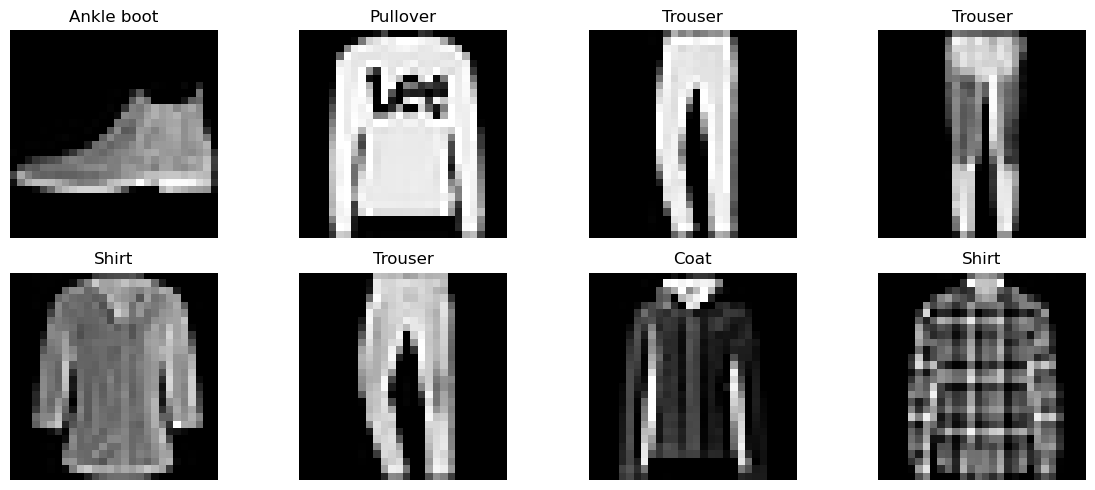

cifar10 split:
  model training: 49,488
  validation / PGD grid: 512
  official test (reporting only): 10,000
cifar10 samples: 10000


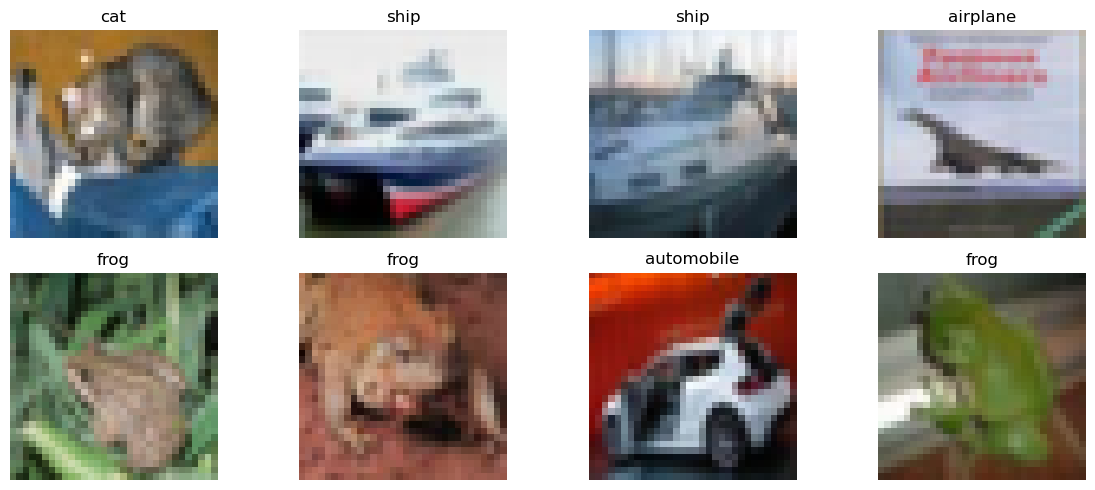

In [8]:
def show_dataset_samples(
    dataset_name: str,
    dataset: Dataset,
    n: int = 8,
) -> None:
    """Display a small set of samples from a dataset."""
    spec = DATASET_SPECS[dataset_name]
    n = min(n, len(dataset))

    rows = 2
    columns = math.ceil(n / rows)

    figure, axes = plt.subplots(
        rows,
        columns,
        figsize=(12, 5),
    )

    axes = np.asarray(axes).reshape(-1)

    for index in range(n):
        image, label = dataset[index]

        if image.shape[0] == 1:
            image_np = image.squeeze(0).numpy()
            axes[index].imshow(image_np, cmap="gray")
        else:
            image_np = image.permute(1, 2, 0).numpy()
            axes[index].imshow(image_np)

        axes[index].set_title(
            spec.class_names[int(label)]
        )
        axes[index].axis("off")

    # Hide unused axes when n does not fill the grid.
    for index in range(n, len(axes)):
        axes[index].axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(figure)


# Preview datasets without creating DataLoader workers.
for dataset_name in DATASETS_TO_RUN:
    _, _, _, preview_test = build_datasets(dataset_name)

    print(
        f"{dataset_name} samples: "
        f"{len(preview_test)}"
    )

    show_dataset_samples(
        dataset_name,
        preview_test,
        n=8,
    )

## Training and clean evaluation utilities

In [ ]:
# Store the per-epoch optimization, evaluation, and timing metrics.
@dataclass
class EpochRecord:
    epoch: int
    train_objective_loss: float
    train_loss: float
    validation_loss: float
    test_loss: float
    train_accuracy: float
    validation_accuracy: float
    test_accuracy: float
    elapsed_seconds: float


def make_optimizer_and_scheduler(
    model: nn.Module,
    spec: DatasetSpec,
    epochs: int,
    learning_rate_override: Optional[float] = None,
):
    # Use the dataset default learning rate unless an explicit override is provided.
    learning_rate = spec.learning_rate if learning_rate_override is None else learning_rate_override
    # Build the optimizer configured for the selected dataset.
    if spec.optimizer_name == "Adam":
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=learning_rate,
            weight_decay=spec.weight_decay,
        )
    elif spec.optimizer_name == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=learning_rate,
            momentum=spec.momentum,
            weight_decay=spec.weight_decay,
            nesterov=True,
        )
    else:
        raise ValueError(spec.optimizer_name)
    # Decay the learning rate smoothly over the complete training run.
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=max(1, epochs),
    )
    return optimizer, scheduler, learning_rate


@torch.inference_mode()
def evaluate_model(
    model: nn.Module,
    loader: DataLoader,
    max_samples: Optional[int] = None,
) -> dict[str, Any]:
    # Disable training-specific behavior such as dropout and batch-statistic updates.
    model.eval()
    # Accumulate sample-level totals so the final metrics remain batch-size independent.
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    labels_all: list[torch.Tensor] = []
    predictions_all: list[torch.Tensor] = []

    for images, labels in loader:
        # Truncate the final processed batch when a sample limit is requested.
        if max_samples is not None:
            remaining = max_samples - total_samples
            if remaining <= 0:
                break
            images = images[:remaining]
            labels = labels[:remaining]

        # Transfer the current batch to the configured execution device.
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        logits = model(images)
        # Sum per-sample losses so the dataset-wide mean can be computed exactly.
        losses = F.cross_entropy(logits, labels, reduction="sum")
        predictions = logits.argmax(dim=1)

        # Retain aggregate metrics and CPU predictions for downstream analysis.
        total_loss += float(losses.item())
        total_correct += int((predictions == labels).sum().item())
        total_samples += labels.size(0)
        labels_all.append(labels.cpu())
        predictions_all.append(predictions.cpu())

    # Guard against division by zero when the loader yields no samples.
    return {
        "loss": total_loss / max(total_samples, 1),
        "accuracy": total_correct / max(total_samples, 1),
        "n_samples": total_samples,
        "y_true": torch.cat(labels_all).numpy() if labels_all else np.array([]),
        "y_pred": torch.cat(predictions_all).numpy() if predictions_all else np.array([]),
    }


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    adversarial_builder: Optional[Callable[[nn.Module, torch.Tensor, torch.Tensor], torch.Tensor]] = None,
    clean_loss_weight: float = 0.0,
) -> float:
    # Validate the interpolation weight used for clean and adversarial losses.
    if not 0.0 <= clean_loss_weight <= 1.0:
        raise ValueError("clean_loss_weight must be between 0 and 1.")

    # Enable training behavior and initialize sample-weighted loss tracking.
    model.train()
    running_loss = 0.0
    seen = 0

    for images, labels in tqdm(loader, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        # Clear stale gradients before constructing the current optimization objective.
        optimizer.zero_grad(set_to_none=True)
        # Train on clean inputs when no adversarial example builder is supplied.
        if adversarial_builder is None:
            logits = model(images)
            loss = F.cross_entropy(logits, labels)
        else:
            # Detach generated adversarial inputs so only model parameters receive updates.
            adversarial = adversarial_builder(model, images, labels).detach()
            adversarial_logits = model(adversarial)
            adversarial_loss = F.cross_entropy(adversarial_logits, labels)
            # Optionally blend clean and adversarial objectives.
            if clean_loss_weight > 0:
                clean_logits = model(images)
                clean_loss = F.cross_entropy(clean_logits, labels)
                loss = clean_loss_weight * clean_loss + (1.0 - clean_loss_weight) * adversarial_loss
            else:
                loss = adversarial_loss

        # Backpropagate the selected objective and update model parameters.
        loss.backward()
        optimizer.step()

        # Weight each batch loss by its sample count before epoch averaging.
        running_loss += float(loss.item()) * labels.size(0)
        seen += labels.size(0)

    return running_loss / max(seen, 1)


def _start_cuda_peak_monitor() -> dict[str, float]:
    # Return unavailable CUDA metrics explicitly when training runs without a GPU.
    if not torch.cuda.is_available():
        return {
            "gpu_allocated_at_stage_start_mb": float("nan"),
            "gpu_reserved_at_stage_start_mb": float("nan"),
        }

    # Clear cached blocks, synchronize pending work, and reset CUDA peak statistics.
    torch.cuda.empty_cache()
    torch.cuda.synchronize(DEVICE)
    torch.cuda.reset_peak_memory_stats(DEVICE)
    # Capture allocator usage before the measured training stage begins.
    return {
        "gpu_allocated_at_stage_start_mb": torch.cuda.memory_allocated(DEVICE) / 1024**2,
        "gpu_reserved_at_stage_start_mb": torch.cuda.memory_reserved(DEVICE) / 1024**2,
    }


def _finish_cuda_peak_monitor(start_metrics: dict[str, float]) -> dict[str, float]:
    # Preserve the starting metrics while marking peak values as unavailable on CPU.
    if not torch.cuda.is_available():
        return {
            **start_metrics,
            "peak_gpu_allocated_mb": float("nan"),
            "peak_gpu_reserved_mb": float("nan"),
            "gpu_peak_increment_mb": float("nan"),
        }

    # Synchronize before reading the final CUDA peak allocator statistics.
    torch.cuda.synchronize(DEVICE)
    peak_allocated = torch.cuda.max_memory_allocated(DEVICE) / 1024**2
    peak_reserved = torch.cuda.max_memory_reserved(DEVICE) / 1024**2
    # Report both raw peaks and the allocation increase relative to stage start.
    return {
        **start_metrics,
        "peak_gpu_allocated_mb": peak_allocated,
        "peak_gpu_reserved_mb": peak_reserved,
        "gpu_peak_increment_mb": max(
            0.0,
            peak_allocated - start_metrics["gpu_allocated_at_stage_start_mb"],
        ),
    }


def fit_model(
    dataset_name: str,
    model_key: str,
    model: nn.Module,
    train_loader: DataLoader,
    train_eval_loader: DataLoader,
    validation_loader: DataLoader,
    epochs: int,
    epoch_test_loader: Optional[DataLoader] = None,
    adversarial_builder: Optional[Callable[[nn.Module, torch.Tensor, torch.Tensor], torch.Tensor]] = None,
    clean_loss_weight: float = 0.0,
    learning_rate_override: Optional[float] = None,
    force_retrain: bool = False,
) -> tuple[nn.Module, pd.DataFrame, dict[str, Any]]:
    # Resolve dataset settings and the artifact paths for this model run.
    spec = DATASET_SPECS[dataset_name]
    training_batch_size = int(train_loader.batch_size or 1)
    output_dir = RESULTS_ROOT / dataset_name / model_key
    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = output_dir / "model.pt"
    history_path = output_dir / "history.csv"
    timing_path = output_dir / "training_cost.json"
    metadata_path = output_dir / "training_metadata.json"

    # Define the minimum history schema required to reuse cached training artifacts.
    required_history_columns = {
        "epoch",
        "train_objective_loss",
        "train_loss",
        "validation_loss",
        "train_accuracy",
        "validation_accuracy",
        "elapsed_seconds",
    }
    if epoch_test_loader is not None:
        required_history_columns.update({"test_loss", "test_accuracy"})

    # Reuse an existing run only when all required artifacts are present and retraining is not forced.
    if (
        checkpoint_path.exists()
        and history_path.exists()
        and timing_path.exists()
        and not force_retrain
    ):
        # Validate cached history and memory metadata before loading the checkpoint.
        history = pd.read_csv(history_path)
        training_cost = json.loads(timing_path.read_text())
        history_is_current = required_history_columns.issubset(history.columns)
        memory_is_current = (
            "peak_gpu_allocated_mb" in training_cost
            and "gpu_peak_increment_mb" in training_cost
            and "model_storage_mb" in training_cost
            and "estimated_isolated_peak_gpu_mb"
            in training_cost
            and training_cost.get(
                "gpu_memory_measurement_method"
            )
            == "model_storage_plus_peak_increment"
        )
        # Restore the cached model only when its companion artifacts match the current schema.
        if history_is_current and memory_is_current:
            model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
            print(f"Loaded current checkpoint: {checkpoint_path}")
            return model, history, training_cost
        print(f"Stale training artifacts detected for {dataset_name}/{model_key}; retraining.")

    # Begin measuring CUDA usage before optimizer and training-state allocation.
    cuda_start = _start_cuda_peak_monitor()

    # Initialize optimization components and retain the effective learning rate for metadata.
    optimizer, scheduler, effective_lr = make_optimizer_and_scheduler(
        model,
        spec,
        epochs,
        learning_rate_override=learning_rate_override,
    )
    # Track epoch records and isolate optional test-reporting time from training cost.
    records: list[EpochRecord] = []
    test_reporting_seconds = 0.0
    start = time.perf_counter()

    # Train, schedule, and evaluate once per epoch.
    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        objective_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            adversarial_builder=adversarial_builder,
            clean_loss_weight=clean_loss_weight,
        )
        # Advance the learning-rate schedule after completing the epoch update.
        scheduler.step()

        # Clean evaluation losses are directly comparable across splits.
        train_metrics = evaluate_model(model, train_eval_loader)
        validation_metrics = evaluate_model(model, validation_loader)
        # Evaluate the official test split only when epoch-level reporting is requested.
        if epoch_test_loader is not None:
            test_reporting_start = time.perf_counter()
            test_metrics = evaluate_model(model, epoch_test_loader)
            test_reporting_seconds += (
                time.perf_counter() - test_reporting_start
            )
        else:
            test_metrics = {
                "loss": float("nan"),
                "accuracy": float("nan"),
            }

        # Store all clean evaluation metrics and the total epoch duration.
        record = EpochRecord(
            epoch=epoch,
            train_objective_loss=float(objective_loss),
            train_loss=float(train_metrics["loss"]),
            validation_loss=float(validation_metrics["loss"]),
            test_loss=float(test_metrics["loss"]),
            train_accuracy=float(train_metrics["accuracy"]),
            validation_accuracy=float(validation_metrics["accuracy"]),
            test_accuracy=float(test_metrics["accuracy"]),
            elapsed_seconds=time.perf_counter() - epoch_start,
        )
        records.append(record)

        # Build a concise progress message with optional test metrics.
        message = (
            f"[{dataset_name} | {model_key}] epoch {epoch:02d}/{epochs} - "
            f"objective_loss={record.train_objective_loss:.4f}, "
            f"clean_train_loss={record.train_loss:.4f}, "
            f"validation_loss={record.validation_loss:.4f}, "
            f"train_acc={record.train_accuracy:.4f}, "
            f"validation_acc={record.validation_accuracy:.4f}"
        )
        if epoch_test_loader is not None:
            message += (
                f", test_loss={record.test_loss:.4f}, "
                f"test_acc={record.test_accuracy:.4f}"
            )
        print(message)

    # Ensure all asynchronous CUDA work is complete before final timing.
    if torch.cuda.is_available():
        torch.cuda.synchronize(DEVICE)

    # Exclude reporting-only test evaluation from the primary training-time metric.
    stage_wall_clock_seconds = time.perf_counter() - start
    stage_training_seconds = max(
        0.0,
        stage_wall_clock_seconds - test_reporting_seconds,
    )
    # Finalize the peak-memory statistics for the measured stage.
    gpu_metrics = _finish_cuda_peak_monitor(cuda_start)

    # Measure persistent parameter and buffer storage separately from training allocations.
    current_model_storage_mb = model_storage_mb(model)

    # Estimate an isolated peak by combining model storage with incremental CUDA usage.
    estimated_isolated_peak_gpu_mb = (
        current_model_storage_mb
        + float(gpu_metrics["gpu_peak_increment_mb"])
    )
    # Assemble timing, device, and memory metrics for later comparisons.
    training_cost = {
        "stage_training_seconds": (
            stage_training_seconds
        ),

        "stage_wall_clock_seconds": (
            stage_wall_clock_seconds
        ),

        "baseline_test_reporting_seconds": (
            test_reporting_seconds
        ),

        "seconds_per_epoch": (
            stage_training_seconds / max(epochs, 1)
        ),

        "batch_size": training_batch_size,
        "device": str(DEVICE),

        "gpu_name": (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else None
        ),

        # Memory occupied by this model's parameters and buffers.
        "model_storage_mb": (
            current_model_storage_mb
        ),

        # Fairer cross-defense comparison:
        # model storage + additional training allocations.
        "estimated_isolated_peak_gpu_mb": (
            estimated_isolated_peak_gpu_mb
        ),

        "gpu_memory_measurement_method": (
            "model_storage_plus_peak_increment"
        ),

        "primary_gpu_memory_metric": (
            "estimated_isolated_peak_gpu_mb"
        ),

        # Raw CUDA statistics retained for diagnostics.
        **gpu_metrics,
    }

    # Persist the epoch history, trained weights, and training-cost report.
    history = pd.DataFrame([asdict(record) for record in records])
    history.to_csv(history_path, index=False)
    torch.save(model.state_dict(), checkpoint_path)
    timing_path.write_text(
        json.dumps(training_cost, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    # Record the complete training configuration and the role of the test split.
    metadata_path.write_text(
        json.dumps(
            {
                "optimizer": spec.optimizer_name,
                "effective_learning_rate": effective_lr,
                "weight_decay": spec.weight_decay,
                "momentum": spec.momentum,
                "epochs": epochs,
                "batch_size": training_batch_size,
                "clean_loss_weight": clean_loss_weight,
                "adversarial_training": adversarial_builder is not None,
                "seed": SEED,
                "epoch_monitoring_split": "held_out_validation",
                "official_test_evaluated_each_epoch": epoch_test_loader is not None,
                "official_test_role": (
                    "reporting_only_not_used_for_any_training_or_selection_decision"
                    if epoch_test_loader is not None
                    else "final_evaluation_only"
                ),
                "loss_definition": (
                    "train_loss, validation_loss, and test_loss are clean "
                    "evaluation-mode cross-entropy losses; "
                    "train_objective_loss is the optimization loss."
                ),
            },
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    # Print the primary timing and memory summary for this run.
    print(
        f"[{dataset_name} | {model_key}] "
        f"training cost - "
        f"training_time="
        f"{stage_training_seconds:.2f}s, "
        f"model_storage="
        f"{training_cost['model_storage_mb']:.2f} MB, "
        f"training_increment="
        f"{training_cost['gpu_peak_increment_mb']:.2f} MB, "
        f"estimated_isolated_peak="
        f"{training_cost['estimated_isolated_peak_gpu_mb']:.2f} MB"
    )

    # Release only training-specific states. The trained model intentionally
    # remains on DEVICE for the later robustness and explainability audits.
    model.eval()
    model.zero_grad(set_to_none=True)
    del optimizer
    del scheduler
    cleanup_cuda()

    return model, history, training_cost


In [10]:
def plot_training_history(history: pd.DataFrame, dataset_name: str, model_key: str) -> None:
    output_dir = RESULTS_ROOT / dataset_name / model_key
    output_dir.mkdir(parents=True, exist_ok=True)
    spec = DATASET_SPECS[dataset_name]

    has_test_history = (
        "test_loss" in history.columns
        and history["test_loss"].notna().any()
        and "test_accuracy" in history.columns
        and history["test_accuracy"].notna().any()
    )

    # Required Q5-A figures are generated directly from the main baseline run.
    if model_key == "baseline" and has_test_history:
        figure, axis = plt.subplots(figsize=(8, 5))
        axis.plot(
            history["epoch"],
            history["train_loss"],
            marker="o",
            linewidth=2,
            label="Clean Train Loss",
        )
        axis.plot(
            history["epoch"],
            history["test_loss"],
            marker="o",
            linewidth=2,
            label="Clean Test Loss",
        )
        axis.set_xlabel("Epoch")
        axis.set_ylabel("Cross-Entropy Loss")
        axis.set_title(f"{spec.display_name} Baseline — Train/Test Loss by Epoch")
        axis.set_xticks(history["epoch"].astype(int).tolist())
        axis.grid(alpha=0.25)
        axis.legend()
        figure.tight_layout()
        figure.savefig(
            output_dir / "baseline_train_test_loss_by_epoch.png",
            dpi=220,
            bbox_inches="tight",
            facecolor="white",
        )
        plt.show()
        plt.close(figure)

        figure, axis = plt.subplots(figsize=(8, 5))
        axis.plot(
            history["epoch"],
            history["train_accuracy"],
            marker="o",
            linewidth=2,
            label="Clean Train Accuracy",
        )
        axis.plot(
            history["epoch"],
            history["test_accuracy"],
            marker="o",
            linewidth=2,
            label="Clean Test Accuracy",
        )
        axis.set_xlabel("Epoch")
        axis.set_ylabel("Accuracy")
        axis.set_ylim(0, 1)
        axis.set_title(f"{spec.display_name} Baseline — Train/Test Accuracy by Epoch")
        axis.set_xticks(history["epoch"].astype(int).tolist())
        axis.grid(alpha=0.25)
        axis.legend()
        figure.tight_layout()
        figure.savefig(
            output_dir / "baseline_train_test_accuracy_by_epoch.png",
            dpi=220,
            bbox_inches="tight",
            facecolor="white",
        )
        plt.show()
        plt.close(figure)

    # Diagnostic loss figure: optimization objective plus clean evaluation losses.
    figure, axis = plt.subplots(figsize=(8, 5))
    axis.plot(
        history["epoch"],
        history["train_objective_loss"],
        marker="o",
        label="Training Objective Loss",
    )
    axis.plot(
        history["epoch"],
        history["train_loss"],
        marker="o",
        label="Clean Train Loss",
    )
    axis.plot(
        history["epoch"],
        history["validation_loss"],
        marker="o",
        label="Clean Validation Loss",
    )
    if has_test_history:
        axis.plot(
            history["epoch"],
            history["test_loss"],
            marker="o",
            label="Clean Test Loss (reporting only)",
        )
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Loss")
    axis.set_title(f"{spec.display_name} — {model_key} loss history")
    axis.grid(alpha=0.25)
    axis.legend()
    figure.tight_layout()
    figure.savefig(output_dir / "loss_curve.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(8, 5))
    axis.plot(
        history["epoch"],
        history["train_accuracy"],
        marker="o",
        label="Clean Train Accuracy",
    )
    axis.plot(
        history["epoch"],
        history["validation_accuracy"],
        marker="o",
        label="Clean Validation Accuracy",
    )
    if has_test_history:
        axis.plot(
            history["epoch"],
            history["test_accuracy"],
            marker="o",
            label="Clean Test Accuracy (reporting only)",
        )
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Accuracy")
    axis.set_ylim(0, 1)
    axis.set_title(f"{spec.display_name} — {model_key} accuracy history")
    axis.grid(alpha=0.25)
    axis.legend()
    figure.tight_layout()
    figure.savefig(output_dir / "accuracy_curve.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figure)


def plot_confusion_matrix_for_model(
    metrics: dict[str, Any],
    dataset_name: str,
    model_key: str,
) -> None:
    spec = DATASET_SPECS[dataset_name]

    matrix = confusion_matrix(
        metrics["y_true"],
        metrics["y_pred"],
        labels=np.arange(spec.num_classes),
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=spec.class_names,
    )

    figure, axis = plt.subplots(figsize=(10, 9))
    display_cm.plot(
        ax=axis,
        xticks_rotation=45,
        colorbar=False,
        cmap="Blues",
    )
    axis.set_title(f"{spec.display_name} - {model_key} clean confusion matrix")
    figure.tight_layout()

    output_dir = RESULTS_ROOT / dataset_name / model_key
    output_dir.mkdir(parents=True, exist_ok=True)
    figure.savefig(
        output_dir / "clean_confusion_matrix.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(figure)


## Custom FGSM and PGD implementations

The functions below are implemented directly rather than delegated to an attack library. Both return the adversarial image, perturbation, and model output, and both operate in the original pixel range.

In [ ]:
def FGSM(
    model: nn.Module,
    images: torch.Tensor,
    labels: torch.Tensor,
    epsilon: float,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Generate an untargeted L-infinity FGSM attack in the original [0, 1] pixel domain."""
    # Preserve the model's original training state during attack generation.
    was_training = model.training
    model.eval()

    # Create a detached clean reference and enable gradients only for the attack input.
    clean = images.detach()
    attack_input = clean.clone().requires_grad_(True)
    logits = model(attack_input)
    loss = F.cross_entropy(logits, labels)
    gradient = torch.autograd.grad(loss, attack_input, only_inputs=True)[0]

    # Move each pixel in the gradient-sign direction and clamp it to the valid pixel range.
    adversarial = torch.clamp(clean + epsilon * gradient.sign(), 0.0, 1.0).detach()
    perturbation = (adversarial - clean).detach()
    # Evaluate the generated adversarial examples without building another gradient graph.
    with torch.no_grad():
        adversarial_output = model(adversarial).detach()

    # Restore the model's original training or evaluation state.
    model.train(was_training)
    return adversarial, perturbation, adversarial_output


def RandomStartFGSM(
    model: nn.Module,
    images: torch.Tensor,
    labels: torch.Tensor,
    epsilon: float,
    alpha: float,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """One-step FGSM from a random point in the L-infinity ball, followed by projection."""
    # Preserve the model's original training state during attack generation.
    was_training = model.training
    model.eval()
    clean = images.detach()

    # Initialize the attack from a random point inside the epsilon-bounded region.
    initial = clean + torch.empty_like(clean).uniform_(-epsilon, epsilon)
    initial = torch.clamp(initial, 0.0, 1.0).detach().requires_grad_(True)
    logits = model(initial)
    loss = F.cross_entropy(logits, labels)
    gradient = torch.autograd.grad(loss, initial, only_inputs=True)[0]

    # Take one gradient-sign step, project into the L-infinity ball, and clamp valid pixels.
    adversarial = initial.detach() + alpha * gradient.sign()
    delta = torch.clamp(adversarial - clean, min=-epsilon, max=epsilon)
    adversarial = torch.clamp(clean + delta, 0.0, 1.0).detach()
    perturbation = adversarial - clean
    # Evaluate the final adversarial examples without tracking gradients.
    with torch.no_grad():
        output = model(adversarial).detach()

    # Restore the model's original training or evaluation state.
    model.train(was_training)
    return adversarial, perturbation.detach(), output


def PGD(
    model: nn.Module,
    images: torch.Tensor,
    labels: torch.Tensor,
    epsilon: float,
    alpha: float,
    steps: int,
    random_restarts: int,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Generate a multi-restart untargeted L-infinity PGD attack."""
    # Require at least one attack initialization.
    if random_restarts < 1:
        raise ValueError("random_restarts must be at least 1")

    # Preserve the model's original training state during attack generation.
    was_training = model.training
    model.eval()
    clean = images.detach()
    # Track the strongest adversarial example independently for every sample.
    best_adversarial = clean.clone()
    best_loss = torch.full((clean.size(0),), -float("inf"), device=clean.device)

    # Run PGD from multiple random initial points.
    for _ in range(random_restarts):
        adversarial = clean + torch.empty_like(clean).uniform_(-epsilon, epsilon)
        adversarial = torch.clamp(adversarial, 0.0, 1.0).detach()

        # Repeatedly ascend the loss and project back into the allowed perturbation region.
        for _ in range(steps):
            adversarial.requires_grad_(True)
            logits = model(adversarial)
            loss = F.cross_entropy(logits, labels)
            gradient = torch.autograd.grad(loss, adversarial, only_inputs=True)[0]

            adversarial = adversarial.detach() + alpha * gradient.sign()
            delta = torch.clamp(adversarial - clean, min=-epsilon, max=epsilon)
            adversarial = torch.clamp(clean + delta, 0.0, 1.0).detach()

        # Retain the restart that produces the highest loss for each individual sample.
        with torch.no_grad():
            final_logits = model(adversarial)
            per_sample_loss = F.cross_entropy(final_logits, labels, reduction="none")
            stronger = per_sample_loss > best_loss
            best_loss[stronger] = per_sample_loss[stronger]
            best_adversarial[stronger] = adversarial[stronger]

    # Compute model outputs for the strongest selected adversarial examples.
    with torch.no_grad():
        best_output = model(best_adversarial).detach()

    # Restore the model's original training or evaluation state.
    model.train(was_training)
    return best_adversarial.detach(), (best_adversarial - clean).detach(), best_output

In [ ]:
def collect_fixed_samples(
    loader: DataLoader,
    n_samples: Optional[int] = None,
) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Collect a deterministic prefix from a non-shuffled loader.

    When n_samples is None, every sample in loader.dataset is collected.
    """
    # Limit the requested sample count to the number available in the dataset.
    available_samples = len(loader.dataset)
    target_samples = (
        available_samples
        if n_samples is None
        else min(int(n_samples), available_samples)
    )

    if target_samples <= 0:
        raise ValueError("At least one sample is required.")

    # Accumulate CPU tensors until the requested number of samples is reached.
    images_all: list[torch.Tensor] = []
    labels_all: list[torch.Tensor] = []
    collected = 0

    for images, labels in loader:
        remaining = target_samples - collected
        if remaining <= 0:
            break

        # Take only the portion of the current batch still required.
        take_count = min(remaining, labels.size(0))
        images_all.append(images[:take_count].cpu())
        labels_all.append(labels[:take_count].cpu())
        collected += take_count

    # Verify that the loader provided the complete requested prefix.
    if collected != target_samples:
        raise RuntimeError(
            f"Requested {target_samples} samples, but collected {collected}."
        )

    return torch.cat(images_all, dim=0), torch.cat(labels_all, dim=0)



def evaluate_attack(
    model: nn.Module,
    loader: DataLoader,
    attack_builder: Callable[[nn.Module, torch.Tensor, torch.Tensor], tuple[torch.Tensor, torch.Tensor, torch.Tensor]],
    max_samples: Optional[int] = None,
) -> dict[str, float]:
    # Evaluate attacks with deterministic inference behavior.
    model.eval()
    total_correct = 0
    total_samples = 0
    total_linf = 0.0
    start = time.perf_counter()

    for images, labels in loader:
        # Truncate the final processed batch when a sample limit is specified.
        if max_samples is not None:
            remaining = max_samples - total_samples
            if remaining <= 0:
                break
            images = images[:remaining]
            labels = labels[:remaining]

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        # Generate adversarial inputs and classify them with the attacked model.
        adversarial, perturbation, output = attack_builder(model, images, labels)
        predictions = output.argmax(dim=1)

        # Accumulate robust correctness and per-sample L-infinity perturbation norms.
        total_correct += int((predictions == labels).sum().item())
        total_samples += labels.size(0)
        total_linf += float(perturbation.abs().flatten(1).max(dim=1).values.sum().item())

    # Report aggregate robustness, perturbation magnitude, sample count, and runtime.
    return {
        "robust_accuracy": total_correct / max(total_samples, 1),
        "mean_linf": total_linf / max(total_samples, 1),
        "n_samples": total_samples,
        "attack_seconds": time.perf_counter() - start,
    }


def evaluate_fgsm_sweep(
    model: nn.Module,
    loader: DataLoader,
    epsilons: Iterable[float],
    max_samples: Optional[int] = None,
) -> pd.DataFrame:
    # Evaluate FGSM independently for every requested perturbation budget.
    records = []
    for epsilon in epsilons:
        metrics = evaluate_attack(
            model,
            loader,
            attack_builder=lambda current_model, x, y, eps=epsilon: FGSM(current_model, x, y, eps),
            max_samples=max_samples,
        )
        records.append({"epsilon": epsilon, **metrics})
        print(f"FGSM epsilon={epsilon:.6f} -> robust_accuracy={metrics['robust_accuracy']:.4f}")
    return pd.DataFrame(records)

In [ ]:
def pgd_grid_search(
    model: nn.Module,
    search_loader: DataLoader,
    dataset_name: str,
    search_samples: Optional[int] = None,
    tolerance: float = 0.005,
) -> tuple[pd.DataFrame, dict[str, Any], dict[str, Any]]:
    """
    Evaluate every assignment-required alpha/step combination on a fixed
    held-out validation split drawn from the official training partition.

    Returns:
        table:
            Results for all nine configurations.

        strongest:
            Configuration with the lowest validation robust accuracy.

        compute_aware:
            Cheapest configuration within `tolerance` of the strongest
            validation robust accuracy.
    """
    # Collect the same deterministic validation samples for every configuration.
    fixed_images, fixed_labels = collect_fixed_samples(
        search_loader,
        search_samples,
    )

    # Rebuild a non-shuffled loader so all PGD configurations use identical inputs.
    fixed_loader = DataLoader(
        TensorDataset(fixed_images, fixed_labels),
        batch_size=DATASET_SPECS[dataset_name].batch_size,
        shuffle=False,
    )

    actual_search_samples = len(fixed_loader.dataset)
    records = []

    # Evaluate the Cartesian product of all required PGD step sizes and iteration counts.
    for alpha in PGD_ALPHAS:
        for steps in PGD_STEPS:
            metrics = evaluate_attack(
                model,
                fixed_loader,
                attack_builder=lambda current_model, x, y, a=alpha, s=steps: PGD(
                    current_model,
                    x,
                    y,
                    epsilon=PGD_EPSILON,
                    alpha=a,
                    steps=s,
                    random_restarts=PGD_SEARCH_RESTARTS,
                ),
            )

            # Store both attack parameters and measured validation results.
            records.append({
                "search_split": "heldout_validation_from_official_train",
                "official_test_used_for_selection": False,
                "validation_dataset_size": len(search_loader.dataset),
                "search_samples": actual_search_samples,
                "epsilon": PGD_EPSILON,
                "alpha": alpha,
                "steps": steps,
                "restarts": PGD_SEARCH_RESTARTS,
                "gradient_steps_per_sample": steps * PGD_SEARCH_RESTARTS,
                **metrics,
            })

            print(
                f"Validation PGD alpha={alpha:.6f}, steps={steps}, "
                f"restarts={PGD_SEARCH_RESTARTS}, n={actual_search_samples} "
                f"-> robust_accuracy={metrics['robust_accuracy']:.4f}"
            )

    # Rank attacks by strength first, then by computational cost and step size.
    table = pd.DataFrame(records).sort_values(
        ["robust_accuracy", "gradient_steps_per_sample", "alpha"],
        ascending=[True, True, True],
    ).reset_index(drop=True)

    # The lowest robust accuracy identifies the strongest validation attack.
    strongest = table.iloc[0].to_dict()

    # Retain configurations whose robust accuracy is within the allowed tolerance.
    near_strongest = table[
        table["robust_accuracy"]
        <= strongest["robust_accuracy"] + tolerance
    ]

    # Select the least expensive configuration among attacks near the strongest result.
    compute_aware = near_strongest.sort_values(
        ["gradient_steps_per_sample", "attack_seconds", "robust_accuracy"]
    ).iloc[0].to_dict()

    # Create the directory used to persist attack-search artifacts.
    output_dir = RESULTS_ROOT / dataset_name / "attacks"
    output_dir.mkdir(parents=True, exist_ok=True)

    # Save the complete ranked grid-search table.
    table.to_csv(
        output_dir / "pgd_grid_search_validation.csv",
        index=False,
    )

    # Record the selection policy and both chosen configurations.
    selection_metadata = {
        "dataset": dataset_name,
        "selection_split": "heldout_validation_from_official_train",
        "official_test_used_for_selection": False,
        "validation_dataset_size": int(len(search_loader.dataset)),
        "search_samples": int(actual_search_samples),
        "strongest_validation_configuration": strongest,
        "compute_aware_validation_configuration": compute_aware,
    }

    # Persist the grid-search selection metadata in a readable JSON file.
    (output_dir / "pgd_grid_selection_metadata.json").write_text(
        json.dumps(selection_metadata, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    return table, strongest, compute_aware

In [ ]:
def plot_fgsm_curve(table: pd.DataFrame, dataset_name: str, model_key: str) -> None:
    # Create and save the robust-accuracy curve across FGSM perturbation budgets.
    output_dir = RESULTS_ROOT / dataset_name / model_key
    plt.figure(figsize=(7, 4))
    plt.plot(table["epsilon"] * 255, table["robust_accuracy"], marker="o")
    plt.xlabel("FGSM epsilon × 255")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1)
    plt.title(f"{DATASET_SPECS[dataset_name].display_name} - {model_key} FGSM sweep")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_dir / "fgsm_accuracy_curve.png", dpi=180)
    plt.show()
    plt.close()


def collect_successful_attack_examples(
    model: nn.Module,
    loader: DataLoader,
    attack_builder: Callable[[nn.Module, torch.Tensor, torch.Tensor], tuple[torch.Tensor, torch.Tensor, torch.Tensor]],
    n: int,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Prefer examples that are clean-correct and become incorrect after the attack."""
    # Store successful attacks separately from clean-correct fallback examples.
    successful, fallback = [], []
    model.eval()

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        # Compute clean predictions without retaining a gradient graph.
        with torch.no_grad():
            clean_logits = model(images)
            clean_predictions = clean_logits.argmax(dim=1)
        # Generate adversarial examples and obtain their corresponding predictions.
        adversarial, perturbation, adversarial_logits = attack_builder(model, images, labels)
        adversarial_predictions = adversarial_logits.argmax(dim=1)

        # Categorize each clean-correct example according to whether the attack succeeds.
        for index in range(labels.size(0)):
            item = (
                images[index].detach().cpu(), labels[index].detach().cpu(),
                clean_logits[index].detach().cpu(), adversarial[index].detach().cpu(),
                perturbation[index].detach().cpu(), adversarial_logits[index].detach().cpu(),
            )
            if clean_predictions[index] == labels[index] and adversarial_predictions[index] != labels[index]:
                successful.append(item)
            elif clean_predictions[index] == labels[index]:
                fallback.append(item)
        # Stop once enough successful examples have been collected.
        if len(successful) >= n:
            break

    # Prioritize successful attacks and fill any remaining positions with fallback examples.
    chosen = (successful + fallback)[:n]
    if not chosen:
        raise RuntimeError("No clean-correct examples were available for visualization.")
    # Convert the list of example tuples into one stacked tensor per tuple field.
    columns = list(zip(*chosen))
    return tuple(torch.stack(column) for column in columns)  # type: ignore[return-value]


def visualize_attack_triplets(
    dataset_name: str,
    model: nn.Module,
    loader: DataLoader,
    attack_name: str,
    attack_builder: Callable[[nn.Module, torch.Tensor, torch.Tensor], tuple[torch.Tensor, torch.Tensor, torch.Tensor]],
    n: int = 5,
) -> None:
    # Collect representative clean, perturbation, and adversarial tensors.
    spec = DATASET_SPECS[dataset_name]
    images, labels, clean_logits, adversarial, perturbation, adversarial_logits = collect_successful_attack_examples(
        model, loader, attack_builder, n
    )
    n = images.size(0)

    # Convert logits into probabilities and predicted class indices.
    clean_probabilities = clean_logits.softmax(dim=1)
    adversarial_probabilities = adversarial_logits.softmax(dim=1)
    clean_predictions = clean_logits.argmax(dim=1)
    adversarial_predictions = adversarial_logits.argmax(dim=1)

    # Create one row per example with clean, perturbation, and adversarial columns.
    figure, axes = plt.subplots(n, 3, figsize=(10, 3.25 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for row in range(n):
        clean = images[row]
        delta = perturbation[row]
        adv = adversarial[row]

        # Convert channel-first tensors into formats accepted by Matplotlib.
        clean_display = clean.squeeze(0).numpy() if clean.shape[0] == 1 else clean.permute(1, 2, 0).numpy()
        adversarial_display = adv.squeeze(0).numpy() if adv.shape[0] == 1 else adv.permute(1, 2, 0).numpy()
        delta_np = delta.squeeze(0).numpy() if delta.shape[0] == 1 else delta.permute(1, 2, 0).numpy()

        # Rescale the perturbation around 0.5 for visible positive and negative changes.
        scale = max(float(np.abs(delta_np).max()), 1e-12)
        perturb_display = np.clip(0.5 + delta_np / (2 * scale), 0.0, 1.0)
        linf = float(delta.abs().max())

        # Resolve class names and prediction confidence values for plot titles.
        true_name = spec.class_names[int(labels[row])]
        clean_name = spec.class_names[int(clean_predictions[row])]
        adv_name = spec.class_names[int(adversarial_predictions[row])]
        clean_conf = float(clean_probabilities[row, clean_predictions[row]])
        adv_conf = float(adversarial_probabilities[row, adversarial_predictions[row]])

        axes[row, 0].imshow(clean_display, cmap="gray" if clean.shape[0] == 1 else None)
        axes[row, 0].set_title(f"True: {true_name}\nClean pred: {clean_name} ({clean_conf:.2f})")
        axes[row, 1].imshow(perturb_display, cmap="seismic", vmin=0, vmax=1)
        axes[row, 1].set_title(f"Perturbation (display-rescaled)\nL∞={linf:.5f}")
        axes[row, 2].imshow(adversarial_display, cmap="gray" if adv.shape[0] == 1 else None)
        axes[row, 2].set_title(f"Adversarial pred: {adv_name} ({adv_conf:.2f})")
        # Hide axes to keep attention on the image triplets.
        for column in range(3):
            axes[row, column].axis("off")

    # Save the completed visualization in the dataset attack-results directory.
    figure.suptitle(f"{spec.display_name} - {attack_name}", y=1.005)
    figure.tight_layout()
    output_dir = RESULTS_ROOT / dataset_name / "attacks"
    output_dir.mkdir(parents=True, exist_ok=True)
    figure.savefig(output_dir / f"{attack_name.lower()}_examples.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figure)

## Adversarial-training defenses and computational cost

The mandatory defense is PGD adversarial training. The second defense is FGSM adversarial training with a random start inside the `L∞` ball. Both are initialized from the same baseline and use controlled, same-seed data streams.

Robustness is evaluated with FGSM, selected PGD, strong PGD, transfer attacks, EOT-PGD, and AutoAttack.


In [ ]:
def make_fgsm_training_builder(dataset_name: str):
    # Select the dataset-specific step size used by random-start FGSM training.
    alpha = FGSM_TRAIN_ALPHA[dataset_name]

    # Build an adversarial-example generator compatible with the training loop.
    def builder(model: nn.Module, images: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
        adversarial, _, _ = RandomStartFGSM(
            model, images, labels,
            epsilon=FGSM_TRAIN_EPSILON,
            alpha=alpha,
        )
        # Detach generated samples so the training loss creates a fresh computation graph.
        return adversarial.detach()

    return builder


def pgd_training_builder(model: nn.Module, images: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
    # Generate adversarial training samples with the configured PGD parameters.
    adversarial, _, _ = PGD(
        model,
        images,
        labels,
        epsilon=PGD_TRAIN_EPSILON,
        alpha=PGD_TRAIN_ALPHA,
        steps=PGD_TRAIN_STEPS,
        random_restarts=PGD_TRAIN_RESTARTS,
    )
    # Detach generated samples so gradients are computed only for the training update.
    return adversarial.detach()


def initialize_defense_from_baseline(dataset_name: str, baseline_model: nn.Module) -> nn.Module:
    # Create an independent defense model with the same architecture as the baseline.
    defense_model = build_model(dataset_name)
    # Initialize the defense from a deep copy of the trained baseline parameters.
    defense_model.load_state_dict(copy.deepcopy(baseline_model.state_dict()))
    return defense_model

## AutoAttack and gradient-masking audit

This section defines the strong-PGD step/restart audit, white-box versus transfer attacks, explicit EOT-PGD, and the full standard AutoAttack evaluation. EOT is executed for every model and compared against ordinary PGD on exactly the same test samples.


In [ ]:
def evaluate_autoattack(
    model: nn.Module,
    loader: DataLoader,
    dataset_name: str,
    max_samples: Optional[int],
) -> dict[str, Any]:
    # Retrieve dataset-specific class information required by AutoAttack.
    spec = DATASET_SPECS[dataset_name]
    # Require evaluation on the complete official test set in full execution mode.
    if EXECUTION_MODE == "full" and max_samples is not None:
        raise ValueError("Full-mode AutoAttack must use max_samples=None and the complete test set.")

    # Configure the standardized L-infinity AutoAttack suite.
    attack = torchattacks.AutoAttack(
        model,
        norm="Linf",
        eps=PGD_EPSILON,
        version=AUTOATTACK_VERSION,
        n_classes=spec.num_classes,
        seed=SEED,
        verbose=True,
    )

    # Initialize aggregate robustness and perturbation statistics.
    model.eval()
    total_correct = 0
    total_samples = 0
    total_linf = 0.0
    maximum_linf = 0.0
    start = time.perf_counter()

    for images, labels in tqdm(loader, desc=f"AutoAttack {dataset_name}"):
        # Truncate the final processed batch when a sample limit is specified.
        if max_samples is not None:
            remaining = max_samples - total_samples
            if remaining <= 0:
                break
            images = images[:remaining]
            labels = labels[:remaining]

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        # Generate adversarial examples using the configured attack suite.
        adversarial = attack(images, labels)
        perturbation_linf = (adversarial - images).abs().flatten(1).max(dim=1).values
        # Verify that every generated example respects the requested perturbation budget.
        if float(perturbation_linf.max()) > PGD_EPSILON + 1e-5:
            raise RuntimeError("AutoAttack produced an example outside the requested L-infinity ball.")
        # Evaluate adversarial predictions without retaining gradients.
        with torch.no_grad():
            predictions = model(adversarial).argmax(dim=1)
        # Accumulate robust correctness and perturbation statistics.
        total_correct += int((predictions == labels).sum().item())
        total_samples += labels.size(0)
        total_linf += float(perturbation_linf.sum().item())
        maximum_linf = max(maximum_linf, float(perturbation_linf.max().item()))

    # Confirm that the intended number of samples was evaluated.
    expected_samples = len(loader.dataset) if max_samples is None else min(max_samples, len(loader.dataset))
    if total_samples != expected_samples:
        raise RuntimeError(f"AutoAttack evaluated {total_samples} samples; expected {expected_samples}.")

    # Return aggregate robustness, attack configuration, perturbation, and runtime metrics.
    return {
        "robust_accuracy": total_correct / max(total_samples, 1),
        "n_samples": total_samples,
        "full_test_set": bool(max_samples is None),
        "suite_version": AUTOATTACK_VERSION,
        "suite_components": ", ".join(AUTOATTACK_COMPONENTS),
        "mean_linf": total_linf / max(total_samples, 1),
        "max_linf": maximum_linf,
        "attack_seconds": time.perf_counter() - start,
    }


def evaluate_transfer_pgd_multi_target(
    target_models: dict[str, nn.Module],
    surrogate_model: nn.Module,
    loader: DataLoader,
    alpha: float,
    steps: int,
    restarts: int,
    max_samples: Optional[int],
) -> pd.DataFrame:
    """Generate PGD once on an independent surrogate and test all targets."""
    # Ensure the surrogate is not one of the target model objects.
    if any(model is surrogate_model for model in target_models.values()):
        raise ValueError("The surrogate must be a separate model object.")

    # Use deterministic inference behavior for both surrogate and target models.
    surrogate_model.eval()
    for target_model in target_models.values():
        target_model.eval()

    # Track target-specific correctness and shared attack statistics.
    correct = {name: 0 for name in target_models}
    total_samples = 0
    maximum_linf = 0.0
    start = time.perf_counter()

    for images, labels in tqdm(loader, desc="Independent-surrogate transfer PGD"):
        # Truncate the final processed batch when a sample limit is specified.
        if max_samples is not None:
            remaining = max_samples - total_samples
            if remaining <= 0:
                break
            images = images[:remaining]
            labels = labels[:remaining]

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        # Generate adversarial examples only through the independent surrogate.
        adversarial, _, _ = PGD(
            surrogate_model,
            images,
            labels,
            epsilon=PGD_EPSILON,
            alpha=alpha,
            steps=steps,
            random_restarts=restarts,
        )

        # Verify that transferred examples remain inside the requested perturbation ball.
        linf = (adversarial - images).abs().flatten(1).max(dim=1).values
        maximum_linf = max(maximum_linf, float(linf.max().item()))
        if maximum_linf > PGD_EPSILON + 1e-5:
            raise RuntimeError("Transfer PGD left the requested L-infinity ball.")

        # Evaluate the same surrogate-generated examples against every target model.
        with torch.no_grad():
            for model_name, target_model in target_models.items():
                predictions = target_model(adversarial).argmax(dim=1)
                correct[model_name] += int((predictions == labels).sum().item())

        total_samples += labels.size(0)

    # Confirm that the intended number of samples was evaluated.
    expected_samples = (
        len(loader.dataset)
        if max_samples is None
        else min(max_samples, len(loader.dataset))
    )
    if total_samples != expected_samples:
        raise RuntimeError(
            f"Transfer PGD evaluated {total_samples} samples; "
            f"expected {expected_samples}."
        )

    # Record shared runtime and the surrogate backbone architecture.
    elapsed = time.perf_counter() - start
    surrogate_architecture = type(surrogate_model.backbone).__name__

    # Produce one transfer-robustness record for each target model.
    return pd.DataFrame([
        {
            "model": model_name,
            "surrogate_model": "independent_surrogate",
            "surrogate_architecture": surrogate_architecture,
            "surrogate_is_independent": True,
            "shared_target_weights": False,
            "transfer_black_box_accuracy": (
                correct[model_name] / max(total_samples, 1)
            ),
            "transfer_attack_seconds": elapsed,
            "transfer_batch_size": int(loader.batch_size or 1),
            "steps": steps,
            "restarts": restarts,
            "n_samples": total_samples,
            "max_linf": maximum_linf,
        }
        for model_name in target_models
    ])


def gradient_masking_strength_audit(
    model: nn.Module,
    loader: DataLoader,
    alpha: float,
    max_samples: Optional[int],
) -> pd.DataFrame:
    # Compare increasingly strong PGD configurations for signs of gradient masking.
    records = []
    for steps in [10, 20, 40]:
        for restarts in [1, 3, 5]:
            metrics = evaluate_attack(
                model,
                loader,
                attack_builder=lambda current_model, x, y, s=steps, r=restarts: PGD(
                    current_model,
                    x,
                    y,
                    epsilon=PGD_EPSILON,
                    alpha=alpha,
                    steps=s,
                    random_restarts=r,
                ),
                max_samples=max_samples,
            )
            # Store the attack strength parameters alongside their measured metrics.
            records.append({"steps": steps, "restarts": restarts, **metrics})
    return pd.DataFrame(records)

In [ ]:
def _mean_eot_logits(
    model: nn.Module,
    images: torch.Tensor,
    samples: int,
) -> torch.Tensor:
    """Average logits over repeated stochastic forward passes."""
    # Accumulate logits so repeated stochastic predictions can be averaged.
    logits_sum: Optional[torch.Tensor] = None
    for _ in range(samples):
        logits = model(images)
        logits_sum = logits if logits_sum is None else logits_sum + logits
    if logits_sum is None:
        raise RuntimeError("EOT requires at least one prediction sample.")
    return logits_sum / float(samples)


def _mean_eot_per_sample_loss(
    model: nn.Module,
    images: torch.Tensor,
    labels: torch.Tensor,
    samples: int,
) -> torch.Tensor:
    """Estimate the expected per-sample cross-entropy loss."""
    # Initialize a per-sample accumulator on the input device and data type.
    loss_sum = torch.zeros(
        images.size(0),
        device=images.device,
        dtype=images.dtype,
    )
    # Average losses across repeated stochastic forward passes.
    for _ in range(samples):
        loss_sum += F.cross_entropy(
            model(images),
            labels,
            reduction="none",
        )
    return loss_sum / float(samples)


def EOT_PGD(
    model: nn.Module,
    images: torch.Tensor,
    labels: torch.Tensor,
    epsilon: float,
    alpha: float,
    steps: int,
    random_restarts: int,
    eot_grad_samples: int = EOT_GRAD_SAMPLES,
    eot_prediction_samples: int = EOT_PREDICTION_SAMPLES,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """
    Untargeted L-infinity EOT-PGD in the original [0, 1] pixel domain.

    At every PGD step, input gradients are averaged over repeated forward
    passes. The strongest restart is selected independently for each sample.
    """
    # Validate all attack and EOT sampling parameters before generating examples.
    if epsilon < 0:
        raise ValueError("epsilon must be non-negative.")
    if alpha <= 0:
        raise ValueError("alpha must be positive.")
    if steps < 1 or random_restarts < 1:
        raise ValueError("steps and random_restarts must be at least 1.")
    if eot_grad_samples < 1 or eot_prediction_samples < 1:
        raise ValueError("EOT sample counts must be at least 1.")

    # Preserve the model state and use evaluation behavior during the attack.
    was_training = model.training
    model.eval()

    # Initialize the clean reference and per-sample strongest-attack trackers.
    clean = images.detach()
    best_adversarial = clean.clone()
    best_expected_loss = torch.full(
        (clean.size(0),),
        -float("inf"),
        device=clean.device,
    )

    try:
        # Explore multiple random initializations inside the perturbation ball.
        for _ in range(random_restarts):
            # Start this restart from a uniformly sampled L-infinity perturbation.
            adversarial = clean + torch.empty_like(clean).uniform_(
                -epsilon,
                epsilon,
            )
            adversarial = torch.clamp(adversarial, 0.0, 1.0).detach()

            # Perform projected gradient-ascent steps from the current restart.
            for _ in range(steps):
                adversarial.requires_grad_(True)
                gradient_sum = torch.zeros_like(adversarial)

                # Estimate the expected input gradient over stochastic forward passes.
                for _ in range(eot_grad_samples):
                    loss = F.cross_entropy(model(adversarial), labels)
                    gradient_sum += torch.autograd.grad(
                        loss,
                        adversarial,
                        only_inputs=True,
                        retain_graph=False,
                        create_graph=False,
                    )[0].detach()

                mean_gradient = gradient_sum / float(eot_grad_samples)

                # Apply the mean-gradient sign step and project back to valid bounds.
                with torch.no_grad():
                    adversarial = adversarial + alpha * mean_gradient.sign()
                    delta = torch.clamp(
                        adversarial - clean,
                        min=-epsilon,
                        max=epsilon,
                    )
                    adversarial = torch.clamp(
                        clean + delta,
                        min=0.0,
                        max=1.0,
                    ).detach()

            # Score this restart using expected per-sample loss across EOT predictions.
            with torch.no_grad():
                expected_loss = _mean_eot_per_sample_loss(
                    model=model,
                    images=adversarial,
                    labels=labels,
                    samples=eot_prediction_samples,
                )
                # Keep this restart only where it is stronger for an individual sample.
                stronger = expected_loss > best_expected_loss
                best_expected_loss = torch.where(
                    stronger,
                    expected_loss,
                    best_expected_loss,
                )
                # Reshape the sample mask so it broadcasts across all image dimensions.
                mask_shape = [clean.size(0), *([1] * (clean.ndim - 1))]
                best_adversarial = torch.where(
                    stronger.view(*mask_shape),
                    adversarial,
                    best_adversarial,
                )

        # Average final logits over stochastic predictions for the selected examples.
        with torch.no_grad():
            averaged_logits = _mean_eot_logits(
                model=model,
                images=best_adversarial,
                samples=eot_prediction_samples,
            ).detach()

        # Return the strongest examples, their perturbations, and averaged outputs.
        perturbation = (best_adversarial - clean).detach()
        return best_adversarial.detach(), perturbation, averaged_logits

        # Restore the model's original training or evaluation state.
    finally:
        model.train(was_training)


def evaluate_attack_with_progress(
    model: nn.Module,
    loader: DataLoader,
    attack_builder: Callable[
        [nn.Module, torch.Tensor, torch.Tensor],
        tuple[torch.Tensor, torch.Tensor, torch.Tensor],
    ],
    max_samples: Optional[int],
    description: str,
) -> dict[str, float]:
    """Evaluate an attack and show image-level progress."""
    # Initialize deterministic evaluation state and aggregate attack statistics.
    model.eval()
    total_correct = 0
    total_samples = 0
    total_linf = 0.0
    start = time.perf_counter()

    # Determine the exact number of images expected in this evaluation.
    expected_samples = (
        len(loader.dataset)
        if max_samples is None
        else min(int(max_samples), len(loader.dataset))
    )

    # Track progress by processed image rather than by batch.
    progress = tqdm(
        total=expected_samples,
        desc=description,
        unit="img",
        dynamic_ncols=True,
    )

    # Ensure the progress bar closes even if attack evaluation raises an error.
    try:
        for images, labels in loader:
            # Truncate the final batch when a maximum sample count is configured.
            if max_samples is not None:
                remaining = int(max_samples) - total_samples
                if remaining <= 0:
                    break
                images = images[:remaining]
                labels = labels[:remaining]

            # Move the batch to the execution device and generate adversarial outputs.
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            adversarial, perturbation, output = attack_builder(
                model,
                images,
                labels,
            )
            predictions = output.argmax(dim=1)

            # Accumulate robust correctness and per-sample L-infinity norms.
            batch_size = labels.size(0)
            total_correct += int((predictions == labels).sum().item())
            total_samples += batch_size
            total_linf += float(
                perturbation.abs().flatten(1).max(dim=1).values.sum().item()
            )

            # Display the running robust accuracy after each processed batch.
            progress.update(batch_size)
            progress.set_postfix(
                robust_acc=f"{total_correct / max(total_samples, 1):.4f}",
            )
        # Release the progress-bar resources in every exit path.
    finally:
        progress.close()

    # Return aggregate robustness, perturbation magnitude, sample count, and runtime.
    return {
        "robust_accuracy": total_correct / max(total_samples, 1),
        "mean_linf": total_linf / max(total_samples, 1),
        "n_samples": total_samples,
        "attack_seconds": time.perf_counter() - start,
    }


def measure_repeated_forward_variability(
    model: nn.Module,
    loader: DataLoader,
    repeats: int = EOT_PREDICTION_SAMPLES,
    max_samples: int = 128,
) -> dict[str, float]:
    """Measure repeated-forward logit variability; EOT is run regardless."""
    # Repeated-forward variability requires at least two predictions per input.
    if repeats < 2:
        raise ValueError("repeats must be at least 2.")

    # Preserve the original model state while measuring inference variability.
    was_training = model.training
    model.eval()
    # Accumulate both average per-sample and global maximum logit variation.
    total = 0
    summed_sample_max_std = 0.0
    maximum_logit_std = 0.0

    # Repeated predictions do not require gradient tracking.
    try:
        with torch.no_grad():
            for images, _ in loader:
                # Stop exactly at the requested variability-audit sample count.
                remaining = max_samples - total
                if remaining <= 0:
                    break
                images = images[:remaining].to(DEVICE, non_blocking=True)
                # Stack repeated logits so variation can be measured across runs.
                repeated_logits = torch.stack(
                    [model(images) for _ in range(repeats)],
                    dim=0,
                )
                # Summarize class-logit standard deviations for each sample.
                logit_std = repeated_logits.std(dim=0, unbiased=False)
                sample_max_std = logit_std.max(dim=1).values
                summed_sample_max_std += float(sample_max_std.sum().item())
                maximum_logit_std = max(
                    maximum_logit_std,
                    float(logit_std.max().item()),
                )
                total += images.size(0)
        # Restore the model state after the repeated-forward audit.
    finally:
        model.train(was_training)

    # Report the sample count, repetition count, and observed variability.
    return {
        "stochasticity_test_samples": total,
        "repeated_forward_count": repeats,
        "mean_sample_max_logit_std": (
            summed_sample_max_std / max(total, 1)
        ),
        "maximum_logit_std": maximum_logit_std,
    }


def interpret_eot_result(
    ordinary_pgd_accuracy: float,
    eot_pgd_accuracy: float,
    maximum_logit_std: float,
) -> str:
    # Compare EOT-PGD robust accuracy directly against ordinary PGD.
    delta = eot_pgd_accuracy - ordinary_pgd_accuracy

    # A substantially lower EOT accuracy can indicate hidden stochasticity or masking.
    if delta < -2 * EOT_ACCURACY_TOLERANCE:
        return (
            "EOT materially stronger: investigate hidden stochasticity "
            "or gradient masking."
        )
    # Near-zero variability with matching accuracies supports deterministic inference.
    if (
        maximum_logit_std <= 1e-8
        and abs(delta) <= EOT_ACCURACY_TOLERANCE
    ):
        return (
            "Inference is empirically deterministic and EOT is consistent "
            "with ordinary PGD; no EOT-specific masking evidence."
        )
    # Treat differences inside the configured tolerance as immaterial.
    if abs(delta) <= EOT_ACCURACY_TOLERANCE:
        return "EOT executed with no material robust-accuracy difference."
    # A weaker EOT result warrants stronger sampling before drawing conclusions.
    if delta > EOT_ACCURACY_TOLERANCE:
        return (
            "EOT was weaker than ordinary PGD; increase restarts or "
            "EOT samples before interpreting the difference."
        )
    return "Manual review required."


def plot_eot_accuracy_comparison(
    table: pd.DataFrame,
    dataset_name: str,
    output_dir: Path,
) -> None:
    # Reorder rows so both attack results follow the configured model order.
    ordered = table.set_index("model").loc[EOT_MODEL_KEYS].reset_index()
    positions = list(range(len(ordered)))
    width = 0.36

    # Create paired bars for ordinary PGD and EOT-PGD robust accuracy.
    figure, axis = plt.subplots(figsize=(9, 5))
    axis.bar(
        [position - width / 2 for position in positions],
        ordered["ordinary_pgd_accuracy"],
        width=width,
        label="Ordinary PGD",
    )
    axis.bar(
        [position + width / 2 for position in positions],
        ordered["eot_pgd_accuracy"],
        width=width,
        label=f"EOT-PGD (EOT={EOT_GRAD_SAMPLES})",
    )
    # Apply model labels, accuracy bounds, title, grid, and legend.
    axis.set_xticks(positions, ordered["model"])
    axis.set_ylim(0.0, 1.0)
    axis.set_ylabel("Robust Accuracy")
    axis.set_title(
        f"{DATASET_SPECS[dataset_name].display_name} — "
        "Ordinary PGD vs EOT-PGD"
    )
    axis.grid(axis="y", alpha=0.25)
    axis.legend()
    figure.tight_layout()
    # Save the completed comparison figure before displaying and closing it.
    figure.savefig(
        output_dir / "ordinary_pgd_vs_eot_pgd.png",
        dpi=220,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close(figure)


def run_eot_audit(
    dataset_name: str,
    model_map: dict[str, nn.Module],
    test_loader: DataLoader,
    official_test_size: int,
    alpha: float,
    force: bool = False,
) -> pd.DataFrame:
    """Compare ordinary PGD and EOT-PGD on identical test samples."""
    # Create the audit output directory and define the primary cached result file.
    output_dir = RESULTS_ROOT / dataset_name / "eot_audit"
    output_dir.mkdir(parents=True, exist_ok=True)
    csv_path = output_dir / "ordinary_pgd_vs_eot_pgd.csv"

    # Resolve the evaluated sample count from mode-specific configuration.
    configured_max_samples = EOT_MAX_SAMPLES[dataset_name]
    max_samples = (
        official_test_size
        if configured_max_samples is None
        else min(int(configured_max_samples), official_test_size)
    )

    # Full execution mode must audit the complete official test partition.
    if EXECUTION_MODE == "full" and max_samples != official_test_size:
        raise RuntimeError(
            f"Full-mode EOT for {dataset_name} must use all "
            f"{official_test_size} official test samples."
        )

    # Reuse cached results only when their schema and configuration are current.
    if csv_path.exists() and not force:
        existing = pd.read_csv(csv_path)
        # Define the result columns required for a complete reusable audit.
        required = {
            "model",
            "ordinary_pgd_accuracy",
            "eot_pgd_accuracy",
            "eot_minus_ordinary_accuracy",
            "maximum_logit_std",
            "interpretation",
            "n_samples",
            "steps",
            "restarts",
            "eot_gradient_samples",
            "eot_prediction_samples",
        }
        # Verify model coverage and every attack-setting field in the cached table.
        current = (
            required.issubset(existing.columns)
            and set(existing["model"]) == set(EOT_MODEL_KEYS)
            and (existing["n_samples"].astype(int) == max_samples).all()
            and (existing["steps"].astype(int) == EOT_STEPS).all()
            and (existing["restarts"].astype(int) == EOT_RESTARTS).all()
            and (
                existing["eot_gradient_samples"].astype(int)
                == EOT_GRAD_SAMPLES
            ).all()
            and (
                existing["eot_prediction_samples"].astype(int)
                == EOT_PREDICTION_SAMPLES
            ).all()
        )
        # Return current cached results after regenerating their comparison plot.
        if current:
            print(f"Loaded current EOT results: {csv_path.resolve()}")
            plot_eot_accuracy_comparison(existing, dataset_name, output_dir)
            return existing
        print("Older/incomplete EOT artifacts found; recomputing.")

    # Announce the effective test-set coverage for this audit.
    print(
        f"EOT full-test audit enabled for {dataset_name}: "
        f"{max_samples}/{official_test_size} samples."
    )

    # Accumulate one complete comparison record per configured model.
    records: list[dict[str, Any]] = []

    # Run identical ordinary and EOT-aware attacks for each audited model.
    for model_index, model_key in enumerate(EOT_MODEL_KEYS):
        model = model_map[model_key]
        print(
            f"\nEOT audit | {dataset_name} | {model_key} | "
            f"n={max_samples}"
        )

        # Measure repeated-forward variability before comparing attack strengths.
        variability = measure_repeated_forward_variability(
            model=model,
            loader=test_loader,
            repeats=EOT_PREDICTION_SAMPLES,
            max_samples=min(128, max_samples),
        )

        # Derive a reproducible but model-specific attack seed.
        attack_seed = SEED + 10_000 + model_index

        # Evaluate ordinary PGD using the shared attack configuration.
        set_global_seed(attack_seed)
        ordinary = evaluate_attack_with_progress(
            model=model,
            loader=test_loader,
            attack_builder=lambda current_model, x, y: PGD(
                current_model,
                x,
                y,
                epsilon=PGD_EPSILON,
                alpha=alpha,
                steps=EOT_STEPS,
                random_restarts=EOT_RESTARTS,
            ),
            max_samples=max_samples,
            description=f"{dataset_name} | {model_key} | ordinary PGD",
        )

        # Reset the same seed so EOT-PGD receives a comparable random initialization.
        set_global_seed(attack_seed)
        eot = evaluate_attack_with_progress(
            model=model,
            loader=test_loader,
            attack_builder=lambda current_model, x, y: EOT_PGD(
                current_model,
                x,
                y,
                epsilon=PGD_EPSILON,
                alpha=alpha,
                steps=EOT_STEPS,
                random_restarts=EOT_RESTARTS,
                eot_grad_samples=EOT_GRAD_SAMPLES,
                eot_prediction_samples=EOT_PREDICTION_SAMPLES,
            ),
            max_samples=max_samples,
            description=f"{dataset_name} | {model_key} | EOT-PGD",
        )

        # Quantify and interpret the robust-accuracy difference between both attacks.
        delta = eot["robust_accuracy"] - ordinary["robust_accuracy"]
        interpretation = interpret_eot_result(
            ordinary_pgd_accuracy=ordinary["robust_accuracy"],
            eot_pgd_accuracy=eot["robust_accuracy"],
            maximum_logit_std=variability["maximum_logit_std"],
        )

        # Consolidate attack settings, robustness metrics, runtime, and variability.
        record = {
            "dataset": dataset_name,
            "model": model_key,
            "epsilon": PGD_EPSILON,
            "alpha": alpha,
            "steps": EOT_STEPS,
            "restarts": EOT_RESTARTS,
            "eot_gradient_samples": EOT_GRAD_SAMPLES,
            "eot_prediction_samples": EOT_PREDICTION_SAMPLES,
            "n_samples": max_samples,
            "full_official_test_set": max_samples == official_test_size,
            "ordinary_pgd_accuracy": ordinary["robust_accuracy"],
            "eot_pgd_accuracy": eot["robust_accuracy"],
            "eot_minus_ordinary_accuracy": delta,
            "ordinary_pgd_mean_linf": ordinary["mean_linf"],
            "eot_pgd_mean_linf": eot["mean_linf"],
            "ordinary_pgd_seconds": ordinary["attack_seconds"],
            "eot_pgd_seconds": eot["attack_seconds"],
            "eot_to_ordinary_time_ratio": (
                eot["attack_seconds"]
                / max(ordinary["attack_seconds"], 1e-12)
            ),
            **variability,
            "interpretation": interpretation,
        }
        records.append(record)

        # Save completed model results immediately.
        pd.DataFrame(records).to_csv(
            output_dir / "ordinary_pgd_vs_eot_pgd_partial.csv",
            index=False,
        )

        # Print a concise per-model audit summary before releasing CUDA cache.
        print(f"Ordinary PGD accuracy: {record['ordinary_pgd_accuracy']:.4f}")
        print(f"EOT-PGD accuracy:      {record['eot_pgd_accuracy']:.4f}")
        print(
            "EOT - ordinary:        "
            f"{record['eot_minus_ordinary_accuracy']:+.4f}"
        )
        print(f"Maximum logit std:      {record['maximum_logit_std']:.3e}")
        print(
            "Time ratio:             "
            f"{record['eot_to_ordinary_time_ratio']:.2f}x"
        )
        print(f"Interpretation: {interpretation}")
        # Release unused CUDA allocations between audited models.
        cleanup_cuda()

    # Save the completed multi-model result table.
    table = pd.DataFrame(records)
    table.to_csv(csv_path, index=False)

    # Record the audit purpose, configuration, coverage, and selection guarantees.
    metadata = {
        "purpose": "Explicit EOT-PGD gradient-masking audit",
        "dataset": dataset_name,
        "seed": SEED,
        "models": EOT_MODEL_KEYS,
        "epsilon": PGD_EPSILON,
        "alpha_selected_on_validation": alpha,
        "steps": EOT_STEPS,
        "restarts": EOT_RESTARTS,
        "eot_gradient_samples": EOT_GRAD_SAMPLES,
        "eot_prediction_samples": EOT_PREDICTION_SAMPLES,
        "test_samples_per_model": max_samples,
        "official_test_size": official_test_size,
        "full_official_test_set": max_samples == official_test_size,
        "official_test_used_for_attack_selection": False,
        "eot_executed_even_for_deterministic_models": True,
    }
    # Persist audit metadata beside the result table.
    (output_dir / "eot_audit_metadata.json").write_text(
        json.dumps(metadata, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    # Generate the final visual comparison and return the completed table.
    plot_eot_accuracy_comparison(table, dataset_name, output_dir)
    return table


## Corrected TCAV concept-based explainability

- samples concept and reference images approximately evenly across their constituent classes;
- uses ten independently sampled reference concepts;
- selects only clean target images that the analyzed model classifies correctly;
- records sign-count and magnitude scores for every experimental set;
- reports paired significance tests, effect size, and a 95% confidence interval;
- stores both long-form and summary TCAV tables for direct use in the report;
- generates the original concept-versus-reference bar plot for each model;
- immediately generates clearer dataset-level sign-count and magnitude contrast plots with 95% confidence intervals, without a separate post-processing cell.


In [ ]:
# Wrap a tensor collection as a dataset that returns only tensor samples.
class TensorOnlyDataset(Dataset):
    def __init__(self, tensors: torch.Tensor):
        self.tensors = tensors

    def __len__(self) -> int:
        return self.tensors.size(0)

    def __getitem__(self, index: int) -> torch.Tensor:
        return self.tensors[index]


# Recover target labels recursively through nested dataset subsets.
def unwrap_targets(dataset: Dataset) -> np.ndarray:
    # Resolve the parent labels before applying this subset's indices.
    if isinstance(dataset, Subset):
        parent_targets = unwrap_targets(dataset.dataset)
        return parent_targets[np.asarray(dataset.indices)]
    targets = getattr(dataset, "targets")
    return np.asarray(targets)


def sample_images_balanced_by_classes(
    dataset: Dataset,
    classes: tuple[int, ...],
    n_samples: int,
    seed: int,
) -> torch.Tensor:
    """Approximately balance the sampled images across all requested classes."""
    if not classes:
        raise ValueError("At least one class is required.")
    # Read the dataset labels and initialize reproducible sampling.
    targets = unwrap_targets(dataset)
    rng = np.random.default_rng(seed)
    # Divide the requested sample count as evenly as possible across classes.
    base, remainder = divmod(n_samples, len(classes))
    selected: list[int] = []
    # Draw the required number of samples independently from each class.
    for position, class_id in enumerate(classes):
        class_indices = np.where(targets == class_id)[0]
        requested = base + int(position < remainder)
        if len(class_indices) < requested:
            raise ValueError(f"Class {class_id} has {len(class_indices)} images; requested {requested}.")
        selected.extend(rng.choice(class_indices, size=requested, replace=False).tolist())
    # Shuffle the combined indices so classes are not grouped in the output.
    rng.shuffle(selected)
    return torch.stack([dataset[int(index)][0] for index in selected])


def sample_correctly_classified_target_images(
    model: nn.Module,
    dataset: Dataset,
    target_class: int,
    n_samples: int,
    seed: int,
) -> torch.Tensor:
    # Identify and reproducibly randomize all candidates from the target class.
    targets = unwrap_targets(dataset)
    eligible = np.where(targets == target_class)[0]
    rng = np.random.default_rng(seed)
    candidate_indices = rng.permutation(eligible).tolist()
    # Evaluate candidates in a fixed order without multiprocessing side effects.
    candidate_loader = DataLoader(
        Subset(dataset, candidate_indices), batch_size=DATASET_SPECS[dataset_name].batch_size, shuffle=False, num_workers=0
    )
    # Accumulate only target images that the model classifies correctly.
    collected: list[torch.Tensor] = []
    model.eval()
    # Disable gradient tracking because this pass is used only for filtering.
    with torch.no_grad():
        for images, labels in candidate_loader:
            images_device = images.to(DEVICE)
            labels_device = labels.to(DEVICE)
            predictions = model(images_device).argmax(dim=1)
            keep = predictions.eq(labels_device)
            if keep.any():
                collected.append(images[keep.cpu()])
            if sum(batch.size(0) for batch in collected) >= n_samples:
                break
    # Fail explicitly when no clean-correct target examples are available.
    if not collected:
        raise RuntimeError(f"No correctly classified target images found for class {target_class}.")
    return torch.cat(collected, dim=0)[:n_samples]


def safe_paired_statistics(concept_scores: list[float], reference_scores: list[float]) -> dict[str, float]:
    # Convert paired score collections into aligned floating-point arrays.
    concept = np.asarray(concept_scores, dtype=float)
    reference = np.asarray(reference_scores, dtype=float)
    # Measure each concept score relative to its matched reference score.
    differences = concept - reference
    # Run a paired t-test while safely ignoring missing paired values.
    statistic, p_value = stats.ttest_rel(concept, reference, nan_policy="omit")
    # Estimate the paired-difference spread and standardized effect size.
    std = float(np.std(differences, ddof=1)) if len(differences) > 1 else float("nan")
    effect_size = float(np.mean(differences) / std) if std > 0 else float("inf") if np.mean(differences) != 0 else 0.0
    # Construct a t-based confidence interval when variability is estimable.
    if len(differences) > 1 and float(stats.sem(differences)) > 0:
        low, high = stats.t.interval(
            0.95, df=len(differences) - 1,
            loc=float(np.mean(differences)), scale=float(stats.sem(differences)),
        )
    # Collapse the interval to the observed mean when no standard error exists.
    else:
        low, high = float(np.mean(differences)), float(np.mean(differences))
    return {
        "paired_t_statistic": float(statistic),
        "paired_p_value": float(p_value),
        "paired_effect_size_dz": effect_size,
        "mean_difference": float(np.mean(differences)),
        "difference_ci95_low": float(low),
        "difference_ci95_high": float(high),
    }


def run_tcav_analysis(
    dataset_name: str,
    model_key: str,
    model: nn.Module,
    train_eval_dataset: Dataset,
    test_dataset: Dataset,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Load the dataset configuration and validate the TCAV class partition.
    spec = DATASET_SPECS[dataset_name]
    validate_tcav_class_design(spec)
    # Create a model-specific directory for CAVs, tables, and figures.
    tcav_dir = RESULTS_ROOT / dataset_name / model_key / "tcav"
    tcav_dir.mkdir(parents=True, exist_ok=True)

    # Keep the interpreted model on the configured device in evaluation mode.
    model = model.to(DEVICE)
    model.eval()

    # Build the primary concept from class-balanced training examples.
    concept_tensors = sample_images_balanced_by_classes(
        train_eval_dataset, spec.concept_classes, TCAV_CONCEPT_SAMPLES, seed=SEED
    ).to(DEVICE)
    concept = Concept(
        0,
        spec.concept_name,
        DataLoader(
            TensorOnlyDataset(concept_tensors),
            batch_size=DATASET_SPECS[dataset_name].batch_size,
            shuffle=False,
            num_workers=0,
        ),
    )

    # Build multiple independently sampled reference concepts for comparison.
    random_concepts: list[Concept] = []
    for index in range(TCAV_RANDOM_SETS):
        reference_tensors = sample_images_balanced_by_classes(
            train_eval_dataset,
            spec.reference_classes,
            TCAV_CONCEPT_SAMPLES,
            seed=SEED + 1000 + index,
        ).to(DEVICE)
        random_concepts.append(Concept(
            index + 1,
            f"reference_{index:02d}",
            DataLoader(
                TensorOnlyDataset(reference_tensors),
                batch_size=DATASET_SPECS[dataset_name].batch_size,
                shuffle=False,
                num_workers=0,
            ),
        ))

    # Pair the main concept with each reference concept for separate TCAV runs.
    experimental_sets = [[concept, reference] for reference in random_concepts]
    # Configure Captum TCAV for the selected internal model layer.
    interpreter = TCAV(
        model=model,
        layers=[spec.tcav_layer],
        model_id=f"{dataset_name}_{model_key}_{spec.concept_name}_seed{SEED}_v2",
        save_path=str(tcav_dir / "cavs"),
    )

    # Accumulate both per-reference results and target-level summaries.
    summary_records: list[dict[str, Any]] = []
    long_records: list[dict[str, Any]] = []

    # Interpret the concept separately for every configured target class.
    for target_class in spec.tcav_target_classes:
        target_inputs = sample_correctly_classified_target_images(
            model,
            test_dataset,
            target_class=target_class,
            n_samples=TCAV_TARGET_SAMPLES,
            seed=SEED + 100 + target_class,
        ).to(DEVICE)
        scores = interpreter.interpret(
            inputs=target_inputs,
            experimental_sets=experimental_sets,
            target=target_class,
            processes=None,
        )

        # Collect paired sign-count and magnitude scores across reference sets.
        concept_sign_scores, reference_sign_scores = [], []
        concept_magnitude_scores, reference_magnitude_scores = [], []
        # Extract the selected layer's concept and reference metrics.
        for experimental_set_key, layer_result in scores.items():
            metrics = layer_result[spec.tcav_layer]
            sign_count = metrics["sign_count"].detach().cpu().numpy()
            magnitude = metrics["magnitude"].detach().cpu().numpy()
            concept_sign, reference_sign = float(sign_count[0]), float(sign_count[1])
            concept_magnitude, reference_magnitude = float(magnitude[0]), float(magnitude[1])
            concept_sign_scores.append(concept_sign)
            reference_sign_scores.append(reference_sign)
            concept_magnitude_scores.append(concept_magnitude)
            reference_magnitude_scores.append(reference_magnitude)
            # Preserve each experimental-set result for downstream paired analysis.
            long_records.append({
                "dataset": dataset_name,
                "model": model_key,
                "target_class": target_class,
                "target_name": spec.class_names[target_class],
                "concept": spec.concept_name,
                "experimental_set": str(experimental_set_key),
                "concept_sign_count": concept_sign,
                "reference_sign_count": reference_sign,
                "concept_magnitude": concept_magnitude,
                "reference_magnitude": reference_magnitude,
            })

        # Summarize the paired sign-count comparison for this target class.
        statistics = safe_paired_statistics(concept_sign_scores, reference_sign_scores)
        summary_records.append({
            "dataset": dataset_name,
            "model": model_key,
            "target_class": target_class,
            "target_name": spec.class_names[target_class],
            "concept": spec.concept_name,
            "concept_classes": ",".join(map(str, spec.concept_classes)),
            "reference_classes": ",".join(map(str, spec.reference_classes)),
            "reference_is_disjoint": True,
            "target_examples_clean_correct_only": True,
            "target_samples": int(target_inputs.size(0)),
            "mean_concept_sign_count": float(np.mean(concept_sign_scores)),
            "std_concept_sign_count": float(np.std(concept_sign_scores, ddof=1)),
            "mean_reference_sign_count": float(np.mean(reference_sign_scores)),
            "std_reference_sign_count": float(np.std(reference_sign_scores, ddof=1)),
            "mean_concept_magnitude": float(np.mean(concept_magnitude_scores)),
            "mean_reference_magnitude": float(np.mean(reference_magnitude_scores)),
            "random_sets": TCAV_RANDOM_SETS,
            **statistics,
        })

    # Materialize summary and long-form records as tabular outputs.
    summary_table = pd.DataFrame(summary_records)
    long_table = pd.DataFrame(long_records)
    # Persist both aggregation levels for reproducibility and later plotting.
    summary_table.to_csv(tcav_dir / "tcav_summary.csv", index=False)
    long_table.to_csv(tcav_dir / "tcav_scores_long.csv", index=False)

    # Original concept-versus-reference bar plot, retained for completeness.
    # The concept name and reference interpretation are now explicit.
    targets = summary_table["target_name"].tolist()
    positions = np.arange(len(targets))
    width = 0.35

    figure, axis = plt.subplots(
        figsize=(9.5, 4.8),
        constrained_layout=True,
    )

    concept_bars = axis.bar(
        positions - width / 2,
        summary_table["mean_concept_sign_count"],
        width,
        yerr=summary_table["std_concept_sign_count"],
        capsize=4,
        label=f"Concept: {spec.concept_name}",
    )

    reference_bars = axis.bar(
        positions + width / 2,
        summary_table["mean_reference_sign_count"],
        width,
        yerr=summary_table["std_reference_sign_count"],
        capsize=4,
        label="Reference concepts",
    )

    axis.set_xticks(positions, targets)
    axis.set_ylabel(
        f"Mean TCAV sign-count score across {TCAV_RANDOM_SETS} reference sets"
    )
    axis.set_ylim(0, 1.08)
    axis.set_title(
        f"{spec.display_name} — {model_key} TCAV scores "
        f"for concept: {spec.concept_name}",
        fontweight="bold",
    )
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)
    axis.legend()

    # Annotate each concept and reference bar with its displayed mean value.
    for bars in (concept_bars, reference_bars):
        for bar in bars:
            value = float(bar.get_height())
            axis.text(
                bar.get_x() + bar.get_width() / 2,
                min(value + 0.025, 1.045),
                f"{value:.2f}",
                ha="center",
                va="bottom",
                fontsize=9,
            )

    # Save the original concept-versus-reference visualization.
    figure.savefig(
        tcav_dir / "tcav_scores.png",
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close(figure)

    display(summary_table)
    return summary_table, long_table

# Map internal model keys to readable labels for integrated TCAV plots.
MODEL_DISPLAY_NAMES_TCAV = {
    "baseline": "Baseline",
    "fgsm_at": "FGSM-AT",
    "pgd_at": "PGD-AT",
}

# Define a stable model ordering across all integrated TCAV outputs.
MODEL_ORDER_TCAV = {
    "baseline": 0,
    "fgsm_at": 1,
    "pgd_at": 2,
}


def tcav_mean_ci95(
    values: Iterable[float],
    lower_bound: Optional[float] = None,
    upper_bound: Optional[float] = None,
) -> dict[str, float | int]:
    """Return a t-based 95% confidence interval for a finite sample mean."""

    # Remove non-finite observations before estimating summary statistics.
    array = np.asarray(list(values), dtype=float)
    array = array[np.isfinite(array)]
    sample_size = int(array.size)

    # Return explicit missing statistics when no usable observations remain.
    if sample_size == 0:
        return {
            "sample_size": 0,
            "mean": float("nan"),
            "std": float("nan"),
            "sem": float("nan"),
            "ci95_low": float("nan"),
            "ci95_high": float("nan"),
        }

    mean = float(np.mean(array))

    # A single observation has no estimated sampling variability.
    if sample_size == 1:
        std = 0.0
        sem = 0.0
        low = mean
        high = mean
    else:
        # Estimate sample spread and standard error using finite-sample correction.
        std = float(np.std(array, ddof=1))
        sem = float(std / np.sqrt(sample_size))
        if np.isclose(sem, 0.0):
            low = mean
            high = mean
        else:
            # Use the Student-t critical value for the two-sided 95% interval.
            critical = float(stats.t.ppf(0.975, df=sample_size - 1))
            low = mean - critical * sem
            high = mean + critical * sem

    # Restrict the interval to any known bounds of the metric.
    if lower_bound is not None:
        low = max(float(lower_bound), float(low))
    if upper_bound is not None:
        high = min(float(upper_bound), float(high))

    return {
        "sample_size": sample_size,
        "mean": mean,
        "std": float(std),
        "sem": float(sem),
        "ci95_low": float(low),
        "ci95_high": float(high),
    }


def exact_tcav_sign_test(differences: Iterable[float]) -> dict[str, Any]:
    """Two-sided exact sign test for paired concept-reference differences."""

    # Retain only finite paired differences for the exact sign test.
    array = np.asarray(list(differences), dtype=float)
    array = array[np.isfinite(array)]
    # Exclude numerical zeros because they provide no directional evidence.
    nonzero = array[~np.isclose(array, 0.0, atol=1e-12)]

    # Count positive, negative, and tied concept-reference pairs.
    positive = int(np.sum(nonzero > 0))
    negative = int(np.sum(nonzero < 0))
    zero = int(array.size - nonzero.size)

    # Treat an all-tie result as having no directional difference.
    if nonzero.size == 0:
        p_value = 1.0
        direction = "no directional difference"
    else:
        # Test whether positive and negative directions are equally likely.
        p_value = float(
            stats.binomtest(
                k=positive,
                n=int(nonzero.size),
                p=0.5,
                alternative="two-sided",
            ).pvalue
        )
        # Describe the dominant direction independently of statistical significance.
        if positive > negative:
            direction = "concept direction dominates"
        elif negative > positive:
            direction = "reference direction dominates"
        else:
            direction = "mixed directions"

    return {
        "positive_pairs": positive,
        "negative_pairs": negative,
        "zero_pairs": zero,
        "nonzero_pairs": int(nonzero.size),
        "exact_sign_test_p": p_value,
        "direction": direction,
    }


def build_tcav_contrast_summary(
    long_table: pd.DataFrame,
) -> pd.DataFrame:
    """Summarize paired TCAV concept-reference contrasts across reference sets."""

    # Require every field needed to compute paired TCAV contrasts.
    required_columns = {
        "dataset",
        "model",
        "target_class",
        "target_name",
        "concept",
        "experimental_set",
        "concept_sign_count",
        "reference_sign_count",
        "concept_magnitude",
        "reference_magnitude",
    }
    missing = required_columns - set(long_table.columns)
    if missing:
        raise ValueError(
            f"Cannot build TCAV contrast summary; missing columns: {sorted(missing)}"
        )

    # Work on a copy so the caller's long-form table is not modified.
    working = long_table.copy()
    # Compute paired concept-minus-reference contrasts for both TCAV metrics.
    working["sign_count_contrast"] = (
        working["concept_sign_count"]
        - working["reference_sign_count"]
    )
    working["magnitude_contrast"] = (
        working["concept_magnitude"]
        - working["reference_magnitude"]
    )

    # Aggregate contrasts independently for each dataset, model, target, and concept.
    records: list[dict[str, Any]] = []
    group_columns = [
        "dataset",
        "model",
        "target_class",
        "target_name",
        "concept",
    ]

    # Preserve source ordering while processing each logical TCAV comparison group.
    for group_values, group in working.groupby(
        group_columns,
        sort=False,
        dropna=False,
    ):
        identifiers = dict(zip(group_columns, group_values))

        # Estimate confidence intervals and an exact directional sign test.
        sign_statistics = tcav_mean_ci95(
            group["sign_count_contrast"],
            lower_bound=-1.0,
            upper_bound=1.0,
        )
        magnitude_statistics = tcav_mean_ci95(
            group["magnitude_contrast"],
        )
        sign_test = exact_tcav_sign_test(
            group["sign_count_contrast"],
        )

        # Store descriptive statistics and paired-test results in one summary row.
        records.append({
            **identifiers,
            "random_reference_sets": int(group["experimental_set"].nunique()),
            "mean_concept_sign_count": float(group["concept_sign_count"].mean()),
            "mean_reference_sign_count": float(group["reference_sign_count"].mean()),
            "mean_sign_count_contrast": sign_statistics["mean"],
            "std_sign_count_contrast": sign_statistics["std"],
            "sem_sign_count_contrast": sign_statistics["sem"],
            "sign_count_ci95_lower": sign_statistics["ci95_low"],
            "sign_count_ci95_upper": sign_statistics["ci95_high"],
            "mean_concept_magnitude": float(group["concept_magnitude"].mean()),
            "mean_reference_magnitude": float(group["reference_magnitude"].mean()),
            "mean_magnitude_contrast": magnitude_statistics["mean"],
            "std_magnitude_contrast": magnitude_statistics["std"],
            "sem_magnitude_contrast": magnitude_statistics["sem"],
            "magnitude_ci95_lower": magnitude_statistics["ci95_low"],
            "magnitude_ci95_upper": magnitude_statistics["ci95_high"],
            **sign_test,
        })

    return pd.DataFrame(records)


def _tcav_plot_table(
    dataset_name: str,
    contrast_summary: pd.DataFrame,
) -> pd.DataFrame:
    # Restrict the integrated plot data to the requested dataset.
    spec = DATASET_SPECS[dataset_name]
    table = contrast_summary.loc[
        contrast_summary["dataset"] == dataset_name
    ].copy()

    # Fail early when no contrast rows are available for plotting.
    if table.empty:
        raise ValueError(f"No TCAV contrast rows found for {dataset_name}.")

    # Derive stable target-class ordering from the dataset configuration.
    target_order = {
        class_id: position
        for position, class_id in enumerate(spec.tcav_target_classes)
    }
    # Add sortable model and target positions plus readable display names.
    table["model_order"] = table["model"].map(MODEL_ORDER_TCAV).fillna(99)
    table["target_order"] = table["target_class"].map(target_order).fillna(99)
    table["model_display"] = (
        table["model"].map(MODEL_DISPLAY_NAMES_TCAV).fillna(table["model"])
    )
    # Combine the model and target labels into a compact two-line axis label.
    table["plot_label"] = (
        table["model_display"].astype(str)
        + "\n"
        + table["target_name"].astype(str)
    )

    # Return rows in the same model and target order across every plot.
    return table.sort_values(
        ["model_order", "target_order"]
    ).reset_index(drop=True)


def _annotate_horizontal_bars(
    axis: plt.Axes,
    bars: Any,
    values: np.ndarray,
    extent: float,
    decimals: int,
) -> None:
    # Scale label padding to the plotted metric range.
    padding = max(extent * 0.025, 1e-8)

    # Place each value label inside large bars and outside small bars.
    for bar, raw_value in zip(bars, values):
        value = float(raw_value)
        is_large = abs(value) >= 0.22 * extent

        if is_large:
            if value >= 0:
                text_x = value - padding
                horizontal_alignment = "right"
            else:
                text_x = value + padding
                horizontal_alignment = "left"
            text_color = "white"
        else:
            if value >= 0:
                text_x = value + padding
                horizontal_alignment = "left"
            else:
                text_x = value - padding
                horizontal_alignment = "right"
            text_color = "black"

        # Draw the signed numeric value at the selected readable position.
        axis.text(
            text_x,
            bar.get_y() + bar.get_height() / 2,
            f"{value:+.{decimals}f}",
            ha=horizontal_alignment,
            va="center",
            fontweight="bold",
            color=text_color,
            zorder=5,
        )


def plot_integrated_tcav_contrasts(
    dataset_name: str,
    long_table: pd.DataFrame,
    output_directory: Path,
) -> pd.DataFrame:
    """
    No raw reference-set points are drawn. Bars show the paired mean contrast,
    and black error bars show the 95% confidence interval of that mean.
    """

    # Prepare the dataset configuration and destination directory.
    spec = DATASET_SPECS[dataset_name]
    output_directory.mkdir(parents=True, exist_ok=True)

    # Build the integrated summary and persist both summary and source tables.
    contrast_summary = build_tcav_contrast_summary(long_table)
    contrast_summary.to_csv(
        output_directory / "tcav_contrast_summary.csv",
        index=False,
    )
    long_table.to_csv(
        output_directory / "tcav_scores_long_all_models.csv",
        index=False,
    )

    # Prepare consistently ordered rows and verify a single concept is present.
    table = _tcav_plot_table(dataset_name, contrast_summary)
    concept_names = table["concept"].dropna().astype(str).unique()
    if len(concept_names) != 1:
        raise ValueError(
            f"Expected one TCAV concept for {dataset_name}; found {concept_names.tolist()}."
        )
    concept_name = concept_names[0]

    # Size the figure dynamically according to the number of plotted rows.
    positions = np.arange(len(table))
    figure_height = max(5.4, 1.08 * len(table))

    # --------------------------------------------------------
    # Sign-count contrast plot
    # --------------------------------------------------------
    sign_values = table["mean_sign_count_contrast"].astype(float).to_numpy()
    sign_ci_low = table["sign_count_ci95_lower"].astype(float).to_numpy()
    sign_ci_high = table["sign_count_ci95_upper"].astype(float).to_numpy()
    # Convert confidence-interval bounds into asymmetric plotting errors.
    sign_errors = np.vstack([
        np.maximum(sign_values - sign_ci_low, 0.0),
        np.maximum(sign_ci_high - sign_values, 0.0),
    ])

    # Draw horizontal mean contrasts with their 95% confidence intervals.
    figure, axis = plt.subplots(
        figsize=(11.2, figure_height),
        constrained_layout=True,
    )
    bars = axis.barh(positions, sign_values, height=0.56)
    axis.errorbar(
        sign_values,
        positions,
        xerr=sign_errors,
        fmt="none",
        ecolor="black",
        elinewidth=1.6,
        capsize=5,
        capthick=1.6,
        zorder=4,
    )
    axis.axvline(0.0, linestyle="--", linewidth=1.4)
    axis.set_xlim(-1.15, 1.15)
    axis.set_xticks(np.arange(-1.0, 1.01, 0.25))
    axis.set_yticks(positions, labels=table["plot_label"])
    axis.invert_yaxis()
    axis.set_xlabel(
        f"TCAV sign-count contrast ({concept_name} − reference)\n"
        f"Negative: reference direction | Positive: {concept_name} direction | "
        "Error bars: 95% CI"
    )
    axis.set_title(
        f"{spec.display_name} — TCAV contrast for concept: {concept_name}",
        fontweight="bold",
        pad=14,
    )
    axis.grid(axis="x", alpha=0.25)
    axis.set_axisbelow(True)
    _annotate_horizontal_bars(axis, bars, sign_values, extent=1.0, decimals=2)

    # Save the completed sign-count contrast figure.
    sign_path = output_directory / "tcav_sign_count_contrast.png"
    figure.savefig(
        sign_path,
        dpi=220,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close(figure)

    # --------------------------------------------------------
    # Directional-derivative magnitude contrast plot
    # --------------------------------------------------------
    magnitude_values = table["mean_magnitude_contrast"].astype(float).to_numpy()
    magnitude_ci_low = table["magnitude_ci95_lower"].astype(float).to_numpy()
    magnitude_ci_high = table["magnitude_ci95_upper"].astype(float).to_numpy()
    # Convert magnitude confidence bounds into asymmetric plotting errors.
    magnitude_errors = np.vstack([
        np.maximum(magnitude_values - magnitude_ci_low, 0.0),
        np.maximum(magnitude_ci_high - magnitude_values, 0.0),
    ])

    # Use a symmetric horizontal range that contains all means and intervals.
    maximum_extent = float(np.max(np.abs(np.concatenate([
        magnitude_values,
        magnitude_ci_low,
        magnitude_ci_high,
    ]))))
    maximum_extent = max(maximum_extent, 1e-6)
    horizontal_limit = maximum_extent * 1.25

    # Draw horizontal magnitude contrasts with their 95% confidence intervals.
    figure, axis = plt.subplots(
        figsize=(11.2, figure_height),
        constrained_layout=True,
    )
    bars = axis.barh(positions, magnitude_values, height=0.56)
    axis.errorbar(
        magnitude_values,
        positions,
        xerr=magnitude_errors,
        fmt="none",
        ecolor="black",
        elinewidth=1.6,
        capsize=5,
        capthick=1.6,
        zorder=4,
    )
    axis.axvline(0.0, linestyle="--", linewidth=1.4)
    axis.set_xlim(-horizontal_limit, horizontal_limit)
    axis.set_yticks(positions, labels=table["plot_label"])
    axis.invert_yaxis()
    axis.set_xlabel(
        f"Directional-derivative magnitude contrast ({concept_name} − reference)\n"
        f"Negative: reference direction | Positive: {concept_name} direction | "
        "Error bars: 95% CI"
    )
    axis.set_title(
        f"{spec.display_name} — TCAV magnitude contrast for concept: {concept_name}",
        fontweight="bold",
        pad=14,
    )
    axis.grid(axis="x", alpha=0.25)
    axis.set_axisbelow(True)
    _annotate_horizontal_bars(
        axis,
        bars,
        magnitude_values,
        extent=maximum_extent,
        decimals=3,
    )

    # Save the completed directional-magnitude contrast figure.
    magnitude_path = output_directory / "tcav_magnitude_contrast.png"
    figure.savefig(
        magnitude_path,
        dpi=220,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close(figure)

    # Report all generated integrated TCAV artifacts and display the summary.
    print("Integrated TCAV contrast outputs:")
    print(" -", sign_path)
    print(" -", magnitude_path)
    print(" -", output_directory / "tcav_contrast_summary.csv")
    display(contrast_summary.round(6))

    return contrast_summary



## End-to-end experiment runner

In [ ]:
def evaluate_model_suite(
    dataset_name: str,
    model_map: dict[str, nn.Module],
    test_loader: DataLoader,
    pgd_config: dict[str, Any],
    stage_training_costs: dict[str, dict[str, Any]],
) -> pd.DataFrame:
    records: list[dict[str, Any]] = []
    baseline_cost = stage_training_costs["baseline"]
    baseline_seconds = float(baseline_cost["stage_training_seconds"])
    baseline_estimated_peak_gpu = float(
        baseline_cost[
            "estimated_isolated_peak_gpu_mb"
        ]
    )

    variants = {
        "baseline": "standard clean training",
        "fgsm_at": "random-start FGSM adversarial fine-tuning",
        "pgd_at": f"PGD-{PGD_TRAIN_STEPS} adversarial fine-tuning",
    }

    for model_key, model in model_map.items():
        clean = evaluate_model(model, test_loader)
        fgsm = evaluate_attack(
            model,
            test_loader,
            attack_builder=lambda current_model, x, y: FGSM(
                current_model,
                x,
                y,
                8 / 255,
            ),
        )
        pgd = evaluate_attack(
            model,
            test_loader,
            attack_builder=lambda current_model, x, y: PGD(
                current_model,
                x,
                y,
                epsilon=PGD_EPSILON,
                alpha=float(pgd_config["alpha"]),
                steps=int(pgd_config["steps"]),
                random_restarts=MAIN_PGD_RESTARTS,
            ),
        )

        stage_cost = stage_training_costs[model_key]
        stage_seconds = float(stage_cost["stage_training_seconds"])
        stage_estimated_peak_gpu = float(
            stage_cost[
                "estimated_isolated_peak_gpu_mb"
            ]
        )

        stage_model_storage_mb = float(
            stage_cost["model_storage_mb"]
        )

        stage_gpu_increment_mb = float(
            stage_cost["gpu_peak_increment_mb"]
        )

        total_pipeline_seconds = (
            stage_seconds
            if model_key == "baseline"
            else baseline_seconds + stage_seconds
        )
        pipeline_estimated_peak_gpu = max(
            baseline_estimated_peak_gpu,
            stage_estimated_peak_gpu,
        )

        records.append({
            "dataset": dataset_name,
            "model": model_key,
            "training_variant": variants[model_key],
            "clean_accuracy": clean["accuracy"],
            "fgsm_8_255_accuracy": fgsm["robust_accuracy"],
            "pgd_selected_accuracy": pgd["robust_accuracy"],
            "pgd_alpha": float(pgd_config["alpha"]),
            "pgd_steps": int(pgd_config["steps"]),
            "pgd_restarts": MAIN_PGD_RESTARTS,
            "stage_training_seconds": stage_seconds,
            "total_pipeline_seconds": total_pipeline_seconds,
            "relative_total_pipeline_time_vs_baseline": (
                total_pipeline_seconds / max(baseline_seconds, 1e-12)
            ),
            # --------------------------------------------------
            # Fair estimated GPU-memory comparison.
            # --------------------------------------------------

            "model_storage_mb": (
                stage_model_storage_mb
            ),

            "gpu_peak_increment_mb": (
                stage_gpu_increment_mb
            ),

            "estimated_isolated_peak_gpu_mb": (
                stage_estimated_peak_gpu
            ),

            "relative_estimated_peak_gpu_vs_baseline": (
                stage_estimated_peak_gpu
                / max(
                    baseline_estimated_peak_gpu,
                    1e-12,
                )
            ),

            "pipeline_estimated_peak_gpu_mb": (
                pipeline_estimated_peak_gpu
            ),

            "relative_pipeline_estimated_peak_vs_baseline": (
                pipeline_estimated_peak_gpu
                / max(
                    baseline_estimated_peak_gpu,
                    1e-12,
                )
            ),

            # Raw process-level values are kept only for diagnostics.
            "raw_process_peak_gpu_allocated_mb": float(
                stage_cost["peak_gpu_allocated_mb"]
            ),

            "raw_process_peak_gpu_reserved_mb": float(
                stage_cost["peak_gpu_reserved_mb"]
            ),

            "gpu_memory_measurement_method": (
                stage_cost[
                    "gpu_memory_measurement_method"
                ]
            ),
            "batch_size": int(stage_cost["batch_size"]),
            "adversarial_gradient_steps_per_batch": {
                "baseline": 0,
                "fgsm_at": 1,
                "pgd_at": PGD_TRAIN_STEPS,
            }[model_key],
            "trainable_parameters": count_trainable_parameters(model),
            "test_samples": clean["n_samples"],
        })

    return pd.DataFrame(records)


def run_dataset_experiment(
    dataset_name: str,
    force_retrain: bool = False,
) -> dict[str, Any]:
    set_global_seed(SEED)
    spec = DATASET_SPECS[dataset_name]
    dataset_dir = RESULTS_ROOT / dataset_name
    dataset_dir.mkdir(parents=True, exist_ok=True)

    (
        train_loader,
        train_eval_loader,
        validation_loader,
        test_loader,
        train_aug_dataset,
        train_eval_dataset,
        validation_dataset,
        test_dataset,
    ) = build_loaders(
        dataset_name,
        train_seed=SEED,
    )

    print(f"\n===== {spec.display_name} =====")
    print("Model-training samples:", len(train_eval_dataset))
    print("Validation / PGD-grid samples:", len(validation_dataset))
    print(
        "Official test samples (baseline epoch reporting only; "
        "never used for selection):",
        len(test_dataset),
    )
    print("Batch size:", spec.batch_size)

    # --------------------------------------------------------
    # Main baseline training.
    # Test loss/accuracy are recorded after every epoch solely
    # for the assignment-required curves.
    # --------------------------------------------------------
    set_global_seed(SEED)
    baseline = build_model(dataset_name)
    baseline, baseline_history, baseline_cost = fit_model(
        dataset_name=dataset_name,
        model_key="baseline",
        model=baseline,
        train_loader=train_loader,
        train_eval_loader=train_eval_loader,
        validation_loader=validation_loader,
        epoch_test_loader=test_loader,
        epochs=MODE["baseline_epochs"][dataset_name],
        adversarial_builder=None,
        force_retrain=force_retrain,
    )
    plot_training_history(
        baseline_history,
        dataset_name,
        "baseline",
    )

    baseline_clean = evaluate_model(baseline, test_loader)
    plot_confusion_matrix_for_model(
        baseline_clean,
        dataset_name,
        "baseline",
    )

    # Required FGSM sweep.
    fgsm_table = evaluate_fgsm_sweep(
        baseline,
        test_loader,
        FGSM_EPSILONS,
    )
    fgsm_table.to_csv(
        dataset_dir / "baseline" / "fgsm_sweep.csv",
        index=False,
    )
    plot_fgsm_curve(
        fgsm_table,
        dataset_name,
        "baseline",
    )

    # Required nine-combination PGD grid on validation only.
    pgd_table, strongest_pgd, compute_aware_pgd = pgd_grid_search(
        model=baseline,
        search_loader=validation_loader,
        dataset_name=dataset_name,
        search_samples=MODE["pgd_search_samples"][dataset_name],
    )
    print("Strongest validation PGD configuration:", strongest_pgd)
    print("Compute-aware validation PGD configuration:", compute_aware_pgd)

    visualize_attack_triplets(
        dataset_name,
        baseline,
        test_loader,
        attack_name="FGSM_eps_8_255",
        attack_builder=lambda current_model, x, y: FGSM(
            current_model,
            x,
            y,
            8 / 255,
        ),
    )
    visualize_attack_triplets(
        dataset_name,
        baseline,
        test_loader,
        attack_name="PGD_selected",
        attack_builder=lambda current_model, x, y: PGD(
            current_model,
            x,
            y,
            epsilon=PGD_EPSILON,
            alpha=float(compute_aware_pgd["alpha"]),
            steps=int(compute_aware_pgd["steps"]),
            random_restarts=MAIN_PGD_RESTARTS,
        ),
    )

    # --------------------------------------------------------
    # Defense training with controlled, same-seed data streams.
    # Each fit_model call records peak CUDA memory.
    # --------------------------------------------------------
    defense_seed = SEED + 1000

    set_global_seed(defense_seed)
    fgsm_train_loader = make_train_loader(
        dataset_name,
        train_aug_dataset,
        defense_seed,
    )
    fgsm_at = initialize_defense_from_baseline(
        dataset_name,
        baseline,
    )
    fgsm_at, fgsm_history, fgsm_cost = fit_model(
        dataset_name=dataset_name,
        model_key="fgsm_at",
        model=fgsm_at,
        train_loader=fgsm_train_loader,
        train_eval_loader=train_eval_loader,
        validation_loader=validation_loader,
        epochs=MODE["defense_epochs"][dataset_name],
        adversarial_builder=make_fgsm_training_builder(dataset_name),
        clean_loss_weight=FGSM_CLEAN_LOSS_WEIGHT[dataset_name],
        learning_rate_override=DEFENSE_LEARNING_RATES[dataset_name]["fgsm_at"],
        force_retrain=force_retrain,
    )
    plot_training_history(
        fgsm_history,
        dataset_name,
        "fgsm_at",
    )

    set_global_seed(defense_seed)
    pgd_train_loader = make_train_loader(
        dataset_name,
        train_aug_dataset,
        defense_seed,
    )
    pgd_at = initialize_defense_from_baseline(
        dataset_name,
        baseline,
    )
    pgd_at, pgd_history, pgd_cost = fit_model(
        dataset_name=dataset_name,
        model_key="pgd_at",
        model=pgd_at,
        train_loader=pgd_train_loader,
        train_eval_loader=train_eval_loader,
        validation_loader=validation_loader,
        epochs=MODE["defense_epochs"][dataset_name],
        adversarial_builder=pgd_training_builder,
        clean_loss_weight=0.0,
        learning_rate_override=DEFENSE_LEARNING_RATES[dataset_name]["pgd_at"],
        force_retrain=force_retrain,
    )
    plot_training_history(
        pgd_history,
        dataset_name,
        "pgd_at",
    )

    # --------------------------------------------------------
    # Independent transfer surrogate. It uses a different architecture,
    # starts from fresh weights, and never loads a target checkpoint.
    # --------------------------------------------------------
    set_global_seed(SEED)
    surrogate_train_loader = make_train_loader(
        dataset_name,
        train_aug_dataset,
        SEED,
    )
    independent_surrogate = build_surrogate_model(dataset_name)
    independent_surrogate, surrogate_history, surrogate_cost = fit_model(
        dataset_name=dataset_name,
        model_key="independent_surrogate",
        model=independent_surrogate,
        train_loader=surrogate_train_loader,
        train_eval_loader=train_eval_loader,
        validation_loader=validation_loader,
        epochs=MODE["baseline_epochs"][dataset_name],
        adversarial_builder=None,
        learning_rate_override=SURROGATE_LEARNING_RATES[dataset_name],
        force_retrain=force_retrain,
    )
    plot_training_history(
        surrogate_history,
        dataset_name,
        "independent_surrogate",
    )
    surrogate_clean = evaluate_model(independent_surrogate, test_loader)
    surrogate_summary = {
        "model": "independent_surrogate",
        "architecture": type(independent_surrogate.backbone).__name__,
        "trained_from_scratch": True,
        "loaded_target_weights": False,
        "seed": SEED,
        "train_batch_size": int(surrogate_train_loader.batch_size or 1),
        "clean_test_accuracy": float(surrogate_clean["accuracy"]),
        "clean_test_loss": float(surrogate_clean["loss"]),
        "test_samples": int(surrogate_clean["n_samples"]),
    }
    (dataset_dir / "independent_surrogate_summary.json").write_text(
        json.dumps(surrogate_summary, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    print("Independent surrogate summary:", surrogate_summary)

    model_map = {
        "baseline": baseline,
        "fgsm_at": fgsm_at,
        "pgd_at": pgd_at,
    }
    stage_training_costs = {
        "baseline": baseline_cost,
        "fgsm_at": fgsm_cost,
        "pgd_at": pgd_cost,
    }

    comparison = evaluate_model_suite(
        dataset_name,
        model_map,
        test_loader,
        pgd_config=compute_aware_pgd,
        stage_training_costs=stage_training_costs,
    )
    comparison.to_csv(
        dataset_dir / "defense_comparison.csv",
        index=False,
    )
    display(comparison)

    # Gradient-masking audit with increasing steps/restarts.
    audit_tables: dict[str, pd.DataFrame] = {}
    audit_limit = MODE["audit_samples"][dataset_name]
    for model_key, model in model_map.items():
        audit_table = gradient_masking_strength_audit(
            model,
            test_loader,
            alpha=float(strongest_pgd["alpha"]),
            max_samples=audit_limit,
        )
        audit_table.insert(0, "model", model_key)
        audit_table.to_csv(
            dataset_dir
            / model_key
            / "gradient_masking_strength.csv",
            index=False,
        )
        audit_tables[model_key] = audit_table

    # White-box versus transfer-based black-box attacks.
    # White-box PGD is generated separately for each target. Transfer PGD is
    # generated once on the independent surrogate and reused across targets.
    white_box_by_model: dict[str, dict[str, Any]] = {}
    for model_key, target_model in model_map.items():
        white_box_by_model[model_key] = evaluate_attack(
            target_model,
            test_loader,
            attack_builder=lambda current_model, x, y: PGD(
                current_model,
                x,
                y,
                epsilon=PGD_EPSILON,
                alpha=float(strongest_pgd["alpha"]),
                steps=STRONG_AUDIT_STEPS,
                random_restarts=STRONG_AUDIT_RESTARTS,
            ),
            max_samples=audit_limit,
        )

    transfer_loader = make_eval_loader(
        dataset_name,
        test_dataset,
    )
    transfer_table = evaluate_transfer_pgd_multi_target(
        target_models=model_map,
        surrogate_model=independent_surrogate,
        loader=transfer_loader,
        alpha=float(strongest_pgd["alpha"]),
        steps=STRONG_AUDIT_STEPS,
        restarts=STRONG_AUDIT_RESTARTS,
        max_samples=audit_limit,
    )
    transfer_table["white_box_pgd_accuracy"] = transfer_table[
        "model"
    ].map({
        name: metrics["robust_accuracy"]
        for name, metrics in white_box_by_model.items()
    })
    transfer_table["white_box_attack_seconds"] = transfer_table[
        "model"
    ].map({
        name: metrics["attack_seconds"]
        for name, metrics in white_box_by_model.items()
    })
    transfer_table["white_box_n_samples"] = transfer_table[
        "model"
    ].map({
        name: metrics["n_samples"]
        for name, metrics in white_box_by_model.items()
    })
    transfer_table["surrogate_clean_accuracy"] = float(
        surrogate_clean["accuracy"]
    )

    if not (
        transfer_table["white_box_n_samples"]
        == transfer_table["n_samples"]
    ).all():
        raise RuntimeError(
            "White-box and transfer attacks used different sample counts."
        )

    transfer_table = transfer_table[[
        "model",
        "surrogate_model",
        "surrogate_architecture",
        "surrogate_is_independent",
        "shared_target_weights",
        "surrogate_clean_accuracy",
        "white_box_pgd_accuracy",
        "transfer_black_box_accuracy",
        "white_box_attack_seconds",
        "transfer_attack_seconds",
        "transfer_batch_size",
        "steps",
        "restarts",
        "white_box_n_samples",
        "n_samples",
        "max_linf",
    ]]
    transfer_table.to_csv(
        dataset_dir / "white_box_vs_independent_transfer.csv",
        index=False,
    )
    display(transfer_table)

    # Explicit EOT-PGD: same models, same samples, same PGD settings.
    eot_table = run_eot_audit(
        dataset_name=dataset_name,
        model_map=model_map,
        test_loader=test_loader,
        official_test_size=len(test_dataset),
        alpha=float(strongest_pgd["alpha"]),
        force=force_retrain or FORCE_EOT_AUDIT,
    )
    display(eot_table)

    # Full standard AutoAttack.
    autoattack_records: list[dict[str, Any]] = []
    for model_key in AUTOATTACK_MODEL_KEYS:
        metrics = evaluate_autoattack(
            model_map[model_key],
            test_loader,
            dataset_name,
            max_samples=MODE["autoattack_samples"][dataset_name],
        )
        autoattack_records.append({
            "model": model_key,
            **metrics,
        })

    autoattack_table = pd.DataFrame(autoattack_records)
    autoattack_table.to_csv(
        dataset_dir / "autoattack_standard_full.csv",
        index=False,
    )
    display(autoattack_table)

    tcav_tables: list[pd.DataFrame] = []
    tcav_long_tables: list[pd.DataFrame] = []

    for model_key in TCAV_MODELS:
        model_summary, model_long = run_tcav_analysis(
            dataset_name,
            model_key,
            model_map[model_key],
            train_eval_dataset,
            test_dataset,
        )
        tcav_tables.append(model_summary)
        tcav_long_tables.append(model_long)

    tcav_table = pd.concat(tcav_tables, ignore_index=True)
    tcav_long_table = pd.concat(
        tcav_long_tables,
        ignore_index=True,
    )

    tcav_table.to_csv(
        dataset_dir / "tcav_all_models_corrected.csv",
        index=False,
    )
    tcav_long_table.to_csv(
        dataset_dir / "tcav_all_models_scores_long.csv",
        index=False,
    )

    tcav_contrast_table = plot_integrated_tcav_contrasts(
        dataset_name=dataset_name,
        long_table=tcav_long_table,
        output_directory=dataset_dir / "tcav_contrast_plots",
    )

    cleanup_cuda()
    return {
        "models": model_map,
        "comparison": comparison,
        "training_costs": stage_training_costs,
        "baseline_history": baseline_history,
        "fgsm_sweep": fgsm_table,
        "pgd_grid": pgd_table,
        "strongest_pgd": strongest_pgd,
        "compute_aware_pgd": compute_aware_pgd,
        "gradient_masking": audit_tables,
        "transfer": transfer_table,
        "surrogate_model": independent_surrogate,
        "surrogate_history": surrogate_history,
        "surrogate_cost": surrogate_cost,
        "surrogate_summary": surrogate_summary,
        "eot": eot_table,
        "autoattack": autoattack_table,
        "tcav": tcav_table,
        "tcav_long": tcav_long_table,
        "tcav_contrast": tcav_contrast_table,
        "train_size": len(train_eval_dataset),
        "validation_size": len(validation_dataset),
        "test_size": len(test_dataset),
        "pgd_selection_split": "heldout_validation_from_official_train",
        "official_test_used_for_pgd_selection": False,
        "official_test_evaluated_each_baseline_epoch": True,
        "official_test_used_for_model_selection": False,
    }


fashion_mnist split:
  model training: 50,000
  validation / PGD grid: 10,000
  official test (reporting only): 10,000

===== Fashion-MNIST =====
Model-training samples: 50000
Validation / PGD-grid samples: 10000
Official test samples (baseline epoch reporting only; never used for selection): 10000
Batch size: 2048


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | baseline] epoch 01/8 - objective_loss=0.9276, clean_train_loss=0.5106, validation_loss=0.5056, train_acc=0.8053, validation_acc=0.8059, test_loss=0.5296, test_acc=0.8009


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | baseline] epoch 02/8 - objective_loss=0.4429, clean_train_loss=0.3905, validation_loss=0.3860, train_acc=0.8574, validation_acc=0.8578, test_loss=0.4118, test_acc=0.8484


  0%|          | 0/25 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | baseline] epoch 07/8 - objective_loss=0.2601, clean_train_loss=0.2546, validation_loss=0.2640, train_acc=0.9080, validation_acc=0.9048, test_loss=0.2956, test_acc=0.8942


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | baseline] epoch 08/8 - objective_loss=0.2537, clean_train_loss=0.2521, validation_loss=0.2626, train_acc=0.9087, validation_acc=0.9048, test_loss=0.2932, test_acc=0.8928
[fashion_mnist | baseline] training cost - training_time=51.75s, model_storage=1.74 MB, training_increment=725.64 MB, estimated_isolated_peak=727.38 MB


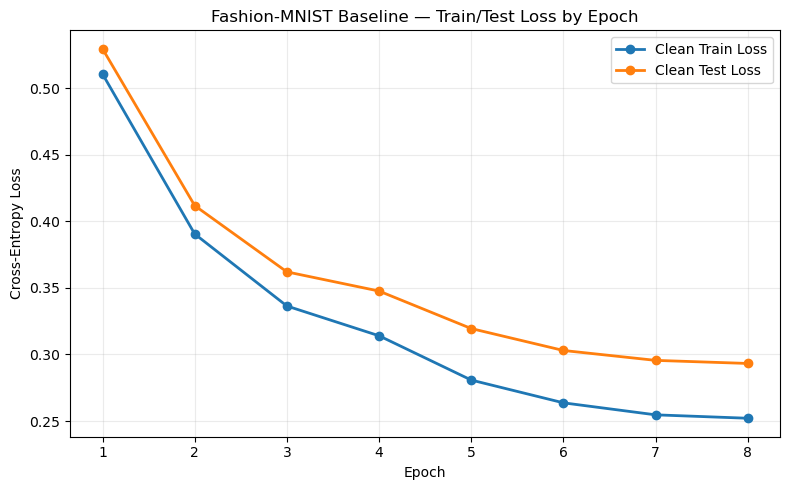

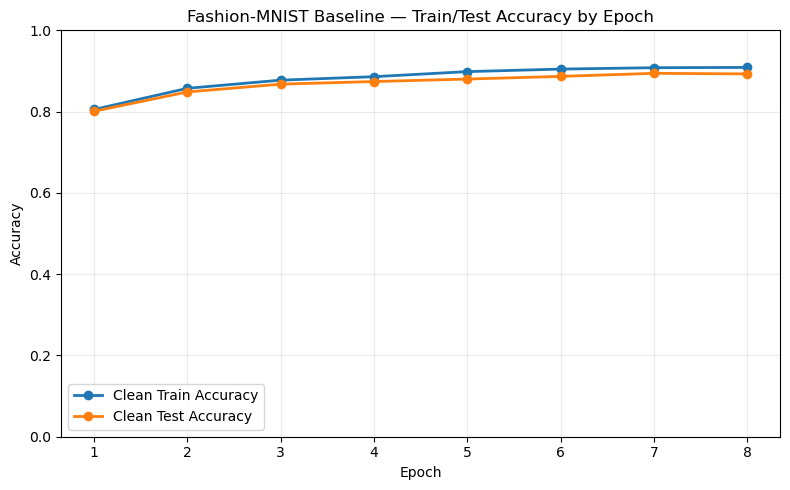

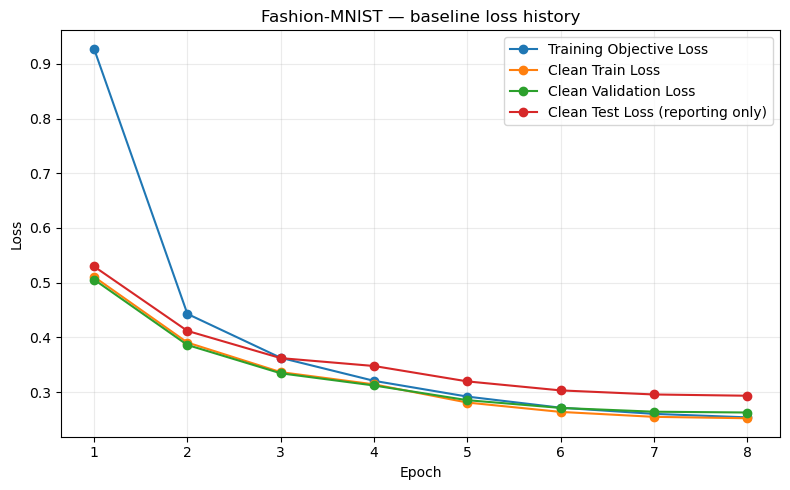

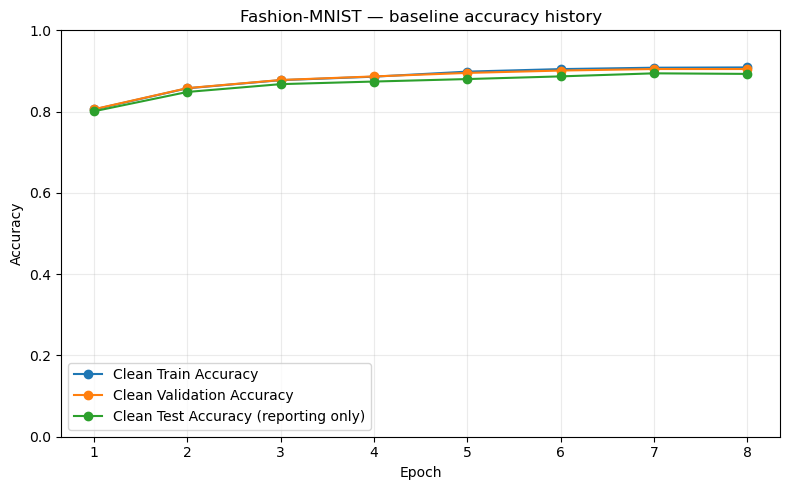

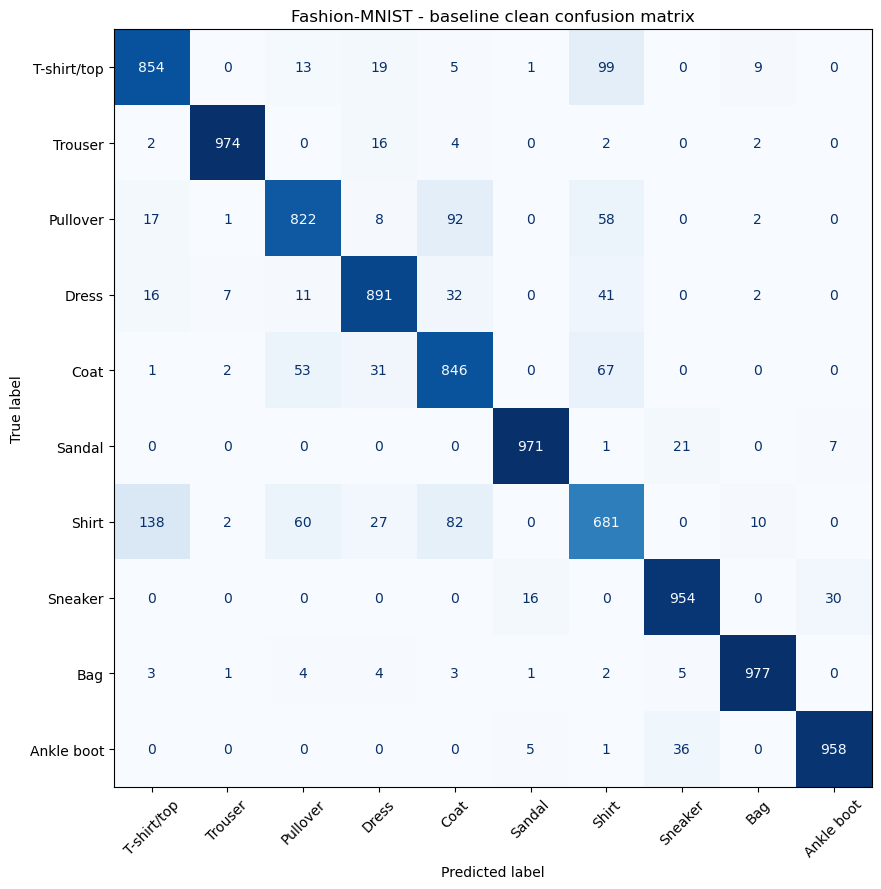

FGSM epsilon=0.000000 -> robust_accuracy=0.8928
FGSM epsilon=0.003922 -> robust_accuracy=0.8711
FGSM epsilon=0.007843 -> robust_accuracy=0.8478
FGSM epsilon=0.015686 -> robust_accuracy=0.7912
FGSM epsilon=0.031373 -> robust_accuracy=0.6660
FGSM epsilon=0.047059 -> robust_accuracy=0.5350
FGSM epsilon=0.062745 -> robust_accuracy=0.4116


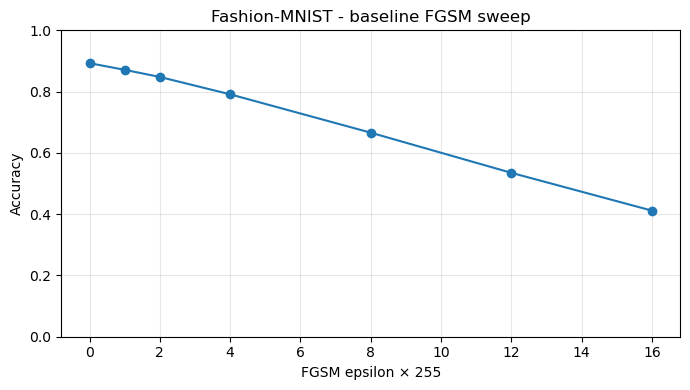

Validation PGD alpha=0.003922, steps=10, restarts=3, n=10000 -> robust_accuracy=0.6753
Validation PGD alpha=0.003922, steps=20, restarts=3, n=10000 -> robust_accuracy=0.6410
Validation PGD alpha=0.003922, steps=40, restarts=3, n=10000 -> robust_accuracy=0.6361
Validation PGD alpha=0.007843, steps=10, restarts=3, n=10000 -> robust_accuracy=0.6428
Validation PGD alpha=0.007843, steps=20, restarts=3, n=10000 -> robust_accuracy=0.6380
Validation PGD alpha=0.007843, steps=40, restarts=3, n=10000 -> robust_accuracy=0.6359
Validation PGD alpha=0.011765, steps=10, restarts=3, n=10000 -> robust_accuracy=0.6407
Validation PGD alpha=0.011765, steps=20, restarts=3, n=10000 -> robust_accuracy=0.6389
Validation PGD alpha=0.011765, steps=40, restarts=3, n=10000 -> robust_accuracy=0.6372
Strongest validation PGD configuration: {'search_split': 'heldout_validation_from_official_train', 'official_test_used_for_selection': False, 'validation_dataset_size': 10000, 'search_samples': 10000, 'epsilon': 0.031

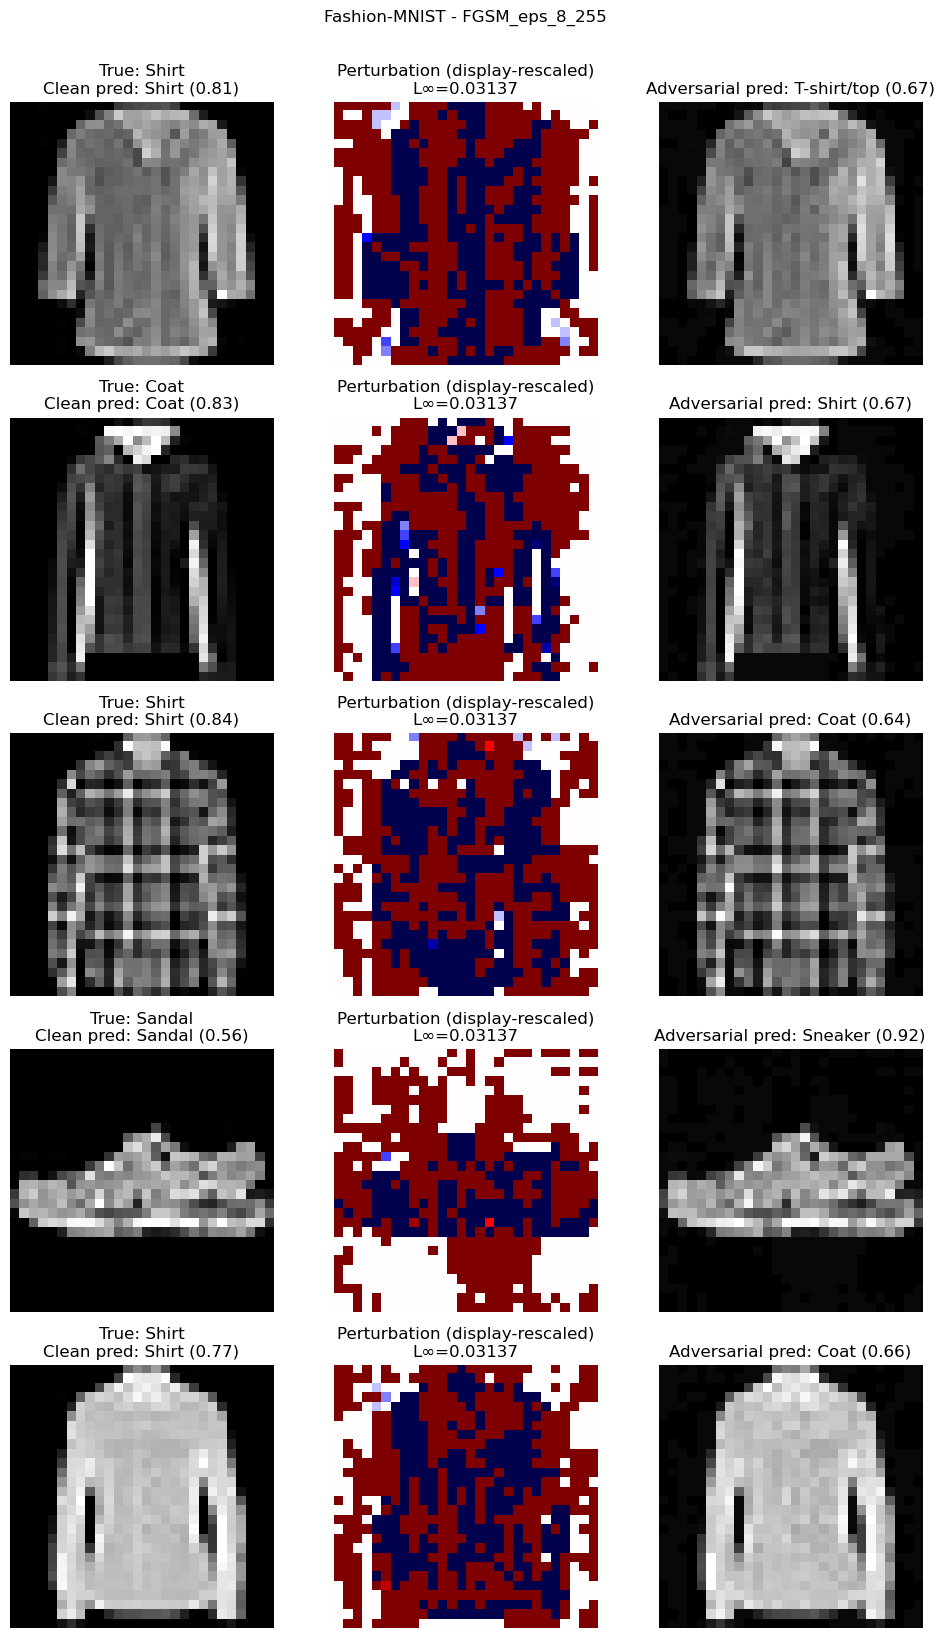

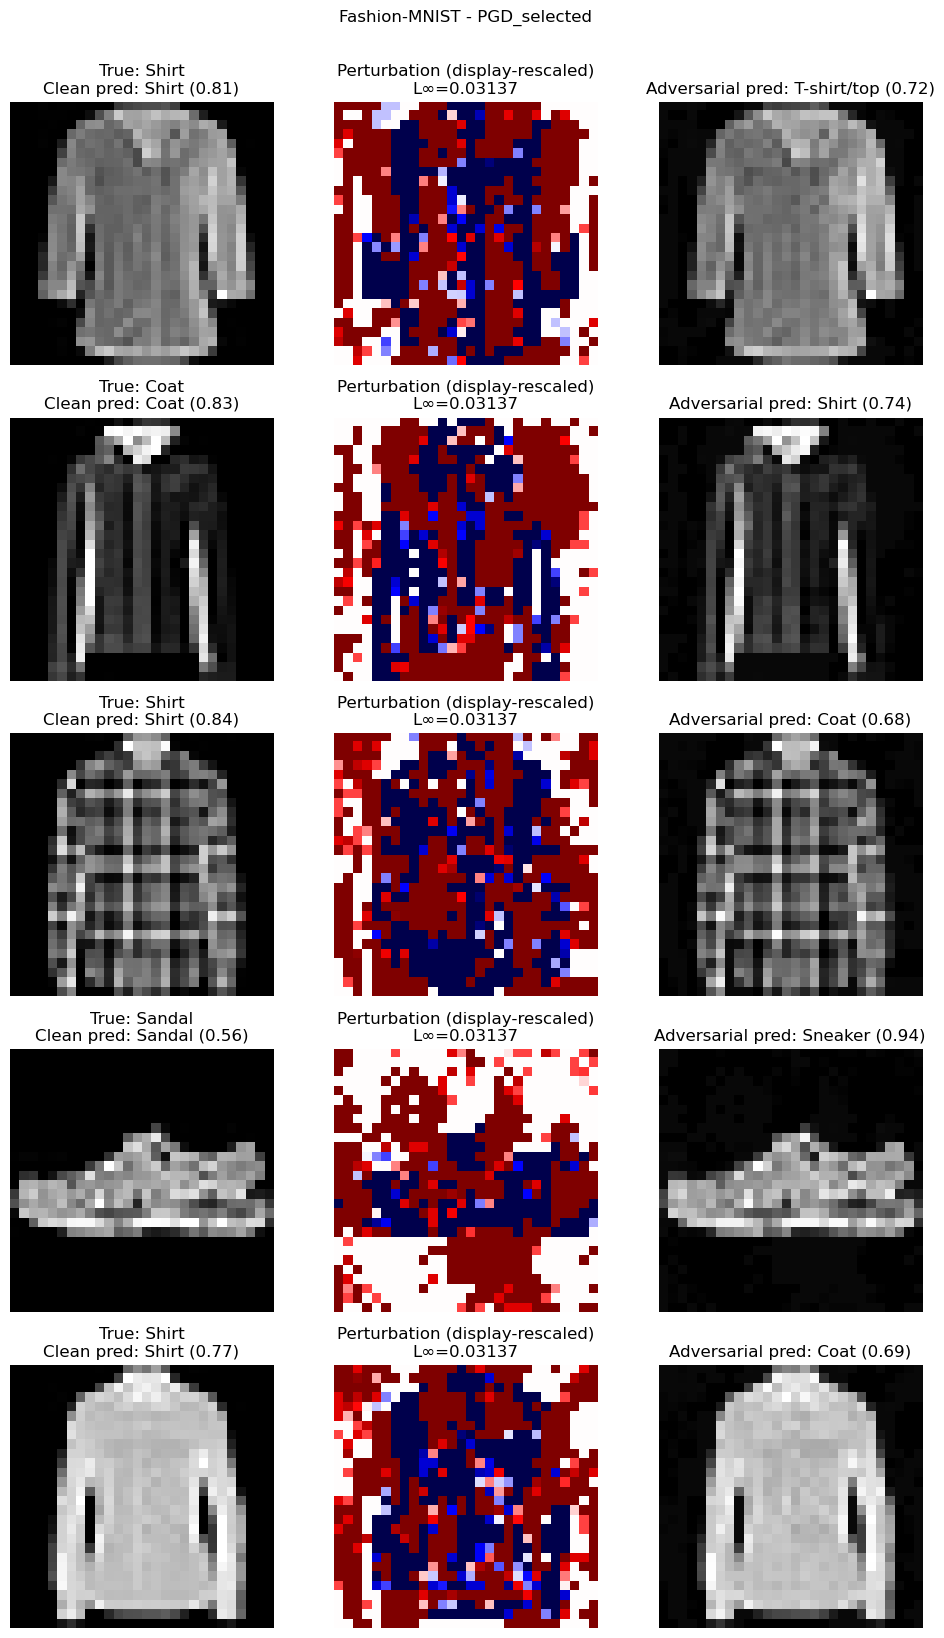

  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | fgsm_at] epoch 01/6 - objective_loss=0.6496, clean_train_loss=0.3423, validation_loss=0.3431, train_acc=0.8785, validation_acc=0.8798


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | fgsm_at] epoch 02/6 - objective_loss=0.4776, clean_train_loss=0.3013, validation_loss=0.3071, train_acc=0.8919, validation_acc=0.8875


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | fgsm_at] epoch 03/6 - objective_loss=0.4474, clean_train_loss=0.2922, validation_loss=0.2979, train_acc=0.8932, validation_acc=0.8896


... (2 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | fgsm_at] epoch 05/6 - objective_loss=0.4178, clean_train_loss=0.2744, validation_loss=0.2840, train_acc=0.9021, validation_acc=0.8980


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | fgsm_at] epoch 06/6 - objective_loss=0.4118, clean_train_loss=0.2730, validation_loss=0.2827, train_acc=0.9021, validation_acc=0.8983
[fashion_mnist | fgsm_at] training cost - training_time=33.00s, model_storage=1.74 MB, training_increment=1188.91 MB, estimated_isolated_peak=1190.64 MB


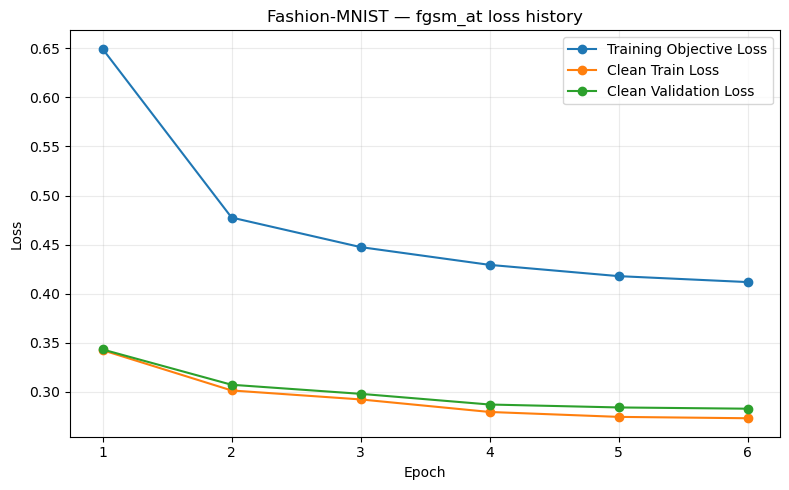

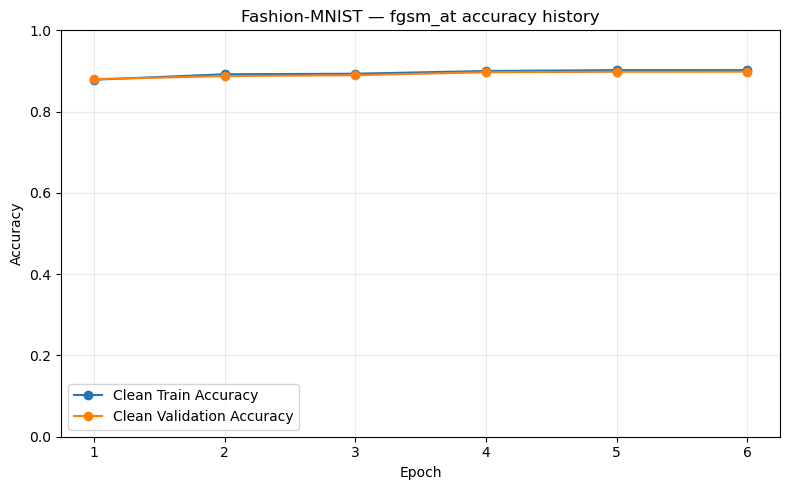

  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | pgd_at] epoch 01/6 - objective_loss=0.7741, clean_train_loss=0.3733, validation_loss=0.3730, train_acc=0.8687, validation_acc=0.8706


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | pgd_at] epoch 02/6 - objective_loss=0.5707, clean_train_loss=0.3362, validation_loss=0.3410, train_acc=0.8815, validation_acc=0.8782


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | pgd_at] epoch 03/6 - objective_loss=0.5330, clean_train_loss=0.3229, validation_loss=0.3269, train_acc=0.8841, validation_acc=0.8825


... (2 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | pgd_at] epoch 05/6 - objective_loss=0.4967, clean_train_loss=0.3069, validation_loss=0.3141, train_acc=0.8910, validation_acc=0.8876


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | pgd_at] epoch 06/6 - objective_loss=0.4896, clean_train_loss=0.3055, validation_loss=0.3127, train_acc=0.8902, validation_acc=0.8872
[fashion_mnist | pgd_at] training cost - training_time=37.72s, model_storage=1.74 MB, training_increment=686.72 MB, estimated_isolated_peak=688.45 MB


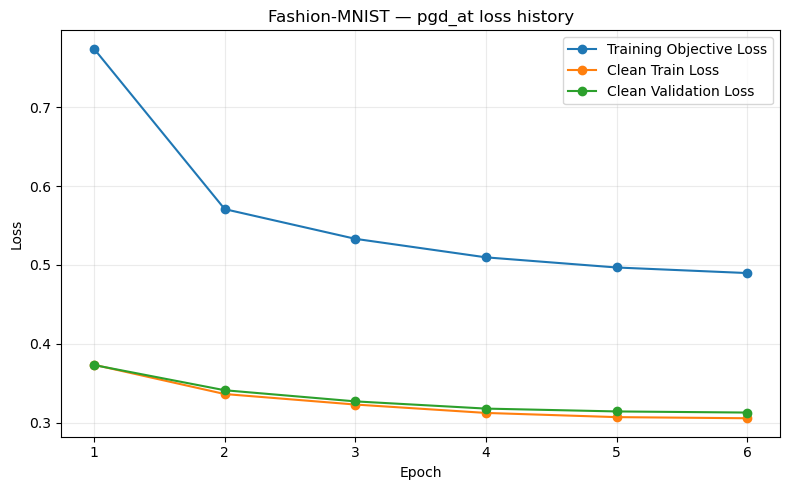

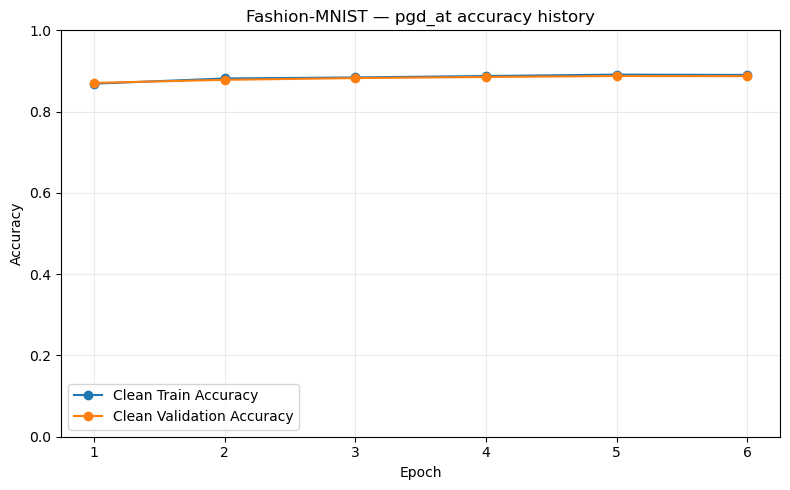

  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | independent_surrogate] epoch 01/8 - objective_loss=1.7431, clean_train_loss=1.2025, validation_loss=1.2056, train_acc=0.5205, validation_acc=0.5197


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | independent_surrogate] epoch 02/8 - objective_loss=1.0427, clean_train_loss=0.9167, validation_loss=0.9187, train_acc=0.6827, validation_acc=0.6873


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | independent_surrogate] epoch 03/8 - objective_loss=0.8584, clean_train_loss=0.8033, validation_loss=0.8058, train_acc=0.7273, validation_acc=0.7332


... (6 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | independent_surrogate] epoch 07/8 - objective_loss=0.6745, clean_train_loss=0.6674, validation_loss=0.6656, train_acc=0.7672, validation_acc=0.7735


  0%|          | 0/25 [00:00<?, ?it/s]

[fashion_mnist | independent_surrogate] epoch 08/8 - objective_loss=0.6657, clean_train_loss=0.6633, validation_loss=0.6614, train_acc=0.7689, validation_acc=0.7738
[fashion_mnist | independent_surrogate] training cost - training_time=38.91s, model_storage=0.20 MB, training_increment=1123.33 MB, estimated_isolated_peak=1123.53 MB


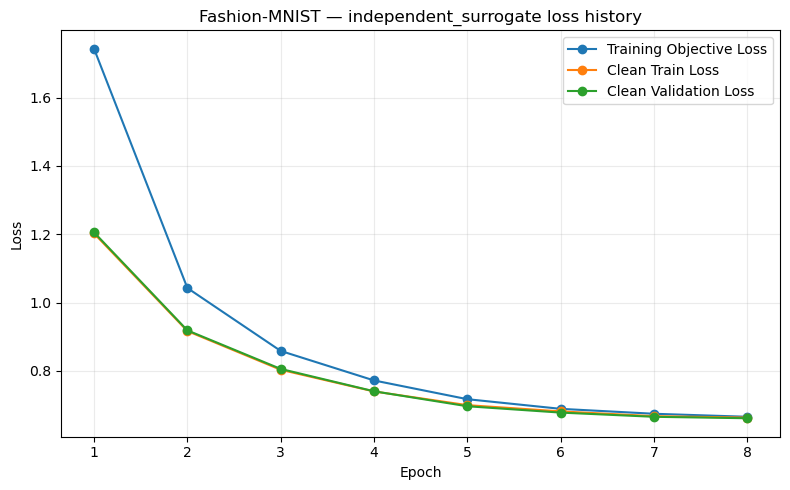

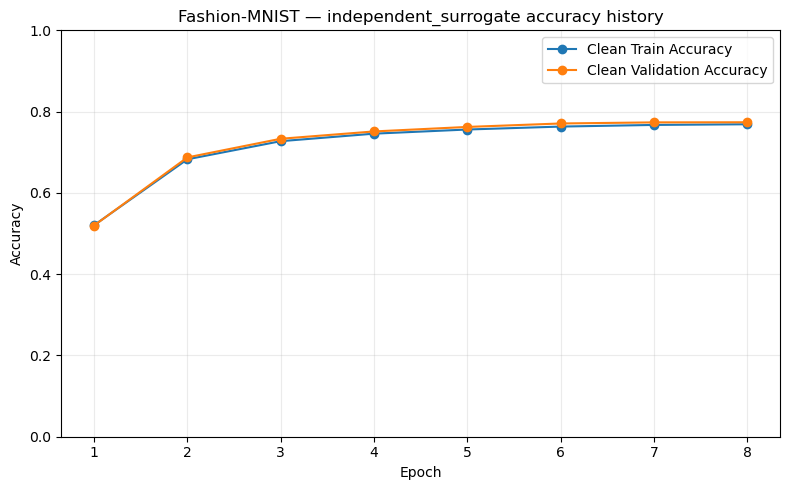

Independent surrogate summary: {'model': 'independent_surrogate', 'architecture': 'FashionSurrogateCNN', 'trained_from_scratch': True, 'loaded_target_weights': False, 'seed': 42, 'train_batch_size': 2048, 'clean_test_accuracy': 0.7656, 'clean_test_loss': 0.6778085571289062, 'test_samples': 10000}


,dataset,model,training_variant,clean_accuracy,fgsm_8_255_accuracy,pgd_selected_accuracy,pgd_alpha,pgd_steps,pgd_restarts,stage_training_seconds,...,relative_estimated_peak_gpu_vs_baseline,pipeline_estimated_peak_gpu_mb,relative_pipeline_estimated_peak_vs_baseline,raw_process_peak_gpu_allocated_mb,raw_process_peak_gpu_reserved_mb,gpu_memory_measurement_method,batch_size,adversarial_gradient_steps_per_batch,trainable_parameters,test_samples
0,fashion_mnist,baseline,standard clean training,0.8928,0.6660,0.6343,0.011765,10,3,51.752612,...,1.000000,727.379929,1.00000,727.382324,1744.0,model_storage_plus_peak_increment,2048,0,454922,10000
1,fashion_mnist,fgsm_at,random-start FGSM adversarial fine-tuning,0.8865,0.7847,0.7695,0.011765,10,3,33.003208,...,1.636890,1190.640671,1.63689,1256.380859,1894.0,model_storage_plus_peak_increment,2048,1,454922,10000
2,fashion_mnist,pgd_at,PGD-7 adversarial fine-tuning,0.8773,0.7971,0.7868,0.011765,10,3,37.721888,...,0.946483,727.379929,1.00000,755.930664,1672.0,model_storage_plus_peak_increment,2048,7,454922,10000


Independent-surrogate transfer PGD:   0%|          | 0/5 [00:00<?, ?it/s]

,model,surrogate_model,surrogate_architecture,surrogate_is_independent,shared_target_weights,surrogate_clean_accuracy,white_box_pgd_accuracy,transfer_black_box_accuracy,white_box_attack_seconds,transfer_attack_seconds,transfer_batch_size,steps,restarts,white_box_n_samples,n_samples,max_linf
0,baseline,independent_surrogate,FashionSurrogateCNN,True,False,0.7656,0.6275,0.8659,12.005318,19.436447,2048,40,5,10000,10000,0.031373
1,fgsm_at,independent_surrogate,FashionSurrogateCNN,True,False,0.7656,0.7663,0.8721,12.085359,19.436447,2048,40,5,10000,10000,0.031373
2,pgd_at,independent_surrogate,FashionSurrogateCNN,True,False,0.7656,0.7855,0.8614,12.066964,19.436447,2048,40,5,10000,10000,0.031373


EOT full-test audit enabled for fashion_mnist: 10000/10000 samples.

EOT audit | fashion_mnist | baseline | n=10000


fashion_mnist | baseline | ordinary PGD:   0% 0/10000 [00:00<?, ?img/s]

... (4 outputs left out)

Ordinary PGD accuracy: 0.7668
EOT-PGD accuracy:      0.7668
EOT - ordinary:        +0.0000
Maximum logit std:      0.000e+00
Time ratio:             9.42x
Interpretation: Inference is empirically deterministic and EOT is consistent with ordinary PGD; no EOT-specific masking evidence.

EOT audit | fashion_mnist | pgd_at | n=10000


fashion_mnist | pgd_at | ordinary PGD:   0% 0/10000 [00:00<?, ?img/s]

fashion_mnist | pgd_at | EOT-PGD:   0% 0/10000 [00:00<?, ?img/s]

Ordinary PGD accuracy: 0.7859
EOT-PGD accuracy:      0.7859
EOT - ordinary:        +0.0000
Maximum logit std:      0.000e+00
Time ratio:             9.18x
Interpretation: Inference is empirically deterministic and EOT is consistent with ordinary PGD; no EOT-specific masking evidence.


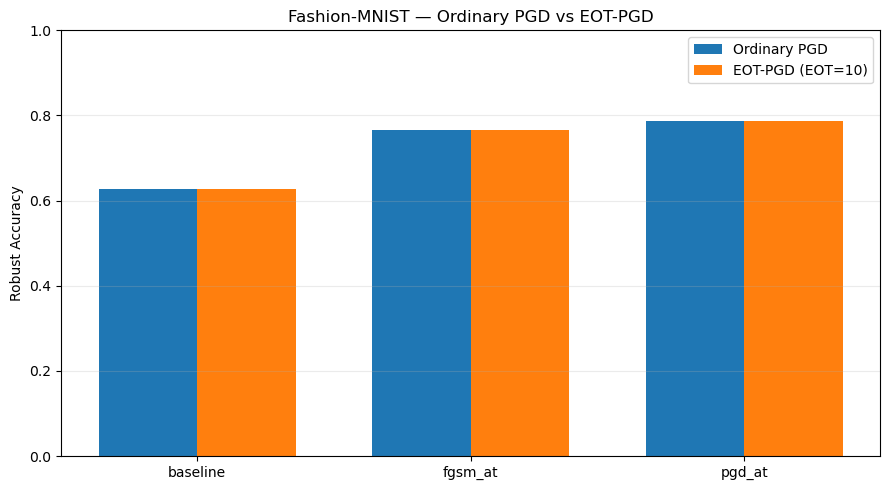

,dataset,model,epsilon,alpha,steps,restarts,eot_gradient_samples,eot_prediction_samples,n_samples,full_official_test_set,...,ordinary_pgd_mean_linf,eot_pgd_mean_linf,ordinary_pgd_seconds,eot_pgd_seconds,eot_to_ordinary_time_ratio,stochasticity_test_samples,repeated_forward_count,mean_sample_max_logit_std,maximum_logit_std,interpretation
0,fashion_mnist,baseline,0.031373,0.007843,40,3,10,20,10000,True,...,0.031373,0.031373,7.574488,71.124657,9.390028,128,20,0.0,0.0,Inference is empirically deterministic and EOT...
1,fashion_mnist,fgsm_at,0.031373,0.007843,40,3,10,20,10000,True,...,0.031373,0.031373,7.559995,71.182493,9.415679,128,20,0.0,0.0,Inference is empirically deterministic and EOT...
2,fashion_mnist,pgd_at,0.031373,0.007843,40,3,10,20,10000,True,...,0.031373,0.031373,7.750458,71.162914,9.181769,128,20,0.0,0.0,Inference is empirically deterministic and EOT...


AutoAttack fashion_mnist:   0%|          | 0/5 [00:00<?, ?it/s]

-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 90.14%
parameters:  10 2 1 1
iteration: 0 - Best loss: 187.821304
iteration: 1 - Best loss: 944.873901
iteration: 2 - Best loss: 1009.946045
iteration: 3 - Best loss: 1050.448242
iteration: 4 - Best loss: 1062.712036
iteration: 5 - Best loss: 1072.162842
iteration: 6 - Best loss: 1081.801514
iteration: 7 - Best loss: 1089.362305
iteration: 8 - Best loss: 1097.110474
iteration: 9 - Best loss: 1104.407715
restart 0 - robust accuracy: 64.65% - cum. time: 0.3 s
-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 100.00%
parameters:  10 2 1 1
iteration: 0 - Best loss: -943.593872
iteration: 1 - Best loss: -640.745605
iteration: 2 - Best loss: -610.779663
iteration: 3 - Best loss: -591.948547
iteration: 4 - Best loss: -585.611816
iteration: 5 - Best loss: -581.991333
iteration: 6 - Best loss: -579.653259
iteration: 7 - Bes

AutoAttack fashion_mnist:   0%|          | 0/5 [00:00<?, ?it/s]

-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 89.45%
parameters:  10 2 1 1
iteration: 0 - Best loss: 232.144623
iteration: 1 - Best loss: 515.134521
iteration: 2 - Best loss: 537.671631
iteration: 3 - Best loss: 550.818420
iteration: 4 - Best loss: 555.176392
iteration: 5 - Best loss: 557.967773
iteration: 6 - Best loss: 560.687134
iteration: 7 - Best loss: 563.241760
iteration: 8 - Best loss: 565.577393
iteration: 9 - Best loss: 567.953857
restart 0 - robust accuracy: 77.39% - cum. time: 0.2 s
-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 100.00%
parameters:  10 2 1 1
iteration: 0 - Best loss: -1013.620239
iteration: 1 - Best loss: -795.583313
iteration: 2 - Best loss: -778.292664
iteration: 3 - Best loss: -768.046265
iteration: 4 - Best loss: -764.055115
iteration: 5 - Best loss: -761.748352
iteration: 6 - Best loss: -760.199951
iteration: 7 - Best loss:

AutoAttack fashion_mnist:   0%|          | 0/5 [00:00<?, ?it/s]

-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 88.77%
parameters:  10 2 1 1
iteration: 0 - Best loss: 283.708435
iteration: 1 - Best loss: 505.340637
iteration: 2 - Best loss: 519.706970
iteration: 3 - Best loss: 528.426514
iteration: 4 - Best loss: 531.024902
iteration: 5 - Best loss: 532.570190
iteration: 6 - Best loss: 534.427734
iteration: 7 - Best loss: 536.038452
iteration: 8 - Best loss: 537.429565
iteration: 9 - Best loss: 538.696411
restart 0 - robust accuracy: 78.47% - cum. time: 0.2 s
-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 100.00%
parameters:  10 2 1 1
iteration: 0 - Best loss: -975.589478
iteration: 1 - Best loss: -793.430176
iteration: 2 - Best loss: -781.398499
iteration: 3 - Best loss: -773.786438
iteration: 4 - Best loss: -770.946411
iteration: 5 - Best loss: -769.356201
iteration: 6 - Best loss: -768.242310
iteration: 7 - Best loss: 

,model,robust_accuracy,n_samples,full_test_set,suite_version,suite_components,mean_linf,max_linf,attack_seconds
0,baseline,0.6267,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.008348,0.031373,182.343922
1,fgsm_at,0.7642,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.003837,0.031373,197.510478
2,pgd_at,0.7818,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.002996,0.031373,179.434673


/opt/conda/lib/python3.12/site-packages/captum/concept/_core/tcav.py:330: UserWarning: Using default classifier for TCAV which keeps input both train and test datasets in the memory. Consider defining your own classifier that doesn't rely heavily on memory, for large number of concepts, by extending `Classifer` abstract class
  self.classifier = DefaultClassifier()
/opt/conda/lib/python3.12/site-packages/captum/_utils/models/linear_model/train.py:418: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:254.)
  bias_values = torch.FloatTensor([sklearn_model.intercept_]).to(  # type: ignore
/opt/conda/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data

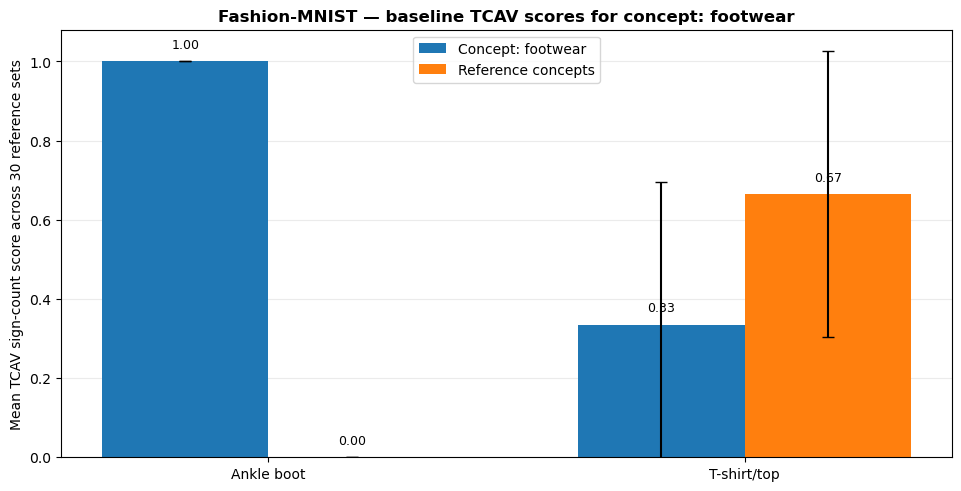

,dataset,model,target_class,target_name,concept,concept_classes,reference_classes,reference_is_disjoint,target_examples_clean_correct_only,target_samples,...,std_reference_sign_count,mean_concept_magnitude,mean_reference_magnitude,random_sets,paired_t_statistic,paired_p_value,paired_effect_size_dz,mean_difference,difference_ci95_low,difference_ci95_high
0,fashion_mnist,baseline,9,Ankle boot,footwear,"5,7","1,2,3,4,6,8",True,True,128,...,0.000000,1.493967,-1.493967,30,inf,0.000000,inf,1.000000,1.000000,1.000000
1,fashion_mnist,baseline,0,T-shirt/top,footwear,"5,7","1,2,3,4,6,8",True,True,128,...,0.361313,-0.140463,0.140463,30,-2.502855,0.018205,-0.456957,-0.330208,-0.600041,-0.060376


/opt/conda/lib/python3.12/site-packages/captum/concept/_core/tcav.py:330: UserWarning: Using default classifier for TCAV which keeps input both train and test datasets in the memory. Consider defining your own classifier that doesn't rely heavily on memory, for large number of concepts, by extending `Classifer` abstract class
  self.classifier = DefaultClassifier()
/opt/conda/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)


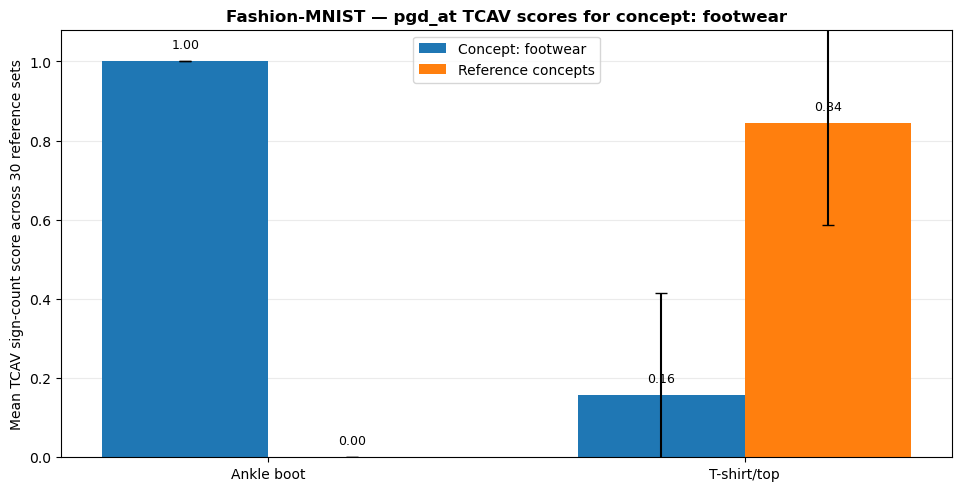

,dataset,model,target_class,target_name,concept,concept_classes,reference_classes,reference_is_disjoint,target_examples_clean_correct_only,target_samples,...,std_reference_sign_count,mean_concept_magnitude,mean_reference_magnitude,random_sets,paired_t_statistic,paired_p_value,paired_effect_size_dz,mean_difference,difference_ci95_low,difference_ci95_high
0,fashion_mnist,pgd_at,9,Ankle boot,footwear,"5,7","1,2,3,4,6,8",True,True,128,...,0.000000,0.583882,-0.583882,30,inf,0.000000e+00,inf,1.000000,1.00000,1.000000
1,fashion_mnist,pgd_at,0,T-shirt/top,footwear,"5,7","1,2,3,4,6,8",True,True,128,...,0.257792,-0.119215,0.119215,30,-7.292495,4.952010e-08,-1.331421,-0.686458,-0.87898,-0.493936


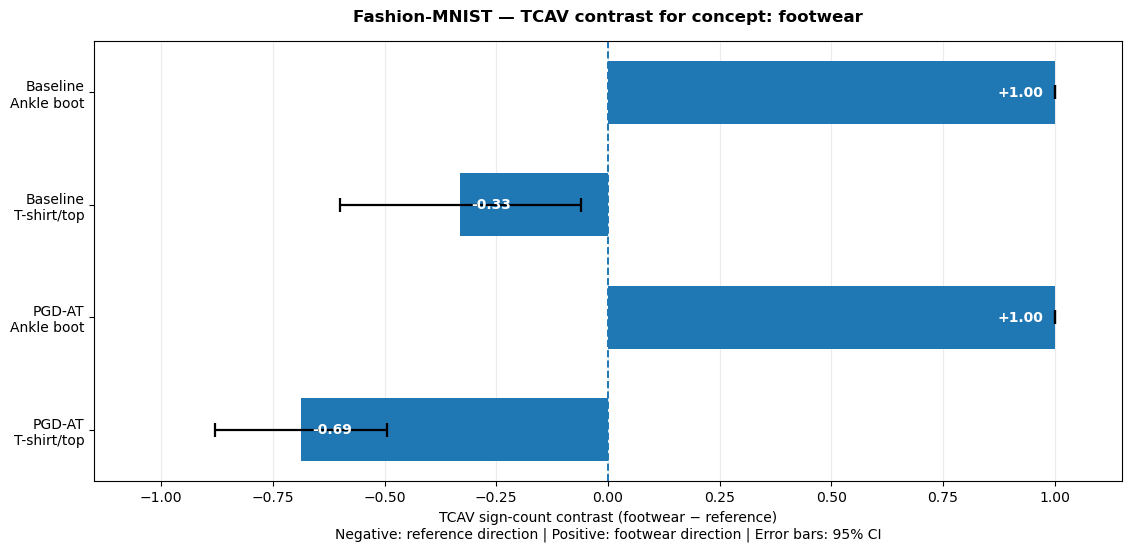

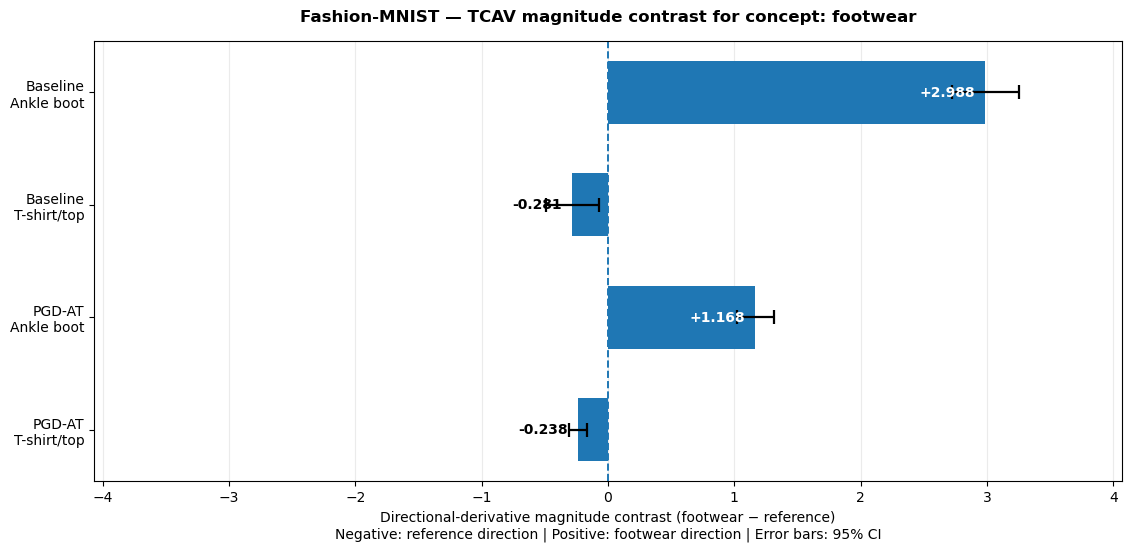

Integrated TCAV contrast outputs:
 - q5_results_corrected_v7_fashion2048_cifar1024/full/fashion_mnist/tcav_contrast_plots/tcav_sign_count_contrast.png
 - q5_results_corrected_v7_fashion2048_cifar1024/full/fashion_mnist/tcav_contrast_plots/tcav_magnitude_contrast.png
 - q5_results_corrected_v7_fashion2048_cifar1024/full/fashion_mnist/tcav_contrast_plots/tcav_contrast_summary.csv


,dataset,model,target_class,target_name,concept,random_reference_sets,mean_concept_sign_count,mean_reference_sign_count,mean_sign_count_contrast,std_sign_count_contrast,...,std_magnitude_contrast,sem_magnitude_contrast,magnitude_ci95_lower,magnitude_ci95_upper,positive_pairs,negative_pairs,zero_pairs,nonzero_pairs,exact_sign_test_p,direction
0,fashion_mnist,baseline,9,Ankle boot,footwear,30,1.000000,0.000000,1.000000,0.000000,...,0.709288,0.129498,2.723082,3.252787,30,0,0,30,0.000000,concept direction dominates
1,fashion_mnist,baseline,0,T-shirt/top,footwear,30,0.334896,0.665104,-0.330208,0.722625,...,0.554159,0.101175,-0.487853,-0.074000,10,20,0,30,0.098737,reference direction dominates
2,fashion_mnist,pgd_at,9,Ankle boot,footwear,30,1.000000,0.000000,1.000000,0.000000,...,0.393714,0.071882,1.020750,1.314780,30,0,0,30,0.000000,concept direction dominates
3,fashion_mnist,pgd_at,0,T-shirt/top,footwear,30,0.156771,0.843229,-0.686458,0.515583,...,0.196243,0.035829,-0.311708,-0.165151,3,26,1,29,0.000015,reference direction dominates


cifar10 split:
  model training: 49,488
  validation / PGD grid: 512
  official test (reporting only): 10,000

===== CIFAR-10 =====
Model-training samples: 49488
Validation / PGD-grid samples: 512
Official test samples (baseline epoch reporting only; never used for selection): 10000
Batch size: 1024


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | baseline] epoch 01/25 - objective_loss=3.7810, clean_train_loss=2.3515, validation_loss=2.3266, train_acc=0.1231, validation_acc=0.1250, test_loss=2.3353, test_acc=0.1286


  0%|          | 0/49 [00:00<?, ?it/s]

... (43 outputs left out)

  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | baseline] epoch 24/25 - objective_loss=0.4742, clean_train_loss=0.4472, validation_loss=0.5273, train_acc=0.8433, validation_acc=0.8027, test_loss=0.5712, test_acc=0.8051


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | baseline] epoch 25/25 - objective_loss=0.4631, clean_train_loss=0.4374, validation_loss=0.5194, train_acc=0.8477, validation_acc=0.8184, test_loss=0.5604, test_acc=0.8076
[cifar10 | baseline] training cost - training_time=476.26s, model_storage=42.66 MB, training_increment=6738.69 MB, estimated_isolated_peak=6781.36 MB


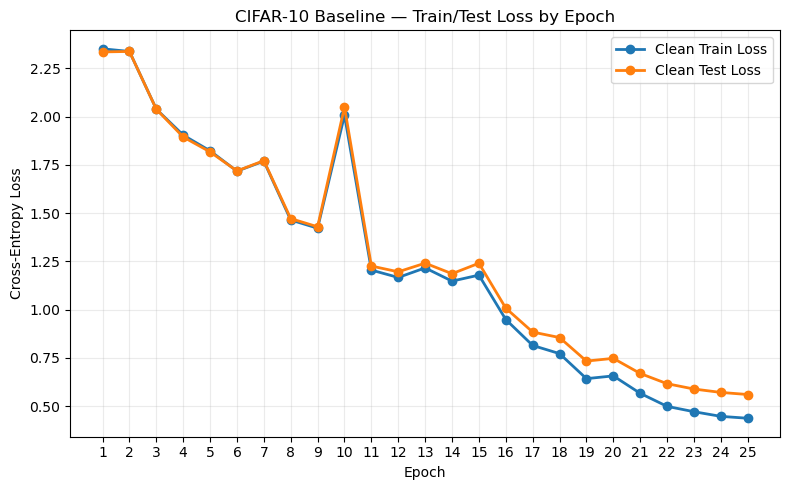

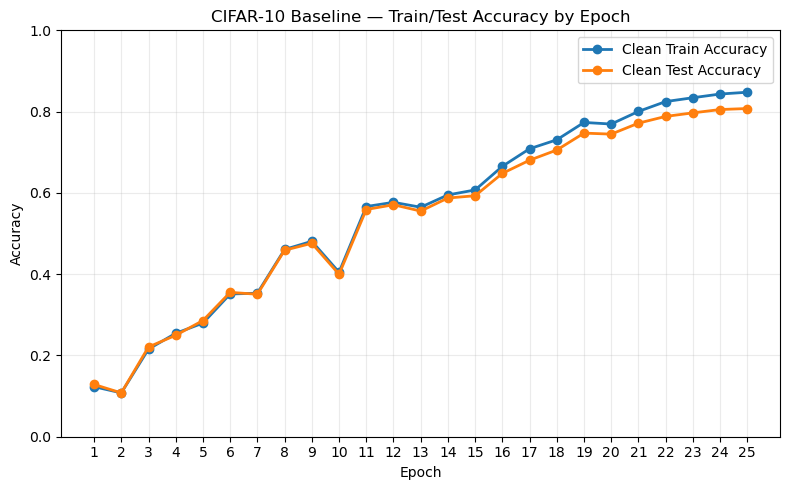

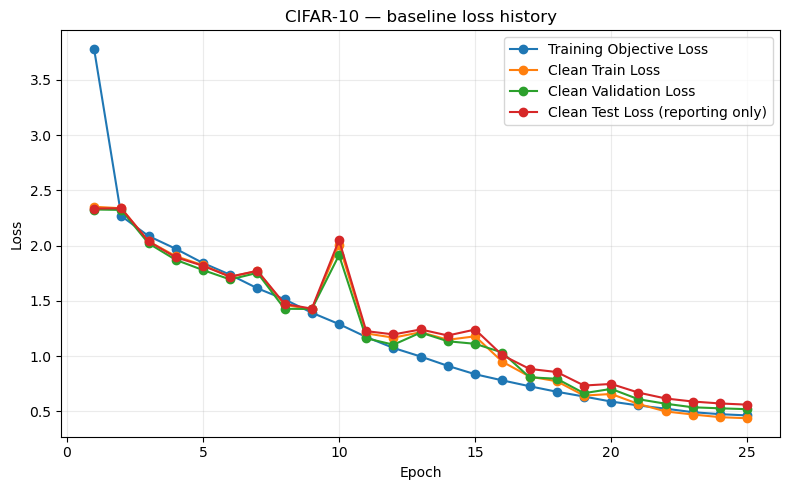

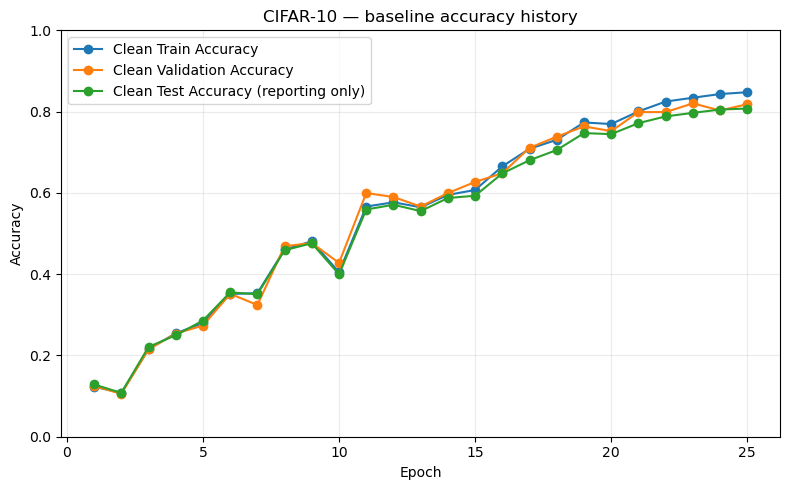

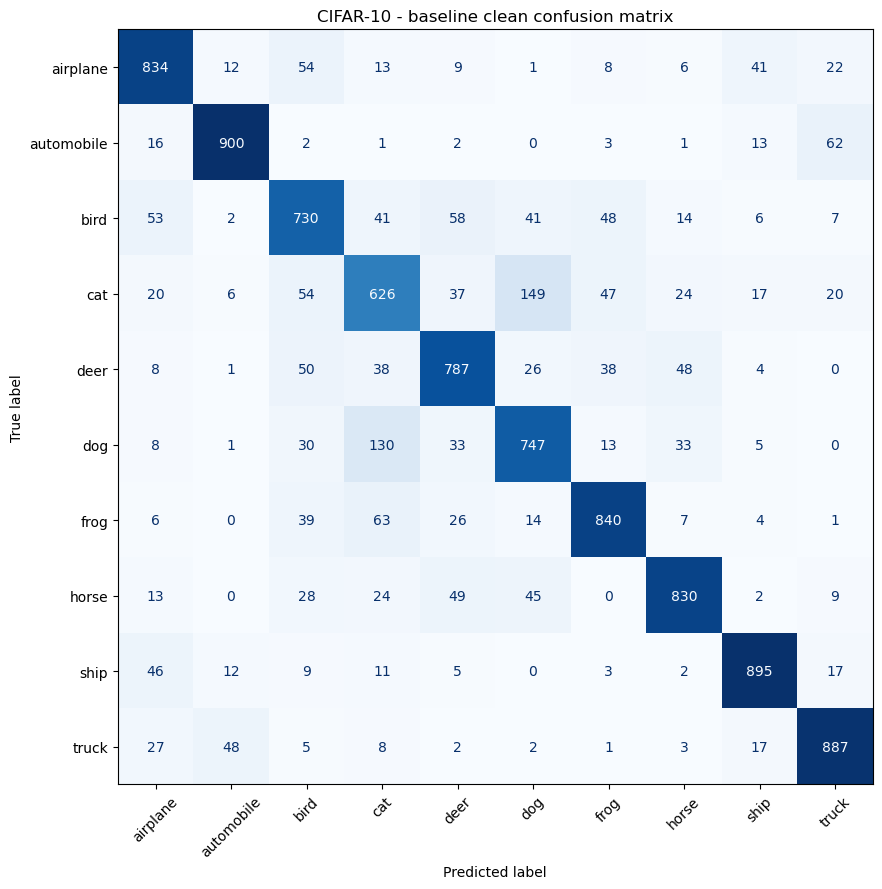

FGSM epsilon=0.000000 -> robust_accuracy=0.8076
FGSM epsilon=0.003922 -> robust_accuracy=0.5277
FGSM epsilon=0.007843 -> robust_accuracy=0.3132
FGSM epsilon=0.015686 -> robust_accuracy=0.1273
FGSM epsilon=0.031373 -> robust_accuracy=0.0423
FGSM epsilon=0.047059 -> robust_accuracy=0.0348
FGSM epsilon=0.062745 -> robust_accuracy=0.0388


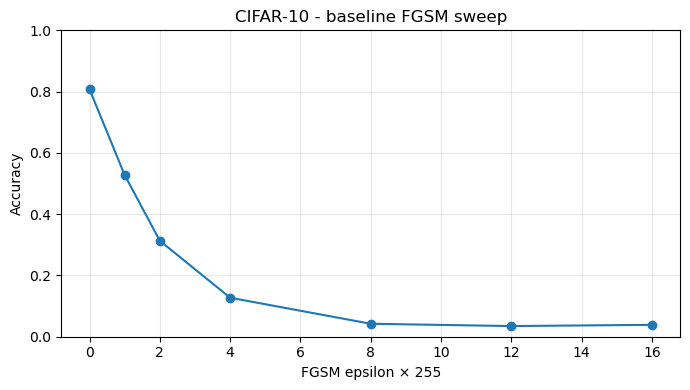

Validation PGD alpha=0.003922, steps=10, restarts=3, n=512 -> robust_accuracy=0.0000
Validation PGD alpha=0.003922, steps=20, restarts=3, n=512 -> robust_accuracy=0.0000
Validation PGD alpha=0.003922, steps=40, restarts=3, n=512 -> robust_accuracy=0.0000
Validation PGD alpha=0.007843, steps=10, restarts=3, n=512 -> robust_accuracy=0.0000
Validation PGD alpha=0.007843, steps=20, restarts=3, n=512 -> robust_accuracy=0.0000
Validation PGD alpha=0.007843, steps=40, restarts=3, n=512 -> robust_accuracy=0.0000
Validation PGD alpha=0.011765, steps=10, restarts=3, n=512 -> robust_accuracy=0.0000
Validation PGD alpha=0.011765, steps=20, restarts=3, n=512 -> robust_accuracy=0.0000
Validation PGD alpha=0.011765, steps=40, restarts=3, n=512 -> robust_accuracy=0.0000
Strongest validation PGD configuration: {'search_split': 'heldout_validation_from_official_train', 'official_test_used_for_selection': False, 'validation_dataset_size': 512, 'search_samples': 512, 'epsilon': 0.03137254901960784, 'alpha

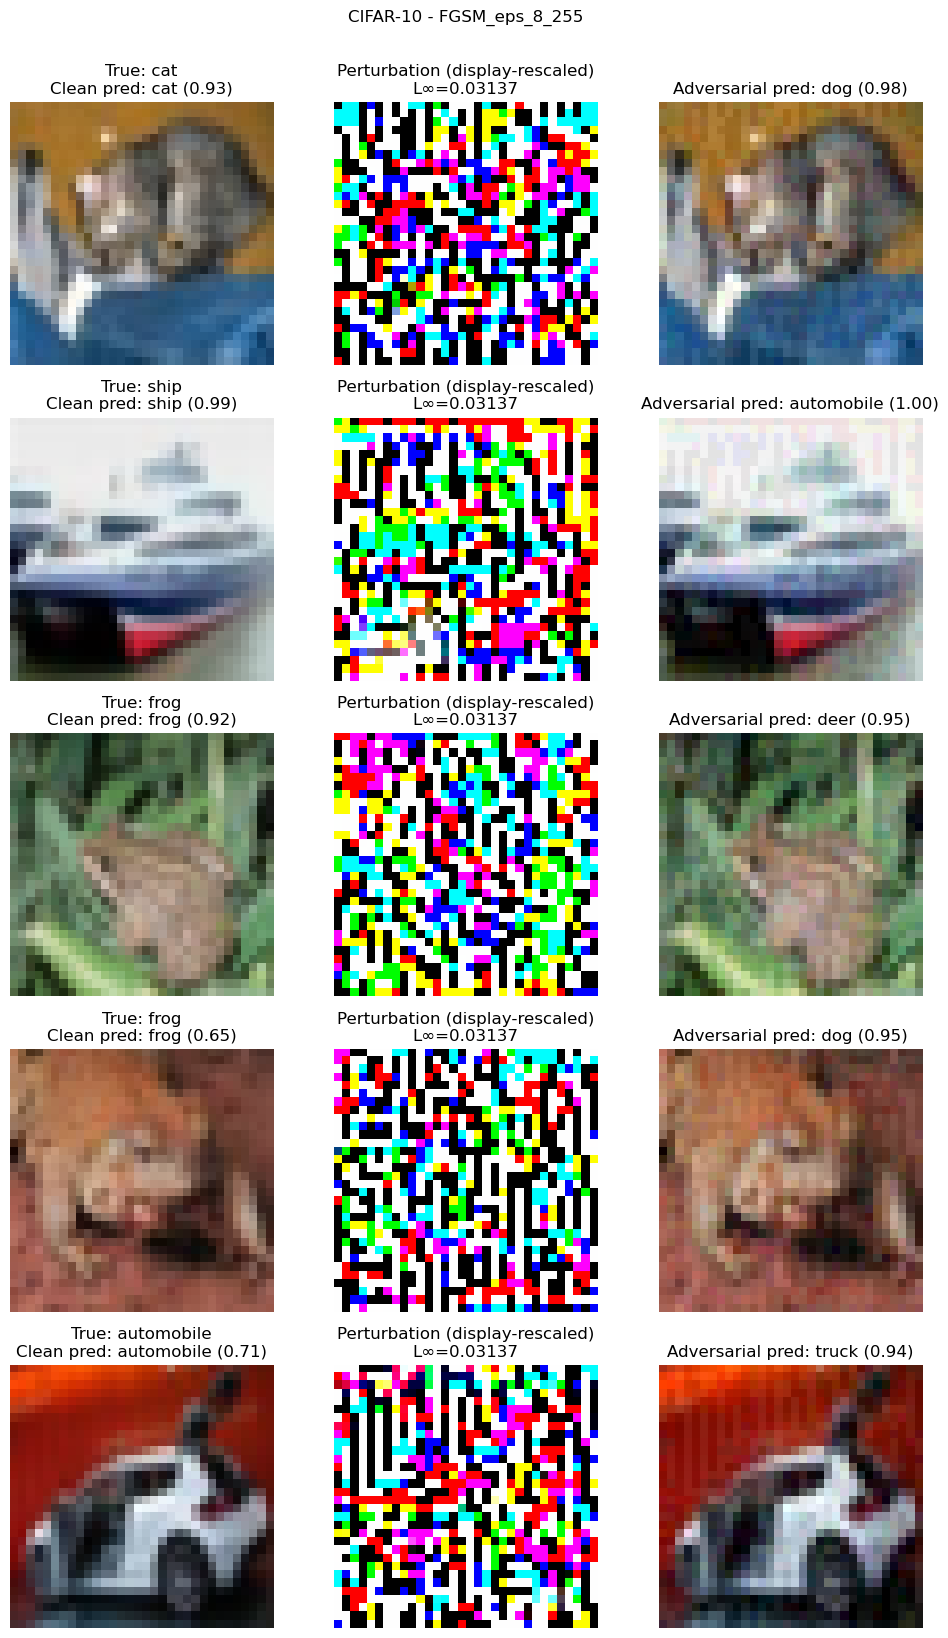

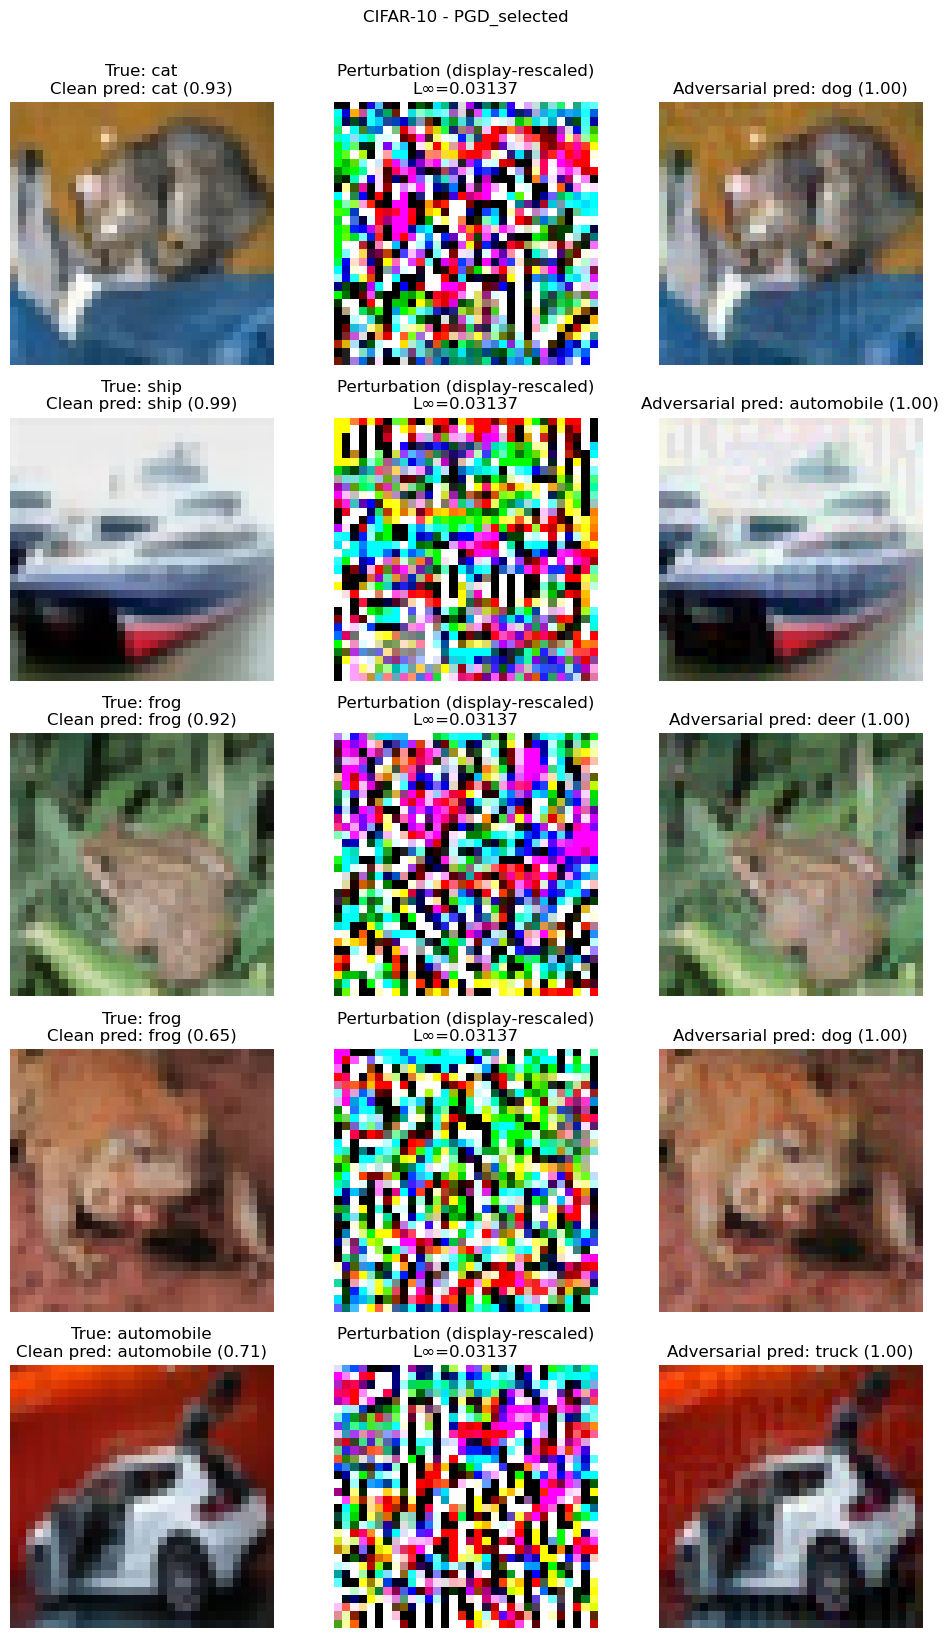

  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | fgsm_at] epoch 01/12 - objective_loss=1.9953, clean_train_loss=1.3334, validation_loss=1.3217, train_acc=0.5562, validation_acc=0.5391


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | fgsm_at] epoch 02/12 - objective_loss=1.7145, clean_train_loss=1.1909, validation_loss=1.1863, train_acc=0.6172, validation_acc=0.6152


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | fgsm_at] epoch 03/12 - objective_loss=1.6437, clean_train_loss=1.1229, validation_loss=1.1185, train_acc=0.6350, validation_acc=0.6074


... (14 outputs left out)

  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | fgsm_at] epoch 11/12 - objective_loss=1.4886, clean_train_loss=0.9712, validation_loss=0.9760, train_acc=0.6895, validation_acc=0.6738


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | fgsm_at] epoch 12/12 - objective_loss=1.4870, clean_train_loss=0.9694, validation_loss=0.9747, train_acc=0.6912, validation_acc=0.6719
[cifar10 | fgsm_at] training cost - training_time=525.34s, model_storage=42.66 MB, training_increment=11341.19 MB, estimated_isolated_peak=11383.85 MB


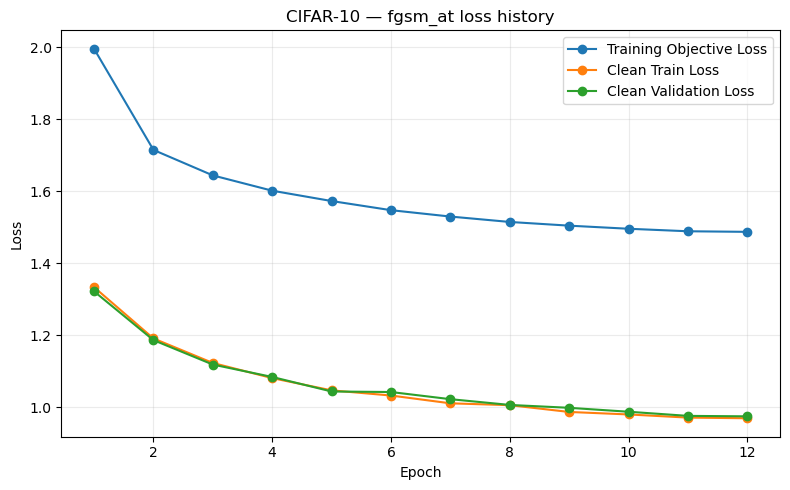

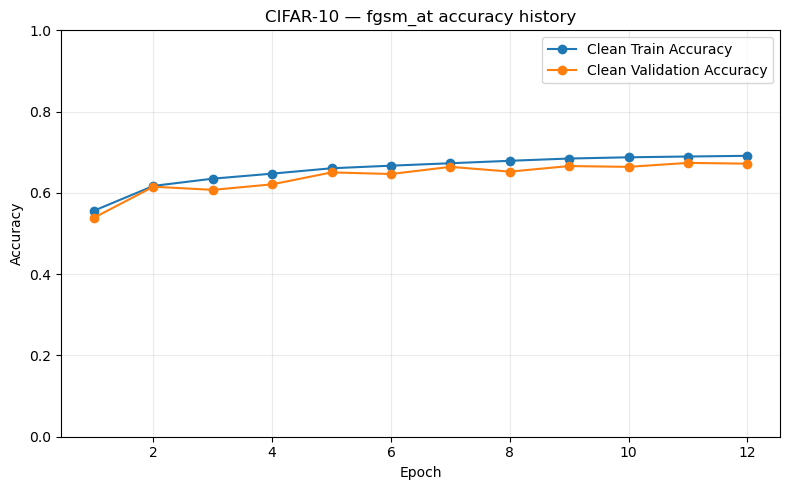

  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | pgd_at] epoch 01/12 - objective_loss=2.0930, clean_train_loss=1.6386, validation_loss=1.6102, train_acc=0.4396, validation_acc=0.4375


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | pgd_at] epoch 02/12 - objective_loss=1.9321, clean_train_loss=1.5218, validation_loss=1.4966, train_acc=0.4895, validation_acc=0.4805


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | pgd_at] epoch 03/12 - objective_loss=1.8694, clean_train_loss=1.4427, validation_loss=1.4346, train_acc=0.5062, validation_acc=0.4980


... (14 outputs left out)

  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | pgd_at] epoch 11/12 - objective_loss=1.6703, clean_train_loss=1.1735, validation_loss=1.1675, train_acc=0.6164, validation_acc=0.5957


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | pgd_at] epoch 12/12 - objective_loss=1.6636, clean_train_loss=1.1629, validation_loss=1.1537, train_acc=0.6217, validation_acc=0.5977
[cifar10 | pgd_at] training cost - training_time=1051.20s, model_storage=42.66 MB, training_increment=6811.61 MB, estimated_isolated_peak=6854.27 MB


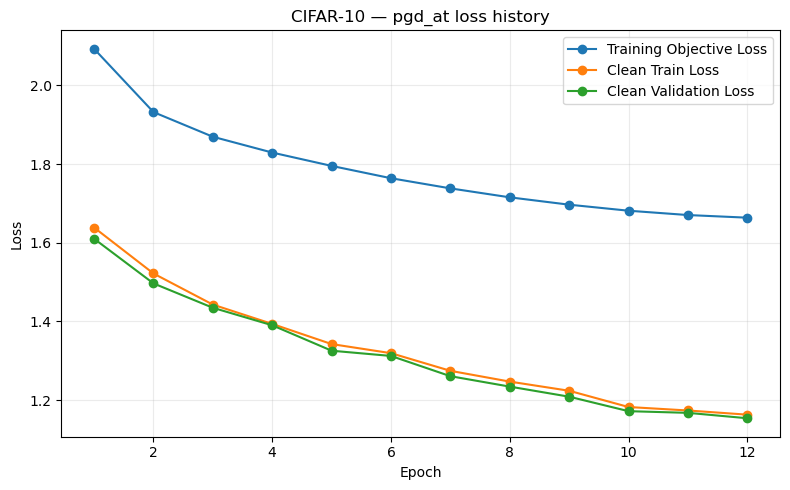

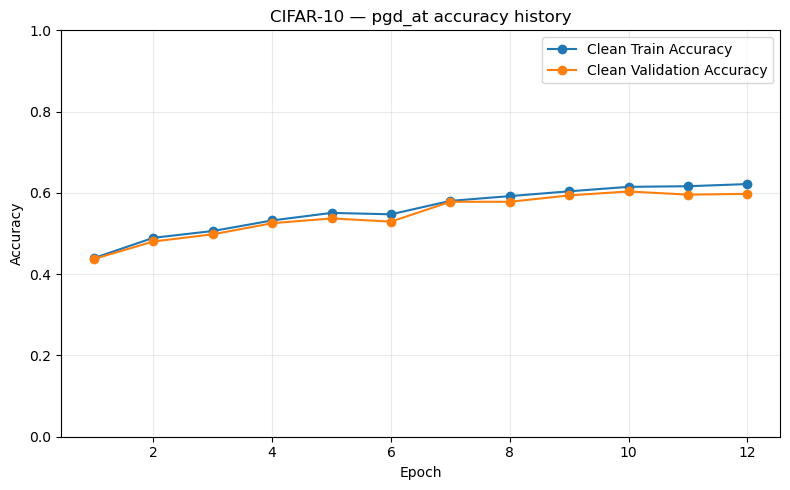

  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | independent_surrogate] epoch 01/25 - objective_loss=1.6408, clean_train_loss=1.9858, validation_loss=2.0074, train_acc=0.3936, validation_acc=0.3984


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | independent_surrogate] epoch 02/25 - objective_loss=1.1213, clean_train_loss=2.0782, validation_loss=2.0690, train_acc=0.4608, validation_acc=0.4609


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | independent_surrogate] epoch 03/25 - objective_loss=0.8789, clean_train_loss=1.6670, validation_loss=1.6932, train_acc=0.5260, validation_acc=0.5156


... (40 outputs left out)

  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | independent_surrogate] epoch 24/25 - objective_loss=0.1478, clean_train_loss=0.1315, validation_loss=0.3405, train_acc=0.9576, validation_acc=0.8965


  0%|          | 0/49 [00:00<?, ?it/s]

[cifar10 | independent_surrogate] epoch 25/25 - objective_loss=0.1481, clean_train_loss=0.1279, validation_loss=0.3366, train_acc=0.9589, validation_acc=0.8848
[cifar10 | independent_surrogate] training cost - training_time=237.48s, model_storage=4.39 MB, training_increment=4492.44 MB, estimated_isolated_peak=4496.83 MB


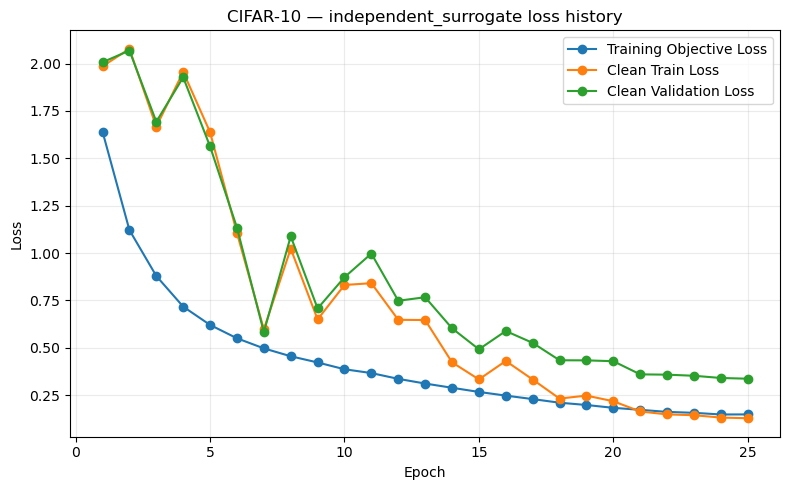

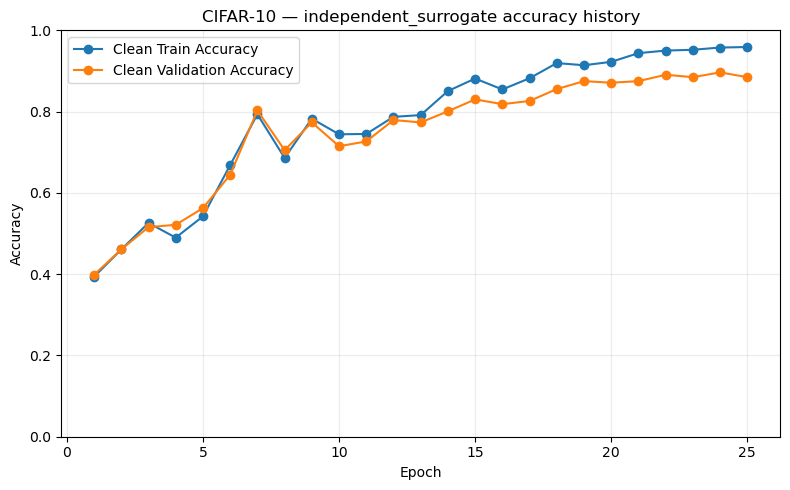

Independent surrogate summary: {'model': 'independent_surrogate', 'architecture': 'CifarSurrogateCNN', 'trained_from_scratch': True, 'loaded_target_weights': False, 'seed': 42, 'train_batch_size': 1024, 'clean_test_accuracy': 0.885, 'clean_test_loss': 0.34245952911376953, 'test_samples': 10000}


,dataset,model,training_variant,clean_accuracy,fgsm_8_255_accuracy,pgd_selected_accuracy,pgd_alpha,pgd_steps,pgd_restarts,stage_training_seconds,...,relative_estimated_peak_gpu_vs_baseline,pipeline_estimated_peak_gpu_mb,relative_pipeline_estimated_peak_vs_baseline,raw_process_peak_gpu_allocated_mb,raw_process_peak_gpu_reserved_mb,gpu_memory_measurement_method,batch_size,adversarial_gradient_steps_per_batch,trainable_parameters,test_samples
0,cifar10,baseline,standard clean training,0.8076,0.0423,0.0002,0.007843,10,3,476.261715,...,1.000000,6781.355438,1.000000,6856.624023,9036.0,model_storage_plus_peak_increment,1024,0,11173962,10000
1,cifar10,fgsm_at,random-start FGSM adversarial fine-tuning,0.6764,0.3156,0.2583,0.007843,10,3,525.336621,...,1.678698,11383.849091,1.678698,11501.795898,14000.0,model_storage_plus_peak_increment,1024,1,11173962,10000
2,cifar10,pgd_at,PGD-7 adversarial fine-tuning,0.6133,0.3701,0.3482,0.007843,10,3,1051.198174,...,1.010752,6854.270966,1.010752,7015.677246,9106.0,model_storage_plus_peak_increment,1024,7,11173962,10000


Independent-surrogate transfer PGD:   0%|          | 0/10 [00:00<?, ?it/s]

,model,surrogate_model,surrogate_architecture,surrogate_is_independent,shared_target_weights,surrogate_clean_accuracy,white_box_pgd_accuracy,transfer_black_box_accuracy,white_box_attack_seconds,transfer_attack_seconds,transfer_batch_size,steps,restarts,white_box_n_samples,n_samples,max_linf
0,baseline,independent_surrogate,CifarSurrogateCNN,True,False,0.885,0.0001,0.3844,338.293073,115.953171,1024,40,5,10000,10000,0.031373
1,fgsm_at,independent_surrogate,CifarSurrogateCNN,True,False,0.885,0.2454,0.6462,338.938652,115.953171,1024,40,5,10000,10000,0.031373
2,pgd_at,independent_surrogate,CifarSurrogateCNN,True,False,0.885,0.3440,0.5980,338.420571,115.953171,1024,40,5,10000,10000,0.031373


EOT full-test audit enabled for cifar10: 10000/10000 samples.

EOT audit | cifar10 | baseline | n=10000


cifar10 | baseline | ordinary PGD:   0% 0/10000 [00:00<?, ?img/s]

... (4 outputs left out)

Ordinary PGD accuracy: 0.2455
EOT-PGD accuracy:      0.2455
EOT - ordinary:        +0.0000
Maximum logit std:      0.000e+00
Time ratio:             10.14x
Interpretation: Inference is empirically deterministic and EOT is consistent with ordinary PGD; no EOT-specific masking evidence.

EOT audit | cifar10 | pgd_at | n=10000


cifar10 | pgd_at | ordinary PGD:   0% 0/10000 [00:00<?, ?img/s]

cifar10 | pgd_at | EOT-PGD:   0% 0/10000 [00:00<?, ?img/s]

Ordinary PGD accuracy: 0.3440
EOT-PGD accuracy:      0.3440
EOT - ordinary:        +0.0000
Maximum logit std:      0.000e+00
Time ratio:             10.15x
Interpretation: Inference is empirically deterministic and EOT is consistent with ordinary PGD; no EOT-specific masking evidence.


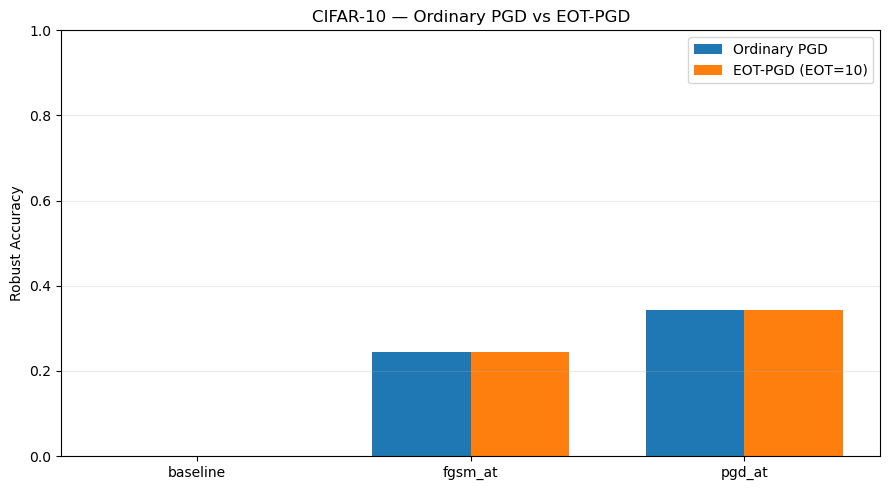

,dataset,model,epsilon,alpha,steps,restarts,eot_gradient_samples,eot_prediction_samples,n_samples,full_official_test_set,...,ordinary_pgd_mean_linf,eot_pgd_mean_linf,ordinary_pgd_seconds,eot_pgd_seconds,eot_to_ordinary_time_ratio,stochasticity_test_samples,repeated_forward_count,mean_sample_max_logit_std,maximum_logit_std,interpretation
0,cifar10,baseline,0.031373,0.003922,40,3,10,20,10000,True,...,0.031373,0.031373,204.124974,2066.150307,10.121987,128,20,0.0,0.0,Inference is empirically deterministic and EOT...
1,cifar10,fgsm_at,0.031373,0.003922,40,3,10,20,10000,True,...,0.031373,0.031373,203.627159,2065.007348,10.141119,128,20,0.0,0.0,Inference is empirically deterministic and EOT...
2,cifar10,pgd_at,0.031373,0.003922,40,3,10,20,10000,True,...,0.031373,0.031373,203.415674,2063.784374,10.145651,128,20,0.0,0.0,Inference is empirically deterministic and EOT...


AutoAttack cifar10:   0%|          | 0/10 [00:00<?, ?it/s]

-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 82.91%
parameters:  10 2 1 1
iteration: 0 - Best loss: 160.842102
iteration: 1 - Best loss: 4453.424805
iteration: 2 - Best loss: 6320.222656
iteration: 3 - Best loss: 7909.696777
iteration: 4 - Best loss: 8313.440430
iteration: 5 - Best loss: 8982.123047
iteration: 6 - Best loss: 9738.161133
iteration: 7 - Best loss: 10190.832031
iteration: 8 - Best loss: 10727.123047
iteration: 9 - Best loss: 11173.504883
restart 0 - robust accuracy: 0.10% - cum. time: 1.6 s
-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 100.00%
parameters:  10 2 1 1
iteration: 0 - Best loss: -0.575739
iteration: 1 - Best loss: -0.355958
iteration: 2 - Best loss: -0.077471
iteration: 3 - Best loss: -0.040905
iteration: 4 - Best loss: -0.026834
iteration: 5 - Best loss: 0.037220
iteration: 6 - Best loss: 0.059484
iteration: 7 - Best loss: 0.059

AutoAttack cifar10:   0%|          | 0/10 [00:00<?, ?it/s]

-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 68.85%
parameters:  10 2 1 1
iteration: 0 - Best loss: 415.225891
iteration: 1 - Best loss: 905.321899
iteration: 2 - Best loss: 954.255249
iteration: 3 - Best loss: 998.784302
iteration: 4 - Best loss: 1011.346985
iteration: 5 - Best loss: 1016.071106
iteration: 6 - Best loss: 1022.237732
iteration: 7 - Best loss: 1027.226562
iteration: 8 - Best loss: 1031.352295
iteration: 9 - Best loss: 1035.041016
restart 0 - robust accuracy: 25.39% - cum. time: 1.5 s
-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 100.00%
parameters:  10 2 1 1
iteration: 0 - Best loss: -158.037506
iteration: 1 - Best loss: -89.906509
iteration: 2 - Best loss: -80.414017
iteration: 3 - Best loss: -71.692383
iteration: 4 - Best loss: -68.337128
iteration: 5 - Best loss: -66.417503
iteration: 6 - Best loss: -65.429207
iteration: 7 - Best loss: 

AutoAttack cifar10:   0%|          | 0/10 [00:00<?, ?it/s]

-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 62.40%
parameters:  10 2 1 1
iteration: 0 - Best loss: 477.844055
iteration: 1 - Best loss: 744.037598
iteration: 2 - Best loss: 761.474609
iteration: 3 - Best loss: 775.438782
iteration: 4 - Best loss: 778.652344
iteration: 5 - Best loss: 779.979004
iteration: 6 - Best loss: 781.087036
iteration: 7 - Best loss: 781.952148
iteration: 8 - Best loss: 782.675659
iteration: 9 - Best loss: 783.273987
restart 0 - robust accuracy: 36.23% - cum. time: 1.1 s
-------------------------- running Linf-attack with epsilon 0.0314 --------------------------
initial accuracy: 100.00%
parameters:  10 2 1 1
iteration: 0 - Best loss: -200.055023
iteration: 1 - Best loss: -116.354721
iteration: 2 - Best loss: -108.129517
iteration: 3 - Best loss: -100.948479
iteration: 4 - Best loss: -98.601921
iteration: 5 - Best loss: -97.306168
iteration: 6 - Best loss: -96.561798
iteration: 7 - Best loss: -96

,model,robust_accuracy,n_samples,full_test_set,suite_version,suite_components,mean_linf,max_linf,attack_seconds
0,baseline,0.0001,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.025333,0.031373,64.144614
1,fgsm_at,0.2169,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.014416,0.031373,1055.309634
2,pgd_at,0.3073,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.009600,0.031373,1237.302624


/opt/conda/lib/python3.12/site-packages/captum/concept/_core/tcav.py:330: UserWarning: Using default classifier for TCAV which keeps input both train and test datasets in the memory. Consider defining your own classifier that doesn't rely heavily on memory, for large number of concepts, by extending `Classifer` abstract class
  self.classifier = DefaultClassifier()
/opt/conda/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)


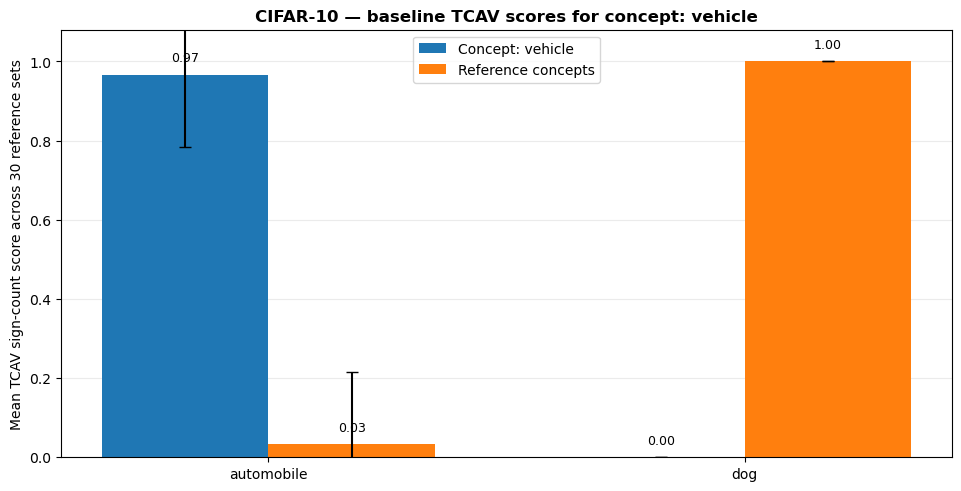

,dataset,model,target_class,target_name,concept,concept_classes,reference_classes,reference_is_disjoint,target_examples_clean_correct_only,target_samples,...,std_reference_sign_count,mean_concept_magnitude,mean_reference_magnitude,random_sets,paired_t_statistic,paired_p_value,paired_effect_size_dz,mean_difference,difference_ci95_low,difference_ci95_high
0,cifar10,baseline,1,automobile,vehicle,"0,8,9","2,3,4,6,7",True,True,128,...,0.182574,2.199191,-2.199191,30,14.0,1.963519e-14,2.556039,0.933333,0.796985,1.069682
1,cifar10,baseline,5,dog,vehicle,"0,8,9","2,3,4,6,7",True,True,128,...,0.000000,-1.466537,1.466537,30,-inf,0.000000e+00,inf,-1.000000,-1.000000,-1.000000


/opt/conda/lib/python3.12/site-packages/captum/concept/_core/tcav.py:330: UserWarning: Using default classifier for TCAV which keeps input both train and test datasets in the memory. Consider defining your own classifier that doesn't rely heavily on memory, for large number of concepts, by extending `Classifer` abstract class
  self.classifier = DefaultClassifier()
/opt/conda/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:430: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)


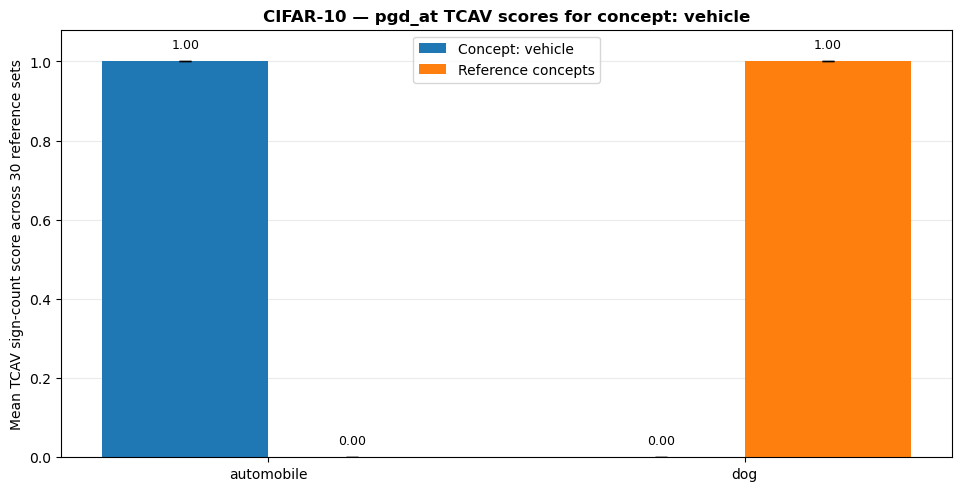

,dataset,model,target_class,target_name,concept,concept_classes,reference_classes,reference_is_disjoint,target_examples_clean_correct_only,target_samples,...,std_reference_sign_count,mean_concept_magnitude,mean_reference_magnitude,random_sets,paired_t_statistic,paired_p_value,paired_effect_size_dz,mean_difference,difference_ci95_low,difference_ci95_high
0,cifar10,pgd_at,1,automobile,vehicle,"0,8,9","2,3,4,6,7",True,True,128,...,0.0,2.044915,-2.044915,30,inf,0.0,inf,1.0,1.0,1.0
1,cifar10,pgd_at,5,dog,vehicle,"0,8,9","2,3,4,6,7",True,True,128,...,0.0,-1.377920,1.377920,30,-inf,0.0,inf,-1.0,-1.0,-1.0


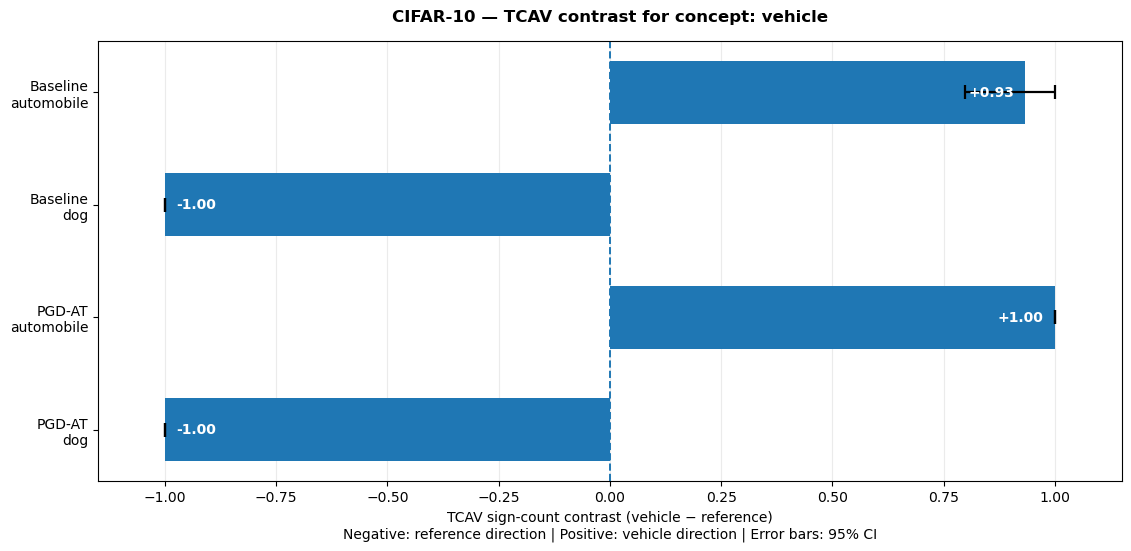

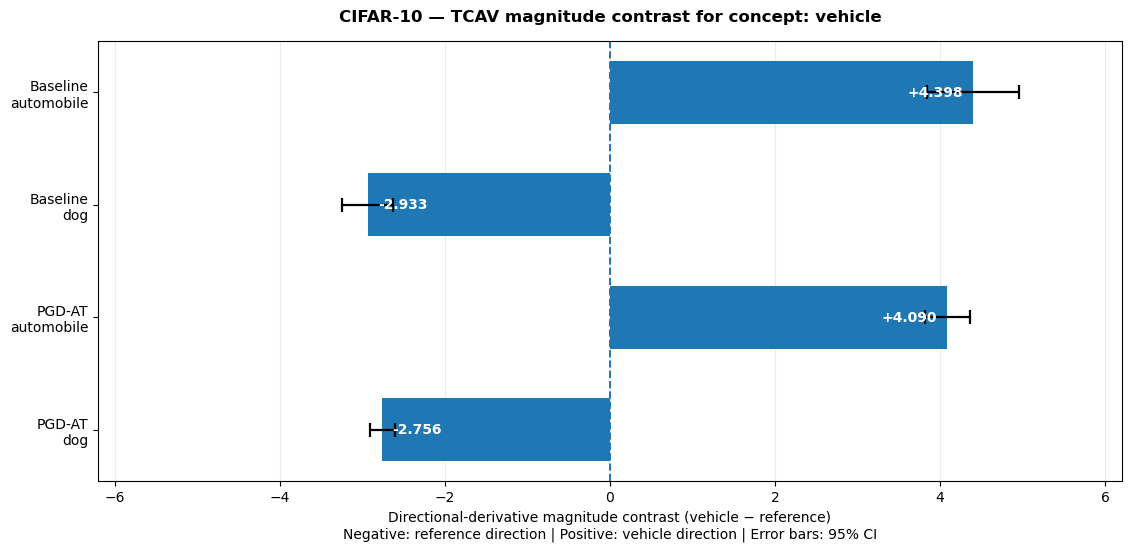

Integrated TCAV contrast outputs:
 - q5_results_corrected_v7_fashion2048_cifar1024/full/cifar10/tcav_contrast_plots/tcav_sign_count_contrast.png
 - q5_results_corrected_v7_fashion2048_cifar1024/full/cifar10/tcav_contrast_plots/tcav_magnitude_contrast.png
 - q5_results_corrected_v7_fashion2048_cifar1024/full/cifar10/tcav_contrast_plots/tcav_contrast_summary.csv


,dataset,model,target_class,target_name,concept,random_reference_sets,mean_concept_sign_count,mean_reference_sign_count,mean_sign_count_contrast,std_sign_count_contrast,...,std_magnitude_contrast,sem_magnitude_contrast,magnitude_ci95_lower,magnitude_ci95_upper,positive_pairs,negative_pairs,zero_pairs,nonzero_pairs,exact_sign_test_p,direction
0,cifar10,baseline,1,automobile,vehicle,30,0.966667,0.033333,0.933333,0.365148,...,1.504343,0.274654,3.836651,4.960113,29,1,0,30,0.0,concept direction dominates
1,cifar10,baseline,5,dog,vehicle,30,0.000000,1.000000,-1.000000,0.000000,...,0.827963,0.151165,-3.242240,-2.623907,0,30,0,30,0.0,reference direction dominates
2,cifar10,pgd_at,1,automobile,vehicle,30,1.000000,0.000000,1.000000,0.000000,...,0.731478,0.133549,3.816691,4.362968,30,0,0,30,0.0,concept direction dominates
3,cifar10,pgd_at,5,dog,vehicle,30,0.000000,1.000000,-1.000000,0.000000,...,0.415294,0.075822,-2.910913,-2.600766,0,30,0,30,0.0,reference direction dominates


In [ ]:
# records baseline Train/Test curves and peak CUDA memory, and runs
# strong PGD, transfer, EOT-PGD, AutoAttack, and TCAV.

EXPERIMENTS: dict[str, dict[str, Any]] = {}
for dataset_name in DATASETS_TO_RUN:
    EXPERIMENTS[dataset_name] = run_dataset_experiment(
        dataset_name,
        force_retrain=FORCE_RETRAIN_ALL,
    )


## Cross-dataset report tables, masking verdicts, and readiness checks

The following cells consolidate all result. The masking verdict combines multiple indicators rather than relying only on the change from weak PGD to strong PGD. In particular, it detects attack-specific overfitting when FGSM accuracy is implausibly higher than clean accuracy or when FGSM and AutoAttack disagree sharply.


In [21]:
comparison_all = pd.concat(
    [
        EXPERIMENTS[name]["comparison"]
        for name in DATASETS_TO_RUN
    ],
    ignore_index=True,
)

autoattack_all = pd.concat(
    [
        EXPERIMENTS[name]["autoattack"].assign(dataset=name)
        for name in DATASETS_TO_RUN
    ],
    ignore_index=True,
)

transfer_all = pd.concat(
    [
        EXPERIMENTS[name]["transfer"].assign(dataset=name)
        for name in DATASETS_TO_RUN
    ],
    ignore_index=True,
)

eot_all = pd.concat(
    [
        EXPERIMENTS[name]["eot"]
        for name in DATASETS_TO_RUN
    ],
    ignore_index=True,
)

tcav_all = pd.concat(
    [
        EXPERIMENTS[name]["tcav"]
        for name in DATASETS_TO_RUN
    ],
    ignore_index=True,
)

tcav_contrast_all = pd.concat(
    [
        EXPERIMENTS[name]["tcav_contrast"]
        for name in DATASETS_TO_RUN
    ],
    ignore_index=True,
)

baseline_epoch_summary = pd.DataFrame(
    [
        {
            "dataset": dataset_name,
            "epochs": int(
                EXPERIMENTS[dataset_name]["baseline_history"]["epoch"].max()
            ),
            "final_train_objective_loss": float(
                EXPERIMENTS[dataset_name]["baseline_history"]
                .iloc[-1]["train_objective_loss"]
            ),
            "final_train_loss": float(
                EXPERIMENTS[dataset_name]["baseline_history"]
                .iloc[-1]["train_loss"]
            ),
            "final_test_loss": float(
                EXPERIMENTS[dataset_name]["baseline_history"]
                .iloc[-1]["test_loss"]
            ),
            "final_train_accuracy": float(
                EXPERIMENTS[dataset_name]["baseline_history"]
                .iloc[-1]["train_accuracy"]
            ),
            "final_test_accuracy": float(
                EXPERIMENTS[dataset_name]["baseline_history"]
                .iloc[-1]["test_accuracy"]
            ),
        }
        for dataset_name in DATASETS_TO_RUN
    ]
)

comparison_all.to_csv(
    RESULTS_ROOT / "all_datasets_defense_comparison.csv",
    index=False,
)
autoattack_all.to_csv(
    RESULTS_ROOT / "all_datasets_autoattack_full.csv",
    index=False,
)
transfer_all.to_csv(
    RESULTS_ROOT / "all_datasets_transfer.csv",
    index=False,
)
eot_all.to_csv(
    RESULTS_ROOT / "all_datasets_eot_full.csv",
    index=False,
)
tcav_all.to_csv(
    RESULTS_ROOT / "all_datasets_tcav_corrected.csv",
    index=False,
)
tcav_contrast_all.to_csv(
    RESULTS_ROOT / "all_datasets_tcav_contrast_summary.csv",
    index=False,
)
baseline_epoch_summary.to_csv(
    RESULTS_ROOT / "baseline_epochwise_train_test_summary.csv",
    index=False,
)

display(comparison_all)
display(baseline_epoch_summary)
display(eot_all)
display(autoattack_all)
display(transfer_all)
display(tcav_all)
display(tcav_contrast_all)


,dataset,model,training_variant,clean_accuracy,fgsm_8_255_accuracy,pgd_selected_accuracy,pgd_alpha,pgd_steps,pgd_restarts,stage_training_seconds,...,relative_estimated_peak_gpu_vs_baseline,pipeline_estimated_peak_gpu_mb,relative_pipeline_estimated_peak_vs_baseline,raw_process_peak_gpu_allocated_mb,raw_process_peak_gpu_reserved_mb,gpu_memory_measurement_method,batch_size,adversarial_gradient_steps_per_batch,trainable_parameters,test_samples
0,fashion_mnist,baseline,standard clean training,0.8928,0.6660,0.6343,0.011765,10,3,51.752612,...,1.000000,727.379929,1.000000,727.382324,1744.0,model_storage_plus_peak_increment,2048,0,454922,10000
1,fashion_mnist,fgsm_at,random-start FGSM adversarial fine-tuning,0.8865,0.7847,0.7695,0.011765,10,3,33.003208,...,1.636890,1190.640671,1.636890,1256.380859,1894.0,model_storage_plus_peak_increment,2048,1,454922,10000
2,fashion_mnist,pgd_at,PGD-7 adversarial fine-tuning,0.8773,0.7971,0.7868,0.011765,10,3,37.721888,...,0.946483,727.379929,1.000000,755.930664,1672.0,model_storage_plus_peak_increment,2048,7,454922,10000
3,cifar10,baseline,standard clean training,0.8076,0.0423,0.0002,0.007843,10,3,476.261715,...,1.000000,6781.355438,1.000000,6856.624023,9036.0,model_storage_plus_peak_increment,1024,0,11173962,10000
4,cifar10,fgsm_at,random-start FGSM adversarial fine-tuning,0.6764,0.3156,0.2583,0.007843,10,3,525.336621,...,1.678698,11383.849091,1.678698,11501.795898,14000.0,model_storage_plus_peak_increment,1024,1,11173962,10000
5,cifar10,pgd_at,PGD-7 adversarial fine-tuning,0.6133,0.3701,0.3482,0.007843,10,3,1051.198174,...,1.010752,6854.270966,1.010752,7015.677246,9106.0,model_storage_plus_peak_increment,1024,7,11173962,10000


,dataset,epochs,final_train_objective_loss,final_train_loss,final_test_loss,final_train_accuracy,final_test_accuracy
0,fashion_mnist,8,0.253713,0.252081,0.293241,0.90874,0.8928
1,cifar10,25,0.463079,0.437419,0.560388,0.84770,0.8076


,dataset,model,epsilon,alpha,steps,restarts,eot_gradient_samples,eot_prediction_samples,n_samples,full_official_test_set,...,ordinary_pgd_mean_linf,eot_pgd_mean_linf,ordinary_pgd_seconds,eot_pgd_seconds,eot_to_ordinary_time_ratio,stochasticity_test_samples,repeated_forward_count,mean_sample_max_logit_std,maximum_logit_std,interpretation
0,fashion_mnist,baseline,0.031373,0.007843,40,3,10,20,10000,True,...,0.031373,0.031373,7.574488,71.124657,9.390028,128,20,0.0,0.0,Inference is empirically deterministic and EOT...
1,fashion_mnist,fgsm_at,0.031373,0.007843,40,3,10,20,10000,True,...,0.031373,0.031373,7.559995,71.182493,9.415679,128,20,0.0,0.0,Inference is empirically deterministic and EOT...
2,fashion_mnist,pgd_at,0.031373,0.007843,40,3,10,20,10000,True,...,0.031373,0.031373,7.750458,71.162914,9.181769,128,20,0.0,0.0,Inference is empirically deterministic and EOT...
3,cifar10,baseline,0.031373,0.003922,40,3,10,20,10000,True,...,0.031373,0.031373,204.124974,2066.150307,10.121987,128,20,0.0,0.0,Inference is empirically deterministic and EOT...
4,cifar10,fgsm_at,0.031373,0.003922,40,3,10,20,10000,True,...,0.031373,0.031373,203.627159,2065.007348,10.141119,128,20,0.0,0.0,Inference is empirically deterministic and EOT...
5,cifar10,pgd_at,0.031373,0.003922,40,3,10,20,10000,True,...,0.031373,0.031373,203.415674,2063.784374,10.145651,128,20,0.0,0.0,Inference is empirically deterministic and EOT...


,model,robust_accuracy,n_samples,full_test_set,suite_version,suite_components,mean_linf,max_linf,attack_seconds,dataset
0,baseline,0.6267,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.008348,0.031373,182.343922,fashion_mnist
1,fgsm_at,0.7642,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.003837,0.031373,197.510478,fashion_mnist
2,pgd_at,0.7818,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.002996,0.031373,179.434673,fashion_mnist
3,baseline,0.0001,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.025333,0.031373,64.144614,cifar10
4,fgsm_at,0.2169,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.014416,0.031373,1055.309634,cifar10
5,pgd_at,0.3073,10000,True,standard,"APGD-CE, APGD-T, FAB-T, Square",0.009600,0.031373,1237.302624,cifar10


,model,surrogate_model,surrogate_architecture,surrogate_is_independent,shared_target_weights,surrogate_clean_accuracy,white_box_pgd_accuracy,transfer_black_box_accuracy,white_box_attack_seconds,transfer_attack_seconds,transfer_batch_size,steps,restarts,white_box_n_samples,n_samples,max_linf,dataset
0,baseline,independent_surrogate,FashionSurrogateCNN,True,False,0.7656,0.6275,0.8659,12.005318,19.436447,2048,40,5,10000,10000,0.031373,fashion_mnist
1,fgsm_at,independent_surrogate,FashionSurrogateCNN,True,False,0.7656,0.7663,0.8721,12.085359,19.436447,2048,40,5,10000,10000,0.031373,fashion_mnist
2,pgd_at,independent_surrogate,FashionSurrogateCNN,True,False,0.7656,0.7855,0.8614,12.066964,19.436447,2048,40,5,10000,10000,0.031373,fashion_mnist
3,baseline,independent_surrogate,CifarSurrogateCNN,True,False,0.8850,0.0001,0.3844,338.293073,115.953171,1024,40,5,10000,10000,0.031373,cifar10
4,fgsm_at,independent_surrogate,CifarSurrogateCNN,True,False,0.8850,0.2454,0.6462,338.938652,115.953171,1024,40,5,10000,10000,0.031373,cifar10
5,pgd_at,independent_surrogate,CifarSurrogateCNN,True,False,0.8850,0.3440,0.5980,338.420571,115.953171,1024,40,5,10000,10000,0.031373,cifar10


,dataset,model,target_class,target_name,concept,concept_classes,reference_classes,reference_is_disjoint,target_examples_clean_correct_only,target_samples,...,std_reference_sign_count,mean_concept_magnitude,mean_reference_magnitude,random_sets,paired_t_statistic,paired_p_value,paired_effect_size_dz,mean_difference,difference_ci95_low,difference_ci95_high
0,fashion_mnist,baseline,9,Ankle boot,footwear,"5,7","1,2,3,4,6,8",True,True,128,...,0.000000,1.493967,-1.493967,30,inf,0.000000e+00,inf,1.000000,1.000000,1.000000
1,fashion_mnist,baseline,0,T-shirt/top,footwear,"5,7","1,2,3,4,6,8",True,True,128,...,0.361313,-0.140463,0.140463,30,-2.502855,1.820484e-02,-0.456957,-0.330208,-0.600041,-0.060376
2,fashion_mnist,pgd_at,9,Ankle boot,footwear,"5,7","1,2,3,4,6,8",True,True,128,...,0.000000,0.583882,-0.583882,30,inf,0.000000e+00,inf,1.000000,1.000000,1.000000
3,fashion_mnist,pgd_at,0,T-shirt/top,footwear,"5,7","1,2,3,4,6,8",True,True,128,...,0.257792,-0.119215,0.119215,30,-7.292495,4.952010e-08,-1.331421,-0.686458,-0.878980,-0.493936
4,cifar10,baseline,1,automobile,vehicle,"0,8,9","2,3,4,6,7",True,True,128,...,0.182574,2.199191,-2.199191,30,14.000000,1.963519e-14,2.556039,0.933333,0.796985,1.069682
5,cifar10,baseline,5,dog,vehicle,"0,8,9","2,3,4,6,7",True,True,128,...,0.000000,-1.466537,1.466537,30,-inf,0.000000e+00,inf,-1.000000,-1.000000,-1.000000
6,cifar10,pgd_at,1,automobile,vehicle,"0,8,9","2,3,4,6,7",True,True,128,...,0.000000,2.044915,-2.044915,30,inf,0.000000e+00,inf,1.000000,1.000000,1.000000
7,cifar10,pgd_at,5,dog,vehicle,"0,8,9","2,3,4,6,7",True,True,128,...,0.000000,-1.377920,1.377920,30,-inf,0.000000e+00,inf,-1.000000,-1.000000,-1.000000


,dataset,model,target_class,target_name,concept,random_reference_sets,mean_concept_sign_count,mean_reference_sign_count,mean_sign_count_contrast,std_sign_count_contrast,...,std_magnitude_contrast,sem_magnitude_contrast,magnitude_ci95_lower,magnitude_ci95_upper,positive_pairs,negative_pairs,zero_pairs,nonzero_pairs,exact_sign_test_p,direction
0,fashion_mnist,baseline,9,Ankle boot,footwear,30,1.000000,0.000000,1.000000,0.000000,...,0.709288,0.129498,2.723082,3.252787,30,0,0,30,1.862645e-09,concept direction dominates
1,fashion_mnist,baseline,0,T-shirt/top,footwear,30,0.334896,0.665104,-0.330208,0.722625,...,0.554159,0.101175,-0.487853,-0.074000,10,20,0,30,9.873715e-02,reference direction dominates
2,fashion_mnist,pgd_at,9,Ankle boot,footwear,30,1.000000,0.000000,1.000000,0.000000,...,0.393714,0.071882,1.020750,1.314780,30,0,0,30,1.862645e-09,concept direction dominates
3,fashion_mnist,pgd_at,0,T-shirt/top,footwear,30,0.156771,0.843229,-0.686458,0.515583,...,0.196243,0.035829,-0.311708,-0.165151,3,26,1,29,1.523644e-05,reference direction dominates
4,cifar10,baseline,1,automobile,vehicle,30,0.966667,0.033333,0.933333,0.365148,...,1.504343,0.274654,3.836651,4.960113,29,1,0,30,5.774200e-08,concept direction dominates
5,cifar10,baseline,5,dog,vehicle,30,0.000000,1.000000,-1.000000,0.000000,...,0.827963,0.151165,-3.242240,-2.623907,0,30,0,30,1.862645e-09,reference direction dominates
6,cifar10,pgd_at,1,automobile,vehicle,30,1.000000,0.000000,1.000000,0.000000,...,0.731478,0.133549,3.816691,4.362968,30,0,0,30,1.862645e-09,concept direction dominates
7,cifar10,pgd_at,5,dog,vehicle,30,0.000000,1.000000,-1.000000,0.000000,...,0.415294,0.075822,-2.910913,-2.600766,0,30,0,30,1.862645e-09,reference direction dominates


In [22]:
def analyze_masking_evidence(
    dataset_name: str,
    model_key: str,
    audit_table: pd.DataFrame,
    comparison_row: pd.Series,
    autoattack_row: pd.Series,
    transfer_row: pd.Series,
    eot_row: pd.Series,
    tolerance: float = 0.01,
) -> dict[str, Any]:
    weakest = audit_table.sort_values(
        ["steps", "restarts"]
    ).iloc[0]
    strongest = audit_table.sort_values(
        ["steps", "restarts"]
    ).iloc[-1]

    weak_accuracy = float(weakest["robust_accuracy"])
    strong_accuracy = float(strongest["robust_accuracy"])
    clean_accuracy = float(comparison_row["clean_accuracy"])
    fgsm_accuracy = float(comparison_row["fgsm_8_255_accuracy"])
    autoattack_accuracy = float(autoattack_row["robust_accuracy"])
    white_box = float(transfer_row["white_box_pgd_accuracy"])
    black_box = float(transfer_row["transfer_black_box_accuracy"])
    ordinary_eot_control = float(eot_row["ordinary_pgd_accuracy"])
    eot_accuracy = float(eot_row["eot_pgd_accuracy"])
    eot_delta = float(eot_row["eot_minus_ordinary_accuracy"])
    maximum_logit_std = float(eot_row["maximum_logit_std"])

    flags = {
        "sudden_weak_to_strong_pgd_collapse": (
            weak_accuracy - strong_accuracy > 0.20
        ),
        "stronger_pgd_unexpectedly_less_effective": (
            strong_accuracy > weak_accuracy + tolerance
        ),
        "fgsm_accuracy_above_clean_accuracy": (
            fgsm_accuracy > clean_accuracy + 0.02
        ),
        "large_fgsm_autoattack_gap": (
            fgsm_accuracy - autoattack_accuracy > 0.20
        ),
        "black_box_stronger_than_white_box": (
            black_box + tolerance < white_box
        ),
        "autoattack_above_clean_accuracy": (
            autoattack_accuracy > clean_accuracy + tolerance
        ),
        "eot_materially_stronger_than_control_pgd": (
            ordinary_eot_control - eot_accuracy > 0.02
        ),
        "eot_unexpectedly_weaker_than_control_pgd": (
            eot_accuracy > ordinary_eot_control + 0.02
        ),
    }

    suspicious = any(flags.values())

    if suspicious:
        verdict = "evidence_of_masking_or_attack_specific_overfitting"
    elif (
        autoattack_accuracy > 0
        and strong_accuracy > 0
        and eot_accuracy > 0
    ):
        verdict = "robustness_supported_by_multiple_attacks"
    else:
        verdict = (
            "no_robustness_detected_but_no_masking_needed_to_explain_failure"
        )

    return {
        "dataset": dataset_name,
        "model": model_key,
        "weak_pgd_accuracy": weak_accuracy,
        "strong_pgd_40x5_accuracy": strong_accuracy,
        "weak_to_strong_drop": weak_accuracy - strong_accuracy,
        "clean_accuracy": clean_accuracy,
        "fgsm_accuracy": fgsm_accuracy,
        "autoattack_accuracy": autoattack_accuracy,
        "white_box_accuracy": white_box,
        "transfer_black_box_accuracy": black_box,
        "ordinary_pgd_eot_control_accuracy": ordinary_eot_control,
        "eot_pgd_accuracy": eot_accuracy,
        "eot_minus_ordinary_accuracy": eot_delta,
        "maximum_repeated_forward_logit_std": maximum_logit_std,
        **flags,
        "suspicious": suspicious,
        "verdict": verdict,
    }


masking_records: list[dict[str, Any]] = []

for dataset_name in DATASETS_TO_RUN:
    for model_key, audit_table in (
        EXPERIMENTS[dataset_name]["gradient_masking"].items()
    ):
        comparison_row = comparison_all.query(
            "dataset == @dataset_name and model == @model_key"
        ).iloc[0]
        autoattack_row = autoattack_all.query(
            "dataset == @dataset_name and model == @model_key"
        ).iloc[0]
        transfer_row = transfer_all.query(
            "dataset == @dataset_name and model == @model_key"
        ).iloc[0]
        eot_row = eot_all.query(
            "dataset == @dataset_name and model == @model_key"
        ).iloc[0]

        masking_records.append(
            analyze_masking_evidence(
                dataset_name=dataset_name,
                model_key=model_key,
                audit_table=audit_table,
                comparison_row=comparison_row,
                autoattack_row=autoattack_row,
                transfer_row=transfer_row,
                eot_row=eot_row,
            )
        )

masking_summary = pd.DataFrame(masking_records)
masking_summary.to_csv(
    RESULTS_ROOT / "gradient_masking_multievidence_summary.csv",
    index=False,
)
display(masking_summary)

report_metrics = (
    comparison_all
    .merge(
        autoattack_all[
            [
                "dataset",
                "model",
                "robust_accuracy",
                "n_samples",
                "suite_version",
                "full_test_set",
            ]
        ].rename(
            columns={
                "robust_accuracy": "autoattack_accuracy",
                "n_samples": "autoattack_samples",
            }
        ),
        on=["dataset", "model"],
        how="left",
    )
    .merge(
        eot_all[
            [
                "dataset",
                "model",
                "ordinary_pgd_accuracy",
                "eot_pgd_accuracy",
                "eot_minus_ordinary_accuracy",
                "n_samples",
                "full_official_test_set",
            ]
        ].rename(columns={"n_samples": "eot_samples"}),
        on=["dataset", "model"],
        how="left",
    )
    .merge(
        masking_summary[
            [
                "dataset",
                "model",
                "strong_pgd_40x5_accuracy",
                "suspicious",
                "verdict",
            ]
        ],
        on=["dataset", "model"],
        how="left",
    )
)

report_metrics["robustness_accuracy_tradeoff"] = (
    report_metrics["clean_accuracy"]
    - report_metrics.groupby("dataset")["clean_accuracy"].transform("first")
)

report_metrics.to_csv(
    RESULTS_ROOT / "REPORT_METRICS_FINAL.csv",
    index=False,
)
display(report_metrics)


,dataset,model,weak_pgd_accuracy,strong_pgd_40x5_accuracy,weak_to_strong_drop,clean_accuracy,fgsm_accuracy,autoattack_accuracy,white_box_accuracy,transfer_black_box_accuracy,...,sudden_weak_to_strong_pgd_collapse,stronger_pgd_unexpectedly_less_effective,fgsm_accuracy_above_clean_accuracy,large_fgsm_autoattack_gap,black_box_stronger_than_white_box,autoattack_above_clean_accuracy,eot_materially_stronger_than_control_pgd,eot_unexpectedly_weaker_than_control_pgd,suspicious,verdict
0,fashion_mnist,baseline,0.6371,0.6271,0.0100,0.8928,0.6660,0.6267,0.6275,0.8659,...,False,False,False,False,False,False,False,False,False,robustness_supported_by_multiple_attacks
1,fashion_mnist,fgsm_at,0.7705,0.7664,0.0041,0.8865,0.7847,0.7642,0.7663,0.8721,...,False,False,False,False,False,False,False,False,False,robustness_supported_by_multiple_attacks
2,fashion_mnist,pgd_at,0.7877,0.7854,0.0023,0.8773,0.7971,0.7818,0.7855,0.8614,...,False,False,False,False,False,False,False,False,False,robustness_supported_by_multiple_attacks
3,cifar10,baseline,0.0007,0.0001,0.0006,0.8076,0.0423,0.0001,0.0001,0.3844,...,False,False,False,False,False,False,False,False,False,robustness_supported_by_multiple_attacks
4,cifar10,fgsm_at,0.3242,0.2460,0.0782,0.6764,0.3156,0.2169,0.2454,0.6462,...,False,False,False,False,False,False,False,False,False,robustness_supported_by_multiple_attacks
5,cifar10,pgd_at,0.3911,0.3441,0.0470,0.6133,0.3701,0.3073,0.3440,0.5980,...,False,False,False,False,False,False,False,False,False,robustness_supported_by_multiple_attacks


,dataset,model,training_variant,clean_accuracy,fgsm_8_255_accuracy,pgd_selected_accuracy,pgd_alpha,pgd_steps,pgd_restarts,stage_training_seconds,...,full_test_set,ordinary_pgd_accuracy,eot_pgd_accuracy,eot_minus_ordinary_accuracy,eot_samples,full_official_test_set,strong_pgd_40x5_accuracy,suspicious,verdict,robustness_accuracy_tradeoff
0,fashion_mnist,baseline,standard clean training,0.8928,0.6660,0.6343,0.011765,10,3,51.752612,...,True,0.6281,0.6281,0.0,10000,True,0.6271,False,robustness_supported_by_multiple_attacks,0.0000
1,fashion_mnist,fgsm_at,random-start FGSM adversarial fine-tuning,0.8865,0.7847,0.7695,0.011765,10,3,33.003208,...,True,0.7668,0.7668,0.0,10000,True,0.7664,False,robustness_supported_by_multiple_attacks,-0.0063
2,fashion_mnist,pgd_at,PGD-7 adversarial fine-tuning,0.8773,0.7971,0.7868,0.011765,10,3,37.721888,...,True,0.7859,0.7859,0.0,10000,True,0.7854,False,robustness_supported_by_multiple_attacks,-0.0155
3,cifar10,baseline,standard clean training,0.8076,0.0423,0.0002,0.007843,10,3,476.261715,...,True,0.0001,0.0001,0.0,10000,True,0.0001,False,robustness_supported_by_multiple_attacks,0.0000
4,cifar10,fgsm_at,random-start FGSM adversarial fine-tuning,0.6764,0.3156,0.2583,0.007843,10,3,525.336621,...,True,0.2455,0.2455,0.0,10000,True,0.2460,False,robustness_supported_by_multiple_attacks,-0.1312
5,cifar10,pgd_at,PGD-7 adversarial fine-tuning,0.6133,0.3701,0.3482,0.007843,10,3,1051.198174,...,True,0.3440,0.3440,0.0,10000,True,0.3441,False,robustness_supported_by_multiple_attacks,-0.1943


In [23]:
def build_report_readiness_table() -> pd.DataFrame:
    checks: list[dict[str, Any]] = []

    def add(name: str, passed: bool, evidence: str) -> None:
        checks.append({
            "check": name,
            "passed": bool(passed),
            "evidence": evidence,
        })

    add(
        "Full execution mode",
        EXECUTION_MODE == "full",
        f"EXECUTION_MODE={EXECUTION_MODE}",
    )

    add(
        "Both deliberately selected image datasets completed",
        set(EXPERIMENTS) == {"fashion_mnist", "cifar10"},
        f"completed={sorted(EXPERIMENTS)}",
    )

    expected_batch_sizes = BATCH_SIZES.copy()
    add(
        "Dataset-specific RTX 3090 batch profile enabled",
        {
            name: DATASET_SPECS[name].batch_size
            for name in DATASETS_TO_RUN
        }
        == expected_batch_sizes,
        (
            "configured_batch_sizes="
            f"{ {name: DATASET_SPECS[name].batch_size for name in DATASETS_TO_RUN} }"
        ),
    )

    for dataset_name in DATASETS_TO_RUN:
        experiment = EXPERIMENTS[dataset_name]

        expected_validation_size = int(
            MODE["validation_size"][dataset_name]
        )
        expected_train_size = {
            "fashion_mnist": 60000 - expected_validation_size,
            "cifar10": 50000 - expected_validation_size,
        }[dataset_name]

        add(
            f"{dataset_name}: deterministic held-out validation split",
            experiment["train_size"] == expected_train_size
            and experiment["validation_size"] == expected_validation_size
            and experiment["official_test_used_for_pgd_selection"] is False
            and experiment["official_test_used_for_model_selection"] is False,
            (
                f"train={experiment['train_size']}, "
                f"validation={experiment['validation_size']}, "
                f"test_used_for_pgd_selection="
                f"{experiment['official_test_used_for_pgd_selection']}, "
                f"test_used_for_model_selection="
                f"{experiment['official_test_used_for_model_selection']}"
            ),
        )

        # Integrated baseline Train/Test epoch curves.
        baseline_history = experiment["baseline_history"]
        baseline_dir = RESULTS_ROOT / dataset_name / "baseline"
        baseline_required_columns = {
            "epoch",
            "train_objective_loss",
            "train_loss",
            "test_loss",
            "train_accuracy",
            "test_accuracy",
        }
        add(
            f"{dataset_name}: baseline Train/Test metrics recorded by epoch",
            baseline_required_columns.issubset(baseline_history.columns)
            and baseline_history["test_loss"].notna().all()
            and baseline_history["test_accuracy"].notna().all()
            and (
                baseline_dir
                / "baseline_train_test_loss_by_epoch.png"
            ).exists()
            and (
                baseline_dir
                / "baseline_train_test_accuracy_by_epoch.png"
            ).exists(),
            (
                f"history_columns={sorted(baseline_history.columns.tolist())}, "
                f"epochs={len(baseline_history)}, "
                f"output_dir={baseline_dir}"
            ),
        )

        # Estimated isolated GPU-memory cost for baseline and defenses.
        comparison = experiment["comparison"]
        required_models = {"baseline", "fgsm_at", "pgd_at"}
        
        required_gpu_columns = {
            "model_storage_mb",
            "gpu_peak_increment_mb",
            "estimated_isolated_peak_gpu_mb",
        }
        
        gpu_columns_exist = required_gpu_columns.issubset(
            comparison.columns
        )
        
        gpu_memory_valid = (
            set(comparison["model"]) == required_models
            and gpu_columns_exist
        )
        
        if torch.cuda.is_available() and gpu_columns_exist:
            gpu_memory_valid = (
                gpu_memory_valid
                and comparison[
                    "model_storage_mb"
                ].notna().all()
                and (
                    comparison["model_storage_mb"] > 0
                ).all()
                and comparison[
                    "gpu_peak_increment_mb"
                ].notna().all()
                and (
                    comparison["gpu_peak_increment_mb"] >= 0
                ).all()
                and comparison[
                    "estimated_isolated_peak_gpu_mb"
                ].notna().all()
                and (
                    comparison[
                        "estimated_isolated_peak_gpu_mb"
                    ]
                    > 0
                ).all()
                and (
                    comparison[
                        "estimated_isolated_peak_gpu_mb"
                    ]
                    >= comparison["model_storage_mb"]
                ).all()
            )
        
        if gpu_columns_exist:
            gpu_evidence = (
                "model_storage_mb="
                f"{comparison['model_storage_mb'].round(2).tolist()}, "
                "training_increment_mb="
                f"{comparison['gpu_peak_increment_mb'].round(2).tolist()}, "
                "estimated_isolated_peak_mb="
                f"{comparison['estimated_isolated_peak_gpu_mb'].round(2).tolist()}"
            )
        else:
            missing_columns = sorted(
                required_gpu_columns
                - set(comparison.columns)
            )
            gpu_evidence = (
                f"missing_columns={missing_columns}, "
                f"available_columns={sorted(comparison.columns.tolist())}"
            )
        
        add(
            (
                f"{dataset_name}: estimated isolated GPU memory "
                "recorded for defense cost"
            ),
            gpu_memory_valid,
            gpu_evidence,
        )

        grid = experiment["pgd_grid"]
        required_pairs = {
            (float(alpha), int(steps))
            for alpha in PGD_ALPHAS
            for steps in PGD_STEPS
        }
        observed_pairs = set(
            zip(
                grid["alpha"].astype(float),
                grid["steps"].astype(int),
            )
        )
        expected_search_samples = (
            expected_validation_size
            if MODE["pgd_search_samples"][dataset_name] is None
            else min(
                int(MODE["pgd_search_samples"][dataset_name]),
                expected_validation_size,
            )
        )
        grid_is_validation_only = (
            "search_split" in grid.columns
            and (
                grid["search_split"]
                == "heldout_validation_from_official_train"
            ).all()
            and (
                grid["official_test_used_for_selection"] == False
            ).all()
            and (
                grid["n_samples"] == expected_search_samples
            ).all()
        )

        add(
            f"{dataset_name}: complete nine-setting validation PGD grid",
            required_pairs == observed_pairs
            and (grid["restarts"] >= 3).all()
            and grid_is_validation_only,
            (
                f"rows={len(grid)}, "
                f"minimum_restarts={int(grid['restarts'].min())}, "
                f"search_samples={sorted(grid['n_samples'].unique().tolist())}"
            ),
        )

        # Explicit EOT-PGD on all models and complete test set.
        eot = experiment["eot"]
        expected_test_size = experiment["test_size"]

        # Strong-PGD step/restart audit must use the full test set.
        gradient_audits = experiment["gradient_masking"]
        
        strong_audit_full_test = (
            set(gradient_audits.keys())
            == {"baseline", "fgsm_at", "pgd_at"}
            and all(
                "n_samples" in table.columns
                and (
                    table["n_samples"]
                    == expected_test_size
                ).all()
                for table in gradient_audits.values()
            )
        )
        
        add(
            (
                f"{dataset_name}: strong PGD audits use "
                "the complete official test set"
            ),
            strong_audit_full_test,
            (
                "sample_counts="
                + str({
                    model_key: sorted(
                        table["n_samples"]
                        .astype(int)
                        .unique()
                        .tolist()
                    )
                    for model_key, table
                    in gradient_audits.items()
                })
            ),
        )
        
        # White-box and independent-surrogate transfer attacks must use
        # the same complete official test set.
        transfer = experiment["transfer"]

        transfer_full_test = (
            set(transfer["model"])
            == {"baseline", "fgsm_at", "pgd_at"}
            and (transfer["n_samples"] == expected_test_size).all()
            and (
                transfer["white_box_n_samples"]
                == expected_test_size
            ).all()
        )

        add(
            (
                f"{dataset_name}: white-box and independent-transfer PGD "
                "use the complete official test set"
            ),
            transfer_full_test,
            (
                f"transfer_counts={transfer['n_samples'].astype(int).tolist()}, "
                f"white_box_counts="
                f"{transfer['white_box_n_samples'].astype(int).tolist()}"
            ),
        )

        surrogate_summary = experiment["surrogate_summary"]
        independent_transfer_valid = (
            transfer["surrogate_is_independent"].all()
            and (~transfer["shared_target_weights"]).all()
            and transfer["surrogate_model"].eq(
                "independent_surrogate"
            ).all()
            and surrogate_summary["trained_from_scratch"] is True
            and surrogate_summary["loaded_target_weights"] is False
            and surrogate_summary["clean_test_accuracy"] > 0.50
            and (
                surrogate_summary["train_batch_size"]
                == expected_batch_sizes[dataset_name]
            )
            and (
                transfer["transfer_batch_size"]
                == expected_batch_sizes[dataset_name]
            ).all()
        )
        add(
            f"{dataset_name}: independently trained transfer surrogate",
            independent_transfer_valid,
            (
                f"architecture={surrogate_summary['architecture']}, "
                f"clean_accuracy="
                f"{surrogate_summary['clean_test_accuracy']:.4f}, "
                f"train_batch="
                f"{surrogate_summary['train_batch_size']}"
            ),
        )
        add(
            f"{dataset_name}: explicit full-test EOT-PGD on all models",
            set(eot["model"]) == set(EOT_MODEL_KEYS)
            and (eot["steps"] == EOT_STEPS).all()
            and (eot["restarts"] == EOT_RESTARTS).all()
            and (
                eot["eot_gradient_samples"]
                == EOT_GRAD_SAMPLES
            ).all()
            and (
                eot["eot_prediction_samples"]
                == EOT_PREDICTION_SAMPLES
            ).all()
            and (eot["n_samples"] == expected_test_size).all()
            and eot["full_official_test_set"].all(),
            (
                f"test_size={expected_test_size}, "
                f"attacked_counts={eot['n_samples'].tolist()}, "
                f"EOT={EOT_GRAD_SAMPLES}"
            ),
        )

        aa = experiment["autoattack"]
        add(
            f"{dataset_name}: full standard AutoAttack on all models",
            set(aa["model"]) == set(AUTOATTACK_MODEL_KEYS)
            and (aa["suite_version"] == "standard").all()
            and aa["full_test_set"].all()
            and (aa["n_samples"] == expected_test_size).all(),
            (
                f"test_size={expected_test_size}, "
                f"attacked_counts={aa['n_samples'].tolist()}"
            ),
        )

        tcav = experiment["tcav"]
        expected_tcav_rows = (
            len(TCAV_MODELS)
            * len(DATASET_SPECS[dataset_name].tcav_target_classes)
        )
        add(
            f"{dataset_name}: corrected TCAV design and execution",
            len(tcav) == expected_tcav_rows
            and (tcav["random_sets"] >= 10).all()
            and tcav["reference_is_disjoint"].all()
            and tcav["target_examples_clean_correct_only"].all()
            and (tcav["target_samples"] > 0).all(),
            (
                f"rows={len(tcav)}, "
                f"random_sets={sorted(tcav['random_sets'].unique().tolist())}"
            ),
        )

        tcav_contrast = experiment["tcav_contrast"]
        contrast_directory = (
            RESULTS_ROOT / dataset_name / "tcav_contrast_plots"
        )
        add(
            f"{dataset_name}: integrated TCAV contrast plots",
            len(tcav_contrast) == expected_tcav_rows
            and (
                tcav_contrast["random_reference_sets"] >= 10
            ).all()
            and (
                contrast_directory
                / "tcav_sign_count_contrast.png"
            ).exists()
            and (
                contrast_directory
                / "tcav_magnitude_contrast.png"
            ).exists(),
            (
                f"rows={len(tcav_contrast)}, "
                f"output_directory={contrast_directory}"
            ),
        )

    return pd.DataFrame(checks)


readiness = build_report_readiness_table()
readiness.to_csv(
    RESULTS_ROOT / "REPORT_READINESS_CHECK.csv",
    index=False,
)
display(readiness)

if not readiness["passed"].all():
    failed = readiness.loc[
        ~readiness["passed"],
        ["check", "evidence"],
    ]
    raise RuntimeError(
        "The notebook is not report-ready. Failed checks:\n"
        + failed.to_string(index=False)
    )


def generate_report_notes() -> str:
    lines = [
        "# Question 5 — Automatically Generated Evidence Notes",
        "",
        f"- Seed: {SEED}",
        f"- Execution mode: {EXECUTION_MODE}",
        f"- Datasets: {', '.join(DATASETS_TO_RUN)}",
        (
            "- Baseline epoch reporting: clean Train/Test loss and accuracy "
            "were measured after every baseline epoch. Test values were "
            "reporting-only and never used for optimization or selection."
        ),
        (
            "- PGD selection: the complete nine-setting grid used only "
            "held-out validation data."
        ),
        (
            "- Defense computational cost: incremental training time, total "
            "pipeline time, model storage, incremental training GPU memory, "
            "estimated isolated peak GPU memory, and adversarial gradient "
            "steps per batch were recorded."
        ),
        (
            f"- Dataset-consistent DataLoader batch sizes: {BATCH_SIZES}. "
            "The configured batch for each dataset is used across all "
            "training and evaluation pipelines, and the last incomplete "
            "batch is retained."
        ),
        (
            f"- EOT-PGD: {EOT_GRAD_SAMPLES} gradient samples per step, "
            f"{EOT_PREDICTION_SAMPLES} prediction samples, "
            f"{EOT_STEPS} steps, and {EOT_RESTARTS} restarts "
            "on the complete official test set."
        ),
        (
            f"- AutoAttack: standard suite "
            f"({', '.join(AUTOATTACK_COMPONENTS)}) "
            "on the complete official test set."
        ),
        (
            f"- TCAV: {TCAV_RANDOM_SETS} independent references; "
            "disjoint classes; clean-correct target examples."
        ),
        "",
        "## Model-level numerical evidence",
        "",
    ]

    for row in report_metrics.itertuples(index=False):
        lines.append(
            f"- {row.dataset} / {row.model}: "
            f"clean={row.clean_accuracy:.4f}, "
            f"FGSM={row.fgsm_8_255_accuracy:.4f}, "
            f"selected-PGD={row.pgd_selected_accuracy:.4f}, "
            f"strong-PGD-40x5={row.strong_pgd_40x5_accuracy:.4f}, "
            f"EOT-PGD={row.eot_pgd_accuracy:.4f}, "
            f"AutoAttack={row.autoattack_accuracy:.4f}, "
            f"training-time={row.stage_training_seconds:.2f}s, "
            f"estimated-isolated-peak-GPU="
            f"{row.estimated_isolated_peak_gpu_mb:.2f}MB; "
            f"verdict={row.verdict}."
        )

    lines.extend([
        "",
        "## Corrected TCAV evidence",
        "",
    ])

    for row in tcav_all.itertuples(index=False):
        lines.append(
            f"- {row.dataset} / {row.model} / "
            f"target={row.target_name}: "
            f"concept={row.concept}, "
            f"mean sign-count={row.mean_concept_sign_count:.4f}, "
            f"reference={row.mean_reference_sign_count:.4f}, "
            f"p={row.paired_p_value:.4g}, "
            f"dz={row.paired_effect_size_dz:.4f}."
        )

    lines.extend([
        "",
        "## Mandatory interpretation rules",
        "",
        (
            "1. Use AutoAttack, EOT-PGD, and strong PGD as the main "
            "robustness evidence, not FGSM alone."
        ),
        (
            "2. Explicitly label any model flagged as attack-specific "
            "overfitting or gradient masking as an unsuccessful defense."
        ),
        (
            "3. Report both incremental defense fine-tuning time and total "
            "pipeline time, together with estimated isolated peak GPU memory."
        ),
        (
            "4. State that baseline test metrics were recorded by epoch "
            "only for reporting and were not used for model or attack "
            "selection."
        ),
        (
            "5. State that PGD alpha and steps were selected on held-out "
            "validation data."
        ),
        (
            "6. Interpret TCAV as sensitivity to a user-defined concept, "
            "not as proof of causal reasoning."
        ),
        "",
        (
            "All report tables, figures, checkpoints, GPU-memory metadata, "
            "EOT artifacts, TCAV artifacts, and readiness checks are stored "
            "under the v7 Fashion-2048 / CIFAR-1024 independent-surrogate results directory."
        ),
    ])

    return "\n".join(lines)


report_notes = generate_report_notes()
(RESULTS_ROOT / "REPORT_NOTES_FINAL.md").write_text(
    report_notes,
    encoding="utf-8",
)
print(report_notes)
print("\nALL REPORT-READINESS CHECKS PASSED.")


,check,passed,evidence
0,Full execution mode,True,EXECUTION_MODE=full
1,Both deliberately selected image datasets comp...,True,"completed=['cifar10', 'fashion_mnist']"
2,Dataset-specific RTX 3090 batch profile enabled,True,"configured_batch_sizes={'fashion_mnist': 2048,..."
3,fashion_mnist: deterministic held-out validati...,True,"train=50000, validation=10000, test_used_for_p..."
4,fashion_mnist: baseline Train/Test metrics rec...,True,"history_columns=['elapsed_seconds', 'epoch', '..."
5,fashion_mnist: estimated isolated GPU memory r...,True,"model_storage_mb=[1.74, 1.74, 1.74], training_..."
6,fashion_mnist: complete nine-setting validatio...,True,"rows=9, minimum_restarts=3, search_samples=[10..."
7,fashion_mnist: strong PGD audits use the compl...,True,"sample_counts={'baseline': [10000], 'fgsm_at':..."
8,fashion_mnist: white-box and independent-trans...,True,"transfer_counts=[10000, 10000, 10000], white_b..."
9,fashion_mnist: independently trained transfer ...,True,"architecture=FashionSurrogateCNN, clean_accura..."


# Question 5 — Automatically Generated Evidence Notes

- Seed: 42
- Execution mode: full
- Datasets: fashion_mnist, cifar10
- Baseline epoch reporting: clean Train/Test loss and accuracy were measured after every baseline epoch. Test values were reporting-only and never used for optimization or selection.
- PGD selection: the complete nine-setting grid used only held-out validation data.
- Defense computational cost: incremental training time, total pipeline time, model storage, incremental training GPU memory, estimated isolated peak GPU memory, and adversarial gradient steps per batch were recorded.
- Dataset-consistent DataLoader batch sizes: {'fashion_mnist': 2048, 'cifar10': 1024}. The configured batch for each dataset is used across all training and evaluation pipelines, and the last incomplete batch is retained.
- EOT-PGD: 10 gradient samples per step, 20 prediction samples, 40 steps, and 3 restarts on the complete official test set.
- AutoAttack: standard suite (APGD-CE, APGD-T

## References

- Goodfellow, Shlens, and Szegedy, **Explaining and Harnessing Adversarial Examples** (FGSM), ICLR 2015: https://arxiv.org/abs/1412.6572
- Madry et al., **Towards Deep Learning Models Resistant to Adversarial Attacks** (PGD and adversarial training), ICLR 2018: https://arxiv.org/abs/1706.06083
- Wong, Rice, and Kolter, **Fast is Better than Free: Revisiting Adversarial Training**, ICLR 2020: https://arxiv.org/abs/2001.03994
- Athalye, Carlini, and Wagner, **Obfuscated Gradients Give a False Sense of Security** (EOT and gradient-masking evaluation), ICML 2018: https://arxiv.org/abs/1802.00420
- Croce and Hein, **Reliable Evaluation of Adversarial Robustness with an Ensemble of Diverse Parameter-Free Attacks** (AutoAttack), ICML 2020: https://arxiv.org/abs/2003.01690
- Kim et al., **Interpretability Beyond Feature Attribution: Quantitative Testing with Concept Activation Vectors (TCAV)**, ICML 2018: https://arxiv.org/abs/1711.11279
- torchattacks documentation and source for the standard AutoAttack wrapper: https://adversarial-attacks-pytorch.readthedocs.io/
- Captum TCAV documentation and tutorials: https://captum.ai/


In [24]:
submission_manifest = {
    "notebook_version": "corrected_v7_final_fashion2048_cifar1024",
    "seed": SEED,
    "execution_mode": EXECUTION_MODE,
    "force_retrain_all": FORCE_RETRAIN_ALL,
    "datasets": DATASETS_TO_RUN,
    "hardware_profile": {
        "target_gpu": "NVIDIA RTX 3090 class / 24 GB VRAM",
        "host_ram": "32 GB",
        "batch_sizes": {
            name: DATASET_SPECS[name].batch_size
            for name in DATASETS_TO_RUN
        },
        "dataloader_workers": DATALOADER_WORKERS,
        "tf32_enabled": torch.cuda.is_available(),
    },
    "data_protocol": {
        "validation_source": "held_out_from_official_training_partition",
        "split_is_stratified": True,
        "validation_sizes": MODE["validation_size"],
        "official_test_evaluated_each_baseline_epoch": True,
        "official_test_metrics_role": "reporting_only",
        "official_test_used_for_model_selection": False,
        "official_test_used_for_pgd_selection": False,
    },
    "baseline_epoch_curves": {
        "integrated_into_main_training": True,
        "separate_replay_required": False,
        "train_loss_definition": "clean_evaluation_cross_entropy",
        "test_loss_definition": "clean_evaluation_cross_entropy",
    },
    "defense_cost": {
        "time_metrics": [
            "stage_training_seconds",
            "total_pipeline_seconds",
        ],
        "gpu_memory_metrics": [
            "model_storage_mb",
            "gpu_peak_increment_mb",
            "estimated_isolated_peak_gpu_mb",
            "raw_process_peak_gpu_allocated_mb",
        ],

        "primary_gpu_memory_metric": (
            "estimated_isolated_peak_gpu_mb"
        ),

        "gpu_memory_estimation_formula": (
            "model_storage_mb + "
            "gpu_peak_increment_mb"
        ),

        "raw_peak_used_for_direct_comparison": False,
        "ram_memory_reported": False,
    },
    "pgd_grid": {
        "alphas": PGD_ALPHAS,
        "steps": PGD_STEPS,
        "restarts": PGD_SEARCH_RESTARTS,
        "selection_split": "heldout_validation_from_official_train",
    },
    "eot": {
        "models": EOT_MODEL_KEYS,
        "gradient_samples": EOT_GRAD_SAMPLES,
        "prediction_samples": EOT_PREDICTION_SAMPLES,
        "steps": EOT_STEPS,
        "restarts": EOT_RESTARTS,
        "full_test_set_required": EXECUTION_MODE == "full",
    },
    "independent_transfer_surrogate": {
        "trained_from_scratch": True,
        "loads_target_weights": False,
        "different_architecture_from_targets": True,
        "generated_once_per_batch_for_all_targets": True,
        "training_batch_sizes": BATCH_SIZES,
        "attack_batch_sizes": BATCH_SIZES,
        "models_remain_on_device": True,
        "models_moved_to_cpu_between_stages": False,
    },
    "autoattack": {
        "version": AUTOATTACK_VERSION,
        "components": AUTOATTACK_COMPONENTS,
        "full_test_set_required": True,
    },
    "tcav": {
        "models": TCAV_MODELS,
        "random_reference_sets": TCAV_RANDOM_SETS,
        "disjoint_class_sets": True,
        "clean_correct_targets_only": True,
    },
    "results_root": str(RESULTS_ROOT),
    "report_ready": bool(readiness["passed"].all()),
}

(RESULTS_ROOT / "submission_manifest.json").write_text(
    json.dumps(
        submission_manifest,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

display(pd.DataFrame([submission_manifest]))


,notebook_version,seed,execution_mode,force_retrain_all,datasets,hardware_profile,data_protocol,baseline_epoch_curves,defense_cost,pgd_grid,eot,independent_transfer_surrogate,autoattack,tcav,results_root,report_ready
0,corrected_v7_final_fashion2048_cifar1024,42,full,True,"[fashion_mnist, cifar10]",{'target_gpu': 'NVIDIA RTX 3090 class / 24 GB ...,{'validation_source': 'held_out_from_official_...,"{'integrated_into_main_training': True, 'separ...","{'time_metrics': ['stage_training_seconds', 't...","{'alphas': [0.00392156862745098, 0.00784313725...","{'models': ['baseline', 'fgsm_at', 'pgd_at'], ...","{'trained_from_scratch': True, 'loads_target_w...","{'version': 'standard', 'components': ('APGD-C...","{'models': ['baseline', 'pgd_at'], 'random_ref...",q5_results_corrected_v7_fashion2048_cifar1024/...,True
